# Final Project: InspectRank - Prioritizing Chicago Restaurant Inspections

**Course:** ADSP 32021 Machine Learning Operations, University of Chicago M.S. in Applied Data Science<br>
**Team:** Brooke Rios, John Henry Oliphant, Mpiira Tabuti<br>
**Repository:** https://github.com/brookerios20/chicago-inspection-ranking-mlops

**How to read this notebook**

This notebook walks through the whole project in the order it was built. The pipeline code itself lives in `src/` and is run by `run_data.py` (data stage, versioned with DVC) and `pipeline.py` (training stage, orchestrated with Prefect). Under each course session, `%%writefile` cells write a copy of the files that belong to that session into a folder named after the session (for example `Session 2 - Data-centric AI ingestion, versioning, validation, privacy/`), so the code can be read step by step next to the explanation. The pipeline always runs the original files in `src/`; the session folders are a reading aid.

**Notebook structure**

The notebook follows the four stages of the project brief. Each stage contains subsections named after the course sessions whose tools and ideas it uses.

1. **Part A: Data Ingestion & Baselines** (Sessions 1 and 2): problem framing, data ingestion, versioning, validation, exploratory data analysis, the train/test split and the baselines
2. **Part B: Pipeline Automation & Experiment Tracking** (Sessions 3 and 4): orchestration, experiment tracking, AutoML and the model registry
3. **Part C: Containerization & Deployment** (Sessions 5, 6 and 7): the prediction API, containerization, explainability, fairness checks and testing
4. **Part D: Production Monitoring & Drift Simulation** (Sessions 7, 8 and 9): monitoring, drift simulation, governance and logging

# A. Data Ingestion & Baselines

### 0. Dependencies, constants, and helpers

In [1]:
# This cell turns on automatic reloading: if a project .py file changes while the notebook is open,
# the notebook uses the new version right away, without restarting the kernel.
%load_ext autoreload
%autoreload 2

In [2]:
# This cell imports the libraries used in the notebook and makes the team's src/ package importable
# by adding the repository folder to Python's search path. All settings (paths, dates, the metric's k,
# feature lists) come from src/config.py, so the notebook and the pipeline share one set of values.
import json
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from src import config
from src.ingest import load_snapshot
from src.split import load_split

# Keeps the notice MLflow prints on import out of the saved outputs
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

# Display settings
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

### Session 1: DevOps to MLOps, CI/CD, basic serving

Session 1 covered how MLOps grows out of DevOps: framing the problem, choosing a metric that matches the business need, naming the risks of ML systems, and laying out the system's architecture. The write-up below is saved as `problem_statement_and_architecture.md` in the `Session 1 - DevOps to MLOps, CI-CD, basic serving/` folder, then displayed.

In [3]:
%%writefile "../Session 1 - DevOps to MLOps, CI-CD, basic serving/problem_statement_and_architecture.md"
# Session 1: DevOps to MLOps, CI/CD, basic serving

#### 1.1 Problem statement

The City of Chicago inspects thousands of restaurants every year, but it has a limited number of inspectors. Since not every restaurant can be visited at once, the order of visits matters: if the restaurants most likely to have problems are visited first, more health risks are caught earlier with the same staff.

InspectRank predicts the probability that a restaurant will fail an inspection and uses these probabilities to rank the week's routine inspections from highest to lowest risk. Inspectors would then work down the list.

#### 1.2 Prediction target

Each row of the Food Inspections dataset is one inspection. The target `fail` is 1 when the result is "Fail" and 0 when it is "Pass" or "Pass w/ Conditions". Results that record no inspection outcome ("Out of Business", "No Entry", "Not Ready", "Business Not Located") are removed.

Every feature is built only from inspections on earlier days, so the model never sees information from the visit it is predicting. "Fail" alone was chosen over "Fail or Pass w/ Conditions" because, as the team's EDA found, the combined rate more than doubles after the July 2018 food code change, which would give the model years of change that has nothing to do with how restaurants behave.

#### 1.3 Evaluation metric: weekly precision@k

The city can only reorder its routine ("canvass") inspections; complaint, license and re-inspection visits are triggered by events. So each week the model ranks that week's canvass inspections, the top k are counted as visited, and the metric is the share of those visits that find a failing restaurant, pooled over all weeks of the evaluation window.

k stands in for inspector capacity: it is 10% of the median number of canvass inspections per week in the training period (93), so **k = 9 visits per week**. The value is computed from the data, so it updates if the scope or the data snapshot changes.

Overall accuracy would be a poor fit here. About 23% of inspections fail, so a model that predicts "pass" for everyone is already about 77% accurate while being useless for choosing where to send inspectors. Precision@k measures what the city actually cares about: how many of a week's visits find a problem. ROC-AUC, PR-AUC, precision at 5%, 10% and 20% of the window, and lift per 100 visits are reported alongside it.

#### 1.4 Baselines

A model is only worth deploying if it ranks inspections better than simple rules the city could use without machine learning. The team scored random ranking, single-feature rules (the city's risk category, the previous result, the restaurant's earlier fails, the ZIP code's fail rate) and two logistic regressions. They are shown in Session 2 after the data pipeline runs. The best baseline (a logistic regression) becomes the bar that a trained model must clear before it is registered (Part B).

#### 1.5 MLOps risks for this project

The Lecture 1 discussion of hidden technical debt in ML systems (Sculley et al., 2015) points to a few risks that seem especially relevant here:

- **Hidden feedback loop:** if the city follows the model's ranking, the restaurants the model rates as risky are inspected more often, so future training data contains more records about them. Over time, the model could end up learning from its own choices instead of from the real condition of all restaurants.
- **External data dependency:** the data comes from the city's open data portal, which the project does not control. The 2018 change in violation codes is a real example of the source data changing underneath a model, which is why the monitoring in Part D is needed.
- **Configuration debt:** every date, path, threshold and feature list lives in one file, `src/config.py`, so a change made there applies to the whole pipeline instead of being scattered through the code.

#### 1.6 System architecture

The project follows the three tiers of the ML lifecycle from Lecture 1:

| Lifecycle tier | What it covers | Tools in this project | Where in this notebook |
|---|---|---|---|
| DataOps | ingestion, validation, versioning, features, EDA | Python rules, DVC with a shared Google Drive remote | Part A |
| ModelOps | training pipeline, experiment tracking, AutoML, model registry | Prefect, FLAML, MLflow | Part B |
| Deployment | prediction API, container, monitoring | FastAPI, Docker, Evidently | Parts C and D |

The full diagram is in `docs/architecture.md`:

```
Chicago Data Portal (4ijn-s7e5)
        |  CSV export or API, cut at 2026-10-29
        v
Data pipeline (DVC):  ingest -> validate -> clean -> features -> split -> baselines
        |  data/processed/{train,valid,test,drift_pre2018}.parquet
        v
Training pipeline (Prefect):  update_data -> load_inputs -> search_version (v1, v2)
                              -> choose_and_gate -> register_model -> write_reports
        |                                   |
        v                                   v
   MLflow tracking                    MLflow Model Registry (models:/inspection-ranker@production)
                                            |
                                            v
                         export_model.py -> Serving API (Docker, FastAPI) -> prediction log
                                            |
                                            v
                         Monitoring (Evidently) against results/reference.parquet
```

Overwriting ../Session 1 - DevOps to MLOps, CI-CD, basic serving/problem_statement_and_architecture.md


In [4]:
# This cell displays the Session 1 write-up saved by the cell above as formatted text, so it can be
# read here in the notebook as well as in the Session 1 folder.
display(Markdown(Path("../Session 1 - DevOps to MLOps, CI-CD, basic serving/problem_statement_and_architecture.md").read_text(encoding="utf-8")))

# Session 1: DevOps to MLOps, CI/CD, basic serving

#### 1.1 Problem statement

The City of Chicago inspects thousands of restaurants every year, but it has a limited number of inspectors. Since not every restaurant can be visited at once, the order of visits matters: if the restaurants most likely to have problems are visited first, more health risks are caught earlier with the same staff.

InspectRank predicts the probability that a restaurant will fail an inspection and uses these probabilities to rank the week's routine inspections from highest to lowest risk. Inspectors would then work down the list.

#### 1.2 Prediction target

Each row of the Food Inspections dataset is one inspection. The target `fail` is 1 when the result is "Fail" and 0 when it is "Pass" or "Pass w/ Conditions". Results that record no inspection outcome ("Out of Business", "No Entry", "Not Ready", "Business Not Located") are removed.

Every feature is built only from inspections on earlier days, so the model never sees information from the visit it is predicting. "Fail" alone was chosen over "Fail or Pass w/ Conditions" because, as the team's EDA found, the combined rate more than doubles after the July 2018 food code change, which would give the model years of change that has nothing to do with how restaurants behave.

#### 1.3 Evaluation metric: weekly precision@k

The city can only reorder its routine ("canvass") inspections; complaint, license and re-inspection visits are triggered by events. So each week the model ranks that week's canvass inspections, the top k are counted as visited, and the metric is the share of those visits that find a failing restaurant, pooled over all weeks of the evaluation window.

k stands in for inspector capacity: it is 10% of the median number of canvass inspections per week in the training period (93), so **k = 9 visits per week**. The value is computed from the data, so it updates if the scope or the data snapshot changes.

Overall accuracy would be a poor fit here. About 23% of inspections fail, so a model that predicts "pass" for everyone is already about 77% accurate while being useless for choosing where to send inspectors. Precision@k measures what the city actually cares about: how many of a week's visits find a problem. ROC-AUC, PR-AUC, precision at 5%, 10% and 20% of the window, and lift per 100 visits are reported alongside it.

#### 1.4 Baselines

A model is only worth deploying if it ranks inspections better than simple rules the city could use without machine learning. The team scored random ranking, single-feature rules (the city's risk category, the previous result, the restaurant's earlier fails, the ZIP code's fail rate) and two logistic regressions. They are shown in Session 2 after the data pipeline runs. The best baseline (a logistic regression) becomes the bar that a trained model must clear before it is registered (Part B).

#### 1.5 MLOps risks for this project

The Lecture 1 discussion of hidden technical debt in ML systems (Sculley et al., 2015) points to a few risks that seem especially relevant here:

- **Hidden feedback loop:** if the city follows the model's ranking, the restaurants the model rates as risky are inspected more often, so future training data contains more records about them. Over time, the model could end up learning from its own choices instead of from the real condition of all restaurants.
- **External data dependency:** the data comes from the city's open data portal, which the project does not control. The 2018 change in violation codes is a real example of the source data changing underneath a model, which is why the monitoring in Part D is needed.
- **Configuration debt:** every date, path, threshold and feature list lives in one file, `src/config.py`, so a change made there applies to the whole pipeline instead of being scattered through the code.

#### 1.6 System architecture

The project follows the three tiers of the ML lifecycle from Lecture 1:

| Lifecycle tier | What it covers | Tools in this project | Where in this notebook |
|---|---|---|---|
| DataOps | ingestion, validation, versioning, features, EDA | Python rules, DVC with a shared Google Drive remote | Part A |
| ModelOps | training pipeline, experiment tracking, AutoML, model registry | Prefect, FLAML, MLflow | Part B |
| Deployment | prediction API, container, monitoring | FastAPI, Docker, Evidently | Parts C and D |

The full diagram is in `docs/architecture.md`:

```
Chicago Data Portal (4ijn-s7e5)
        |  CSV export or API, cut at 2026-10-29
        v
Data pipeline (DVC):  ingest -> validate -> clean -> features -> split -> baselines
        |  data/processed/{train,valid,test,drift_pre2018}.parquet
        v
Training pipeline (Prefect):  update_data -> load_inputs -> search_version (v1, v2)
                              -> choose_and_gate -> register_model -> write_reports
        |                                   |
        v                                   v
   MLflow tracking                    MLflow Model Registry (models:/inspection-ranker@production)
                                            |
                                            v
                         export_model.py -> Serving API (Docker, FastAPI) -> prediction log
                                            |
                                            v
                         Monitoring (Evidently) against results/reference.parquet
```


### Session 2: Data-centric AI: ingestion, versioning, validation, privacy

Session 2 framed data as the part of an ML system that needs the most engineering care: it has to be loaded the same way every time, checked before use, versioned so any earlier state can be restored, and handled with privacy in mind. The data stage of this project is a chain of plain Python functions in `src/`, run in order by `run_data.py` and versioned by DVC through `dvc.yaml`.

The cells below write a copy of each file into `Session 2 - Data-centric AI ingestion, versioning, validation, privacy/`, in the order the steps run. Each file is introduced by a short note on what it does.

| Step | File | What it does |
|---|---|---|
| settings | `config.py` | every path, date, threshold and feature list in one place |
| helpers | `manifest.py` | content fingerprints (hashes) and saving helpers |
| 1 | `ingest.py` | loads the CSV export or the portal API, cut at a fixed end date |
| 2 | `validate.py` | stops on structural errors, warns on implausible values |
| 3 | `clean.py` | keeps modeling rows and builds the target |
| 4 | `features.py` | builds history and ZIP code features from earlier days only |
| 5 | `split.py` | writes the fixed-date splits and guards the test set |
| 6 | `metrics.py`, `baselines.py` | weekly precision@k, capacity-based k, baseline scores |
| runner | `run_data.py`, `dvc.yaml` | runs the steps in order; DVC reruns only changed steps |

#### Settings: `config.py`

Every module reads its settings from this one file (the configuration debt point from Session 1). Values a reader is likely to change, such as dates and paths, can be overridden with environment variables.

In [5]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/config.py"
"""Project settings: paths, the data snapshot, split dates, metric settings, and feature lists.

Every module reads its settings from here, so a change made in this file applies to the whole
pipeline. Values a reader is likely to change can be overridden with the environment variable
named in the comment beside them. Dates use the ISO format YYYY-MM-DD.
"""

import os
from pathlib import Path

import pandas as pd


def _env_path(name: str, default: Path) -> Path:
    """Return the path in environment variable `name`, or `default` when it is unset."""
    return Path(os.getenv(name, str(default)))


def _env_date(name: str, default: str) -> pd.Timestamp:
    """Return the date in environment variable `name`, or `default` when it is unset."""
    return pd.Timestamp(os.getenv(name, default))


# --- Paths ------------------------------------------------------------------------------------

PROJECT_ROOT = Path(__file__).resolve().parents[1]
DATA_DIR = _env_path("INSPECTIONS_DATA_DIR", PROJECT_ROOT / "data")  # INSPECTIONS_DATA_DIR
RAW_CSV = _env_path("INSPECTIONS_RAW_CSV", DATA_DIR / "Food_Inspections_20261102.csv")  # INSPECTIONS_RAW_CSV
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = _env_path("INSPECTIONS_RESULTS_DIR", PROJECT_ROOT / "results")  # INSPECTIONS_RESULTS_DIR

RAW_PARQUET = RAW_DIR / "inspections.parquet"
RAW_MANIFEST = RAW_DIR / "manifest.json"
SPLIT_MANIFEST_NAME = "split_manifest.json"

# --- Source -----------------------------------------------------------------------------------

DATASET_ID = "4ijn-s7e5"
API_URL = f"https://data.cityofchicago.org/resource/{DATASET_ID}.csv"
API_PAGE_SIZE = 50_000

# Columns kept from the export, in snake_case. The export's Location column repeats latitude
# and longitude as text, so it is dropped.
RAW_COLUMNS = [
    "inspection_id", "dba_name", "aka_name", "license_number", "facility_type", "risk",
    "address", "city", "state", "zip", "inspection_date", "inspection_type", "results",
    "violations", "latitude", "longitude",
]

# --- Snapshot and split dates -----------------------------------------------------------------

# The last inspection date included. Fixing it means a later export yields the same rows,
# apart from records the city revises after the fact, which the manifest hash reveals.
SNAPSHOT_END = _env_date("SNAPSHOT_END", "2026-10-29")  # SNAPSHOT_END
EARLIEST_DATE = pd.Timestamp("2010-01-01")

# Chicago adopted the FDA Food Code on this date, which renumbered the violation codes.
# Training starts here so that violation-based history uses one coding scheme.
FOOD_CODE_CHANGE = pd.Timestamp("2018-07-01")
VALID_START = _env_date("VALID_START", "2024-10-30")  # VALID_START
TEST_START = _env_date("TEST_START", "2025-10-30")  # TEST_START

# drift_pre2018: before FOOD_CODE_CHANGE, kept for the drift demonstration.
# train: FOOD_CODE_CHANGE up to the day before VALID_START.
# valid: VALID_START up to the day before TEST_START, used for baselines and model selection.
# test: TEST_START through SNAPSHOT_END, held out until production validation.
SPLITS = ("train", "valid", "test", "drift_pre2018")

# --- Evaluation -------------------------------------------------------------------------------

SEED = int(os.getenv("SEED", "42"))  # SEED

# Headline metric: weekly precision@k. Each week the model ranks that week's canvass
# inspections and the top k are scored, where k is CAPACITY_SHARE of the median number of
# canvass inspections per week in the training window. k is computed from the data, so it
# follows inspector capacity when the scope or the snapshot changes.
CAPACITY_SHARE = 0.10
WEEK_FREQ = "W-SUN"  # weeks run Monday to Sunday

# Secondary metrics: precision@k over the whole window at these shares of ranked rows.
K_FRACS = (0.05, 0.10, 0.20)
HEADLINE_K = 0.10  # share used for slice metrics, where weekly counts are too small

# Chicago's North and South Sides divide at Roosevelt Road, near this latitude.
ROOSEVELT_LAT = 41.8675
SLICE_FACILITIES = ("restaurant", "grocery store", "school")

# --- Cleaning ---------------------------------------------------------------------------------

# Which establishments the model ranks: "all" facility types, or "restaurant" only. Data
# version 1 uses "all" and version 2 uses "restaurant". Change it here, so DVC sees the
# change to this file and reruns the data stages.
FACILITY_SCOPE = "restaurant"
FACILITY_SCOPES = {"all": None, "restaurant": ("restaurant",)}

MODEL_RESULTS = ("Pass", "Pass w/ Conditions", "Fail")
ALL_RESULTS = MODEL_RESULTS + ("Out of Business", "No Entry", "Not Ready", "Business Not Located")
INSPECTION_GROUPS = ("canvass", "complaint", "license", "re-inspection", "other")
RISK_LEVELS = ("high", "medium", "low", "missing")
PREV_RESULTS = MODEL_RESULTS + ("first inspection",)
TOP_FACILITY_TYPES = 20  # the 20 most common types cover 98% of modeling rows in the EDA

# Chicago's bounding box. Every coordinate in the EDA falls inside it.
LAT_BOUNDS = (41.64, 42.03)
LON_BOUNDS = (-87.94, -87.52)

# --- Features ---------------------------------------------------------------------------------

ZIP_RATE_WINDOW_DAYS = 365
ZIP_RATE_SMOOTHING = 50  # pseudo-inspections at the prior rate, so small ZIP codes stay near it
COMPLAINT_WINDOW_DAYS = 90

TARGET = "fail"
ID_COLUMNS = ["inspection_id", "license_number", "inspection_date"]

CATEGORICAL_FEATURES = ["inspection_group", "facility_group", "risk", "prev_result"]
NUMERIC_FEATURES = {
    "v1": ["prior_fails", "n_prior", "days_since_prev", "prev_n_violations"],
    "v2": ["prior_fails", "n_prior", "days_since_prev", "prev_n_violations",
           "zip_fail_rate_365d", "zip_complaints_90d"],
}
# v1 uses the establishment's own history. v2 adds two neighborhood features for its ZIP code.
FEATURE_COLUMNS = {version: CATEGORICAL_FEATURES + numeric for version, numeric in NUMERIC_FEATURES.items()}
FEATURE_VERSION = os.getenv("FEATURE_VERSION", "v1")  # FEATURE_VERSION

# --- Training, tracking, and registry (pipeline.py) -------------------------------------------

# MLflow keeps runs and the model registry in a local SQLite file, and artifacts in mlartifacts/.
MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", f"sqlite:///{PROJECT_ROOT / 'mlflow.db'}")  # MLFLOW_TRACKING_URI
MLFLOW_ARTIFACT_DIR = PROJECT_ROOT / "mlartifacts"
MLFLOW_EXPERIMENT = "inspection-ranking"
MODEL_NAME = "inspection-ranker"
PRODUCTION_ALIAS = "production"

# Inner holdout: the last year of the training window. FLAML fits on training rows before this
# date and selects configurations (and the feature version) by their score on the canvass rows
# from this date on, so the validation window is used only by the promotion gate.
INNER_VALID_START = _env_date("INNER_VALID_START", "2023-10-30")  # INNER_VALID_START

# AutoML search. The budget is per feature version, in seconds.
FLAML_TIME_BUDGET = int(os.getenv("FLAML_TIME_BUDGET", "300"))  # FLAML_TIME_BUDGET
# lrl2 is the baselines' model family (L2 logistic regression), so the search can tune it too.
FLAML_ESTIMATORS = ["lgbm", "xgboost", "rf", "extra_tree", "lrl1", "lrl2"]

# A challenger is registered only if its validation headline beats the best baseline, and the
# current production model when one exists, by this many standard errors.
GATE_SE_MULTIPLIER = 1.0

TRAINING_RESULTS_DIR = RESULTS_DIR / "training"
REFERENCE_PARQUET = RESULTS_DIR / "reference.parquet"
SERVING_MODEL_DIR = PROJECT_ROOT / "serving" / "model"

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/config.py


#### Helpers: `manifest.py`

Small helpers that compute a SHA-256 fingerprint of a file or a table and save tables and JSON records. The fingerprints let every later step check that the data it loads is exactly the data that was produced, which supports the data lineage idea from Session 2.

In [6]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/manifest.py"
"""Hashing and JSON helpers shared by the ingest and split stages.

A content hash identifies a table by its values, so it can confirm that two runs, or two
machines, hold the same data. Hashes are computed on a table read back from parquet, which is
the form every later stage loads.
"""

import hashlib
import json
from pathlib import Path

import pandas as pd


def frame_hash(df: pd.DataFrame, sort_by: str = "inspection_id") -> str:
    """SHA-256 of a table's values, independent of row order when `sort_by` is a column."""
    if sort_by in df.columns:
        df = df.sort_values(sort_by, kind="mergesort")
    row_hashes = pd.util.hash_pandas_object(df.reset_index(drop=True), index=False)
    return hashlib.sha256(row_hashes.to_numpy().tobytes()).hexdigest()


def file_sha256(path: Path, chunk_size: int = 1 << 20) -> str:
    """SHA-256 of a file's bytes, read in chunks so large files fit in memory."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_parquet(df: pd.DataFrame, path: Path) -> str:
    """Write `df` to parquet and return the content hash of the table as read back."""
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(path, index=False)
    return frame_hash(pd.read_parquet(path))


def write_json(obj: dict, path: Path) -> None:
    """Write a manifest as indented JSON. Dates and other non-JSON values are written as text."""
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str) + "\n")


def read_json(path: Path) -> dict:
    """Read a manifest written by `write_json`."""
    return json.loads(Path(path).read_text())

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/manifest.py


#### Step 1, ingestion: `ingest.py`

Loads the Food Inspections data from a local CSV export or, if no export is present, from the city's data portal API. Both sources are mapped to one schema and cut at a fixed end date (2026-10-29), so a later export gives the same rows. A manifest with the row count, date range and content fingerprint is saved next to the raw snapshot.

In [7]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/ingest.py"
"""Stage 1: load the Food Inspections snapshot and record its manifest.

The stage reads the local CSV export when it exists and otherwise downloads the same rows
from the Chicago Data Portal API. Both sources are mapped to one snake_case schema, cut at
`config.SNAPSHOT_END`, and written to `data/raw/inspections.parquet`. The manifest beside it
records the source, the row count, the date range, and a content hash, so a rerun on another
machine can confirm it holds the same snapshot.
"""

import io
import logging
from datetime import datetime, timezone

import pandas as pd
import requests

from src import config
from src.manifest import file_sha256, frame_hash, read_json, write_json, write_parquet

logger = logging.getLogger(__name__)

NON_STRING_COLUMNS = {"inspection_date", "latitude", "longitude"}


def normalize_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Map CSV headers ('License #', 'Inspection Date') and API names ('license_') to snake_case."""
    renamed = {}
    for col in df.columns:
        name = col.strip().lower().replace(" #", "_number").replace(" ", "_")
        if name in ("license_", "license"):
            name = "license_number"
        renamed[col] = name
    return df.rename(columns=renamed)


def read_local_csv(path=config.RAW_CSV) -> pd.DataFrame:
    """Read the portal's CSV export with every column as text, so IDs and ZIP codes keep their form."""
    return normalize_columns(pd.read_csv(path, dtype=str))


def download_api(end: pd.Timestamp = config.SNAPSHOT_END, page_size: int = config.API_PAGE_SIZE,
                 timeout: int = 120) -> pd.DataFrame:
    """Download every inspection up to `end` from the portal API, one page of rows at a time.

    Ordering by inspection ID keeps the pages stable, so no row is skipped or repeated.
    """
    where = f"inspection_date <= '{end:%Y-%m-%d}T23:59:59'"
    pages, offset = [], 0
    while True:
        params = {"$where": where, "$order": "inspection_id", "$limit": page_size, "$offset": offset}
        response = requests.get(config.API_URL, params=params, timeout=timeout)
        response.raise_for_status()
        page = pd.read_csv(io.StringIO(response.text), dtype=str)
        if page.empty:
            break
        pages.append(page)
        offset += len(page)
        logger.info("Downloaded %s rows", f"{offset:,}")
        if len(page) < page_size:
            break
    if not pages:
        raise ValueError("The portal API returned no rows.")
    return normalize_columns(pd.concat(pages, ignore_index=True))


def parse_dates(values: pd.Series) -> pd.Series:
    """Parse the CSV format (MM/DD/YYYY) and the API format (ISO 8601) into dates."""
    if pd.api.types.is_datetime64_any_dtype(values):
        return values.dt.normalize()
    text = values.astype(object)
    parsed = pd.to_datetime(text, format="%m/%d/%Y", errors="coerce")
    iso = pd.to_datetime(text.where(parsed.isna()), format="ISO8601", errors="coerce")
    return parsed.fillna(iso).dt.normalize()


def coerce_types(df: pd.DataFrame) -> pd.DataFrame:
    """Keep the schema columns, strip text, turn empty strings into missing, and parse types.

    Columns missing from the source are left out here and reported by validation.
    """
    df = df[[c for c in config.RAW_COLUMNS if c in df.columns]].copy()
    for col in df.columns:
        if col in NON_STRING_COLUMNS:
            continue
        text = df[col].astype("string").str.strip()
        df[col] = text.mask((text == "").fillna(False))
    if "inspection_date" in df.columns:
        df["inspection_date"] = parse_dates(df["inspection_date"])
    for col in ("latitude", "longitude"):
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def ingest(source: str = "auto") -> tuple[pd.DataFrame, dict]:
    """Load the snapshot, write the raw parquet and manifest, and return both.

    `source` is "local" (the CSV in `data/`), "api" (download), or "auto" (local when the
    CSV exists, otherwise the API).
    """
    use_local = source == "local" or (source == "auto" and config.RAW_CSV.exists())
    if use_local:
        raw = read_local_csv(config.RAW_CSV)
        origin = {"type": "local_csv", "file": config.RAW_CSV.name, "file_sha256": file_sha256(config.RAW_CSV)}
    elif source in ("api", "auto"):
        raw = download_api()
        origin = {"type": "api", "url": config.API_URL}
    else:
        raise ValueError(f"Unknown source {source!r}; use 'auto', 'local', or 'api'.")

    df = coerce_types(raw)
    # Rows with an unreadable date are kept so validation can report them.
    in_snapshot = df["inspection_date"].isna() | (df["inspection_date"] <= config.SNAPSHOT_END)
    df = df[in_snapshot].sort_values("inspection_id", kind="mergesort").reset_index(drop=True)

    content_hash = write_parquet(df, config.RAW_PARQUET)
    manifest = {
        "dataset_id": config.DATASET_ID,
        "source": origin,
        "snapshot_end": config.SNAPSHOT_END.date(),
        "rows": len(df),
        "date_min": df["inspection_date"].min().date(),
        "date_max": df["inspection_date"].max().date(),
        "columns": list(df.columns),
        "content_sha256": content_hash,
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    write_json(manifest, config.RAW_MANIFEST)
    logger.info("Raw snapshot: %s rows, %s to %s", f"{len(df):,}", manifest["date_min"], manifest["date_max"])
    return df, manifest


def load_snapshot(verify: bool = True) -> pd.DataFrame:
    """Load the raw snapshot written by `ingest`, checking it against the manifest hash."""
    df = pd.read_parquet(config.RAW_PARQUET)
    if verify:
        expected = read_json(config.RAW_MANIFEST)["content_sha256"]
        if frame_hash(df) != expected:
            raise ValueError("The raw snapshot does not match its manifest hash. Rerun ingest.")
    return df

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/ingest.py


#### Step 2, validation: `validate.py`

Session 2 described turning what EDA reveals into automatic checks. This file holds two rule sets. Validation rules check structure (required columns, types, missing or duplicate IDs, allowed result values) and stop the pipeline when they fail. Verification rules check plausibility (coordinates inside Chicago, missing-value shares, the fail rate, feature ranges) and only log warnings, since an unusual value may be a real change in the data. The prediction API and the monitoring in Part D reuse the feature rules to catch corrupted inputs. Great Expectations was considered, but the rules are few and specific to this dataset, so plain functions were kept.

In [8]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/validate.py"
"""Data validation and verification rules, shared by the pipeline, the API, and monitoring.

Validation rules check structure: required columns, types, nulls, uniqueness, and allowed
values. A failed validation rule is an error, and `raise_on_errors` stops the pipeline.
Verification rules check whether structurally valid data is plausible against what the EDA
found (coordinate bounds, missing-value shares, fail rate, value ranges). A failed
verification rule is a warning that is logged and saved with the report.

Each check returns a report table with one row per rule: rule, level, passed, detail.
"""

import pandas as pd

from src import config

ERROR = "error"
WARNING = "warning"

# Highest missing share expected per raw column. The EDA found 28.2% for violations, 1.7% for
# facility type, 0.3% for coordinates, and under 0.1% for license and risk.
MAX_MISSING_SHARE = {
    "violations": 0.35,
    "facility_type": 0.03,
    "latitude": 0.01,
    "license_number": 0.01,
    "risk": 0.01,
}
FAIL_RATE_RANGE = (0.15, 0.30)  # yearly Fail rates in the EDA range from 0.196 to 0.259

# Plausible ranges for numeric features. Values outside them suggest corrupted input.
FEATURE_RANGES = {
    "prior_fails": (0, 200),
    "n_prior": (0, 400),
    "days_since_prev": (0, 6500),
    "prev_n_violations": (0, 60),
    "zip_fail_rate_365d": (0, 1),
    "zip_complaints_90d": (0, 2000),
}
ALLOWED_CATEGORIES = {
    "inspection_group": config.INSPECTION_GROUPS,
    "risk": config.RISK_LEVELS,
    "prev_result": config.PREV_RESULTS,
}


class DataValidationError(ValueError):
    """Raised when a validation rule fails."""


def _rule(rule: str, level: str, passed: bool, detail: str) -> dict:
    """One row of a report."""
    return {"rule": rule, "level": level, "passed": bool(passed), "detail": detail}


def validate_raw(df: pd.DataFrame) -> pd.DataFrame:
    """Check the raw snapshot written by ingest."""
    rows = []
    missing = [c for c in config.RAW_COLUMNS if c not in df.columns]
    rows.append(_rule("required_columns", ERROR, not missing, f"missing: {missing}" if missing else "all present"))
    if missing:
        return pd.DataFrame(rows)  # the remaining rules need these columns

    # Validation: structure and allowed values.
    ids = df["inspection_id"]
    rows.append(_rule("inspection_id_not_null", ERROR, ids.notna().all(), f"{ids.isna().sum()} null"))
    rows.append(_rule("inspection_id_unique", ERROR, not ids.duplicated().any(),
                      f"{ids.duplicated().sum()} duplicated"))

    dates = df["inspection_date"]
    is_date = pd.api.types.is_datetime64_any_dtype(dates)
    rows.append(_rule("inspection_date_is_datetime", ERROR, is_date, str(dates.dtype)))
    if is_date:
        rows.append(_rule("inspection_date_not_null", ERROR, dates.notna().all(), f"{dates.isna().sum()} null"))
        in_range = dates.dropna().between(config.EARLIEST_DATE, config.SNAPSHOT_END).all()
        rows.append(_rule("inspection_date_in_snapshot", ERROR, in_range, f"{dates.min()} to {dates.max()}"))

    results = df["results"]
    unknown = sorted(set(results.dropna()) - set(config.ALL_RESULTS))
    rows.append(_rule("results_not_null", ERROR, results.notna().all(), f"{results.isna().sum()} null"))
    rows.append(_rule("results_allowed_values", ERROR, not unknown, f"unknown: {unknown}" if unknown else "ok"))

    numeric = all(pd.api.types.is_numeric_dtype(df[c]) for c in ("latitude", "longitude"))
    rows.append(_rule("coordinates_numeric", ERROR, numeric, f"{df['latitude'].dtype}, {df['longitude'].dtype}"))

    # Verification: plausibility against the EDA.
    if numeric:
        lat, lon = df["latitude"], df["longitude"]
        outside = (lat.notna() & ~lat.between(*config.LAT_BOUNDS)) | (lon.notna() & ~lon.between(*config.LON_BOUNDS))
        rows.append(_rule("coordinates_in_chicago", WARNING, not outside.any(), f"{outside.sum()} outside"))

    for col, limit in MAX_MISSING_SHARE.items():
        share = df[col].isna().mean()
        rows.append(_rule(f"missing_share_{col}", WARNING, share <= limit, f"{share:.3f} (limit {limit})"))

    modeling = results.isin(config.MODEL_RESULTS)
    fail_rate = (results[modeling] == "Fail").mean() if modeling.any() else float("nan")
    low, high = FAIL_RATE_RANGE
    rows.append(_rule("fail_rate_in_range", WARNING, low <= fail_rate <= high, f"{fail_rate:.3f} (range {low} to {high})"))

    if is_date and dates.notna().any():
        months = dates.dt.to_period("M")
        expected = pd.period_range(months.min(), months.max(), freq="M")
        empty = sorted(str(m) for m in set(expected) - set(months.dropna()))
        rows.append(_rule("no_empty_months", WARNING, not empty, f"empty: {empty}" if empty else "ok"))

    return pd.DataFrame(rows)


def validate_features(df: pd.DataFrame, version: str = config.FEATURE_VERSION,
                      require_target: bool = False) -> pd.DataFrame:
    """Check a feature table, or a batch of API requests, against the model's input schema."""
    required = list(config.FEATURE_COLUMNS[version]) + ([config.TARGET] if require_target else [])
    missing = [c for c in required if c not in df.columns]
    rows = [_rule("required_feature_columns", ERROR, not missing, f"missing: {missing}" if missing else "all present")]
    if missing:
        return pd.DataFrame(rows)

    numeric_cols = config.NUMERIC_FEATURES[version]
    not_numeric = [c for c in numeric_cols if not pd.api.types.is_numeric_dtype(df[c])]
    rows.append(_rule("numeric_feature_types", ERROR, not not_numeric,
                      f"not numeric: {not_numeric}" if not_numeric else "ok"))
    null_cats = [c for c in config.CATEGORICAL_FEATURES if df[c].isna().any()]
    rows.append(_rule("categorical_not_null", ERROR, not null_cats, f"null in: {null_cats}" if null_cats else "ok"))

    for col, allowed in ALLOWED_CATEGORIES.items():
        unknown = sorted(set(df[col].dropna().astype(str)) - set(allowed))
        rows.append(_rule(f"allowed_values_{col}", WARNING, not unknown, f"unknown: {unknown}" if unknown else "ok"))

    for col in numeric_cols:
        if col in not_numeric:
            continue
        low, high = FEATURE_RANGES[col]
        values = df[col].dropna()
        outside = int((~values.between(low, high)).sum())
        rows.append(_rule(f"range_{col}", WARNING, outside == 0, f"{outside} outside {low} to {high}"))

    return pd.DataFrame(rows)


def raise_on_errors(report: pd.DataFrame, stage: str) -> None:
    """Stop the pipeline when any validation rule in `report` failed."""
    failed = report[(report["level"] == ERROR) & ~report["passed"]]
    if not failed.empty:
        details = "; ".join(f"{r.rule} ({r.detail})" for r in failed.itertuples())
        raise DataValidationError(f"{stage} validation failed: {details}")


def warnings_of(report: pd.DataFrame) -> pd.DataFrame:
    """The verification rules in `report` that did not pass."""
    return report[(report["level"] == WARNING) & ~report["passed"]]

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/validate.py


#### Step 3, cleaning: `clean.py`

Keeps inspections with a real outcome, a linkable license number and the facility type in scope (restaurants), builds the `fail` target and tidies the free-text categories into a few groups.

In [9]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/clean.py"
"""Stage 2: turn the raw snapshot into modeling rows with a target and cleaned categories.

The rules follow the EDA notebook (`eda/consolidated_eda.ipynb`):

- Modeling rows are Pass, Pass w/ Conditions, and Fail. The other results record visits that
  produced no inspection outcome.
- The target `fail` is 1 for Fail. The Fail rate stays stable across the 2018 food code change,
  while Fail or Pass w/ Conditions more than doubles after it.
- Rows outside `config.FACILITY_SCOPE` are dropped (all facility types, or restaurants only).
- Rows with a missing or zero license cannot be linked to earlier inspections and are dropped.
- Inspection types collapse into five groups, and facility types keep the 20 most common
  values. The 20 are counted on rows before the validation window, so later data does not
  shape the categories.
"""

import re

import numpy as np
import pandas as pd

from src import config

RE_INSPECTION = re.compile(r"\bre[- ]?insp")
VIOLATION_CODE = re.compile(r"(?:^|\|)\s*(\d{1,2})\.")
RISK_MAP = {"Risk 1 (High)": "high", "Risk 2 (Medium)": "medium", "Risk 3 (Low)": "low"}

CLEAN_COLUMNS = [
    "inspection_id", "inspection_id_num", "license_number", "inspection_date", "results", "fail",
    "inspection_group", "is_canvass", "facility_group", "risk", "zip", "latitude", "longitude",
    "n_violations",
]


def inspection_group(text) -> str:
    """Collapse a lowercased inspection type into canvass, license, complaint, re-inspection, or other."""
    if pd.isna(text):
        return "other"
    if RE_INSPECTION.search(text):
        return "re-inspection"
    if "complaint" in text or "food poisoning" in text:
        return "complaint"
    if "canvass" in text:
        return "canvass"
    if "license" in text:
        return "license"
    return "other"


def count_violations(text) -> int:
    """Number of numbered violation codes cited in one inspection's violations field."""
    return len(VIOLATION_CODE.findall(text)) if isinstance(text, str) else 0


def clean(raw: pd.DataFrame, category_cutoff: pd.Timestamp = config.VALID_START,
          scope: str = config.FACILITY_SCOPE) -> pd.DataFrame:
    """Filter to modeling rows in the facility scope and add the target and cleaned categories.

    `scope` is a key of `config.FACILITY_SCOPES`: "all" keeps every facility type, and
    "restaurant" keeps rows whose facility type is exactly "restaurant" after lowercasing.
    Rows come back sorted by license, date, and inspection ID, the order history features need.
    """
    if scope not in config.FACILITY_SCOPES:
        raise ValueError(f"Unknown facility scope {scope!r}; expected one of {list(config.FACILITY_SCOPES)}.")
    df = raw[raw["results"].isin(config.MODEL_RESULTS)].copy()
    allowed = config.FACILITY_SCOPES[scope]
    if allowed is not None:
        df = df[df["facility_type"].str.lower().str.strip().isin(allowed).fillna(False).astype(bool)].copy()

    license_number = df["license_number"].str.strip()
    linkable = license_number.notna() & ~license_number.isin(["0", "0.0"])
    df = df[linkable].copy()
    df["license_number"] = license_number[linkable].astype(str)

    df["results"] = df["results"].astype(str)
    df[config.TARGET] = (df["results"] == "Fail").astype("int8")
    df["inspection_id_num"] = pd.to_numeric(df["inspection_id"], errors="coerce")

    inspection_type = df["inspection_type"].str.lower().str.strip()
    df["inspection_group"] = inspection_type.map(inspection_group).astype(str)
    df["is_canvass"] = df["inspection_group"].eq("canvass")

    # Missing facility type is its own category, because those rows failed at 53% in the EDA.
    facility = df["facility_type"].str.lower().str.strip()
    top = facility[df["inspection_date"] < category_cutoff].value_counts().head(config.TOP_FACILITY_TYPES).index
    df["facility_group"] = facility.where(facility.isin(top), "other").mask(facility.isna(), "missing").astype(str)

    # "All" is not a risk level, so it is treated as missing along with empty values.
    df["risk"] = df["risk"].map(RISK_MAP).fillna("missing").astype(str)

    zip_code = df["zip"].str.strip().str[:5]
    valid_zip = zip_code.str.fullmatch(r"\d{5}").fillna(False).astype(bool)
    df["zip"] = zip_code.astype(object).where(valid_zip, None)

    df["n_violations"] = df["violations"].map(count_violations).astype(np.int64)

    df = df.sort_values(["license_number", "inspection_date", "inspection_id_num"], kind="mergesort")
    return df[CLEAN_COLUMNS].reset_index(drop=True)

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/clean.py


#### Step 4, features: `features.py`

Builds each inspection's features only from inspections on strictly earlier days: the restaurant's history (previous result, earlier fails, days since the last visit, violations at the last visit) and, in feature version v2, its ZIP code's recent fail rate and complaint count. The same code builds the rows for training and for the prediction API, which avoids training-serving skew (a mismatch between how training data and live data are prepared, discussed in Sessions 2 and 3). A feature store such as Feast was considered; sharing one feature module gave the same protection without running a separate service.

In [10]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/features.py"
"""Stage 3: build the model features and the shared preprocessing transformer.

Every feature for an inspection uses only inspections on strictly earlier days. Same-day
visits are excluded because a re-inspection can follow a failure within hours, and its result
would not be known when the first visit is scheduled. The same rule holds for the API and the
monitoring stage, because they receive rows built by this module.

Feature version v1 uses the establishment's own history. Version v2 adds two neighborhood
features for the establishment's ZIP code. `build_features` computes both, and
`config.FEATURE_COLUMNS[version]` selects the columns a model uses.
"""

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import config

KEYS = ["license_number", "inspection_date"]


def add_history_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add the establishment's inspection history as of the start of each inspection day.

    - n_prior: modeling inspections on earlier days
    - prior_fails: Fail results on earlier days
    - prev_result: result of the last inspection on the most recent earlier day
    - days_since_prev: days since that day
    - prev_n_violations: violations cited at that inspection
    """
    ordered = df.sort_values(KEYS + ["inspection_id_num"], kind="mergesort")
    day = (
        ordered.groupby(KEYS, sort=True)
        .agg(day_n=(config.TARGET, "size"), day_fails=(config.TARGET, "sum"),
             day_last_result=("results", "last"), day_last_n_violations=("n_violations", "last"))
        .reset_index()
    )
    by_license = day.groupby("license_number", sort=False)
    # Cumulative totals minus the current day give totals over earlier days only.
    day["n_prior"] = by_license["day_n"].cumsum() - day["day_n"]
    day["prior_fails"] = by_license["day_fails"].cumsum() - day["day_fails"]
    day["prev_result"] = by_license["day_last_result"].shift(1)
    day["prev_n_violations"] = by_license["day_last_n_violations"].shift(1).astype(float)
    day["days_since_prev"] = (day["inspection_date"] - by_license["inspection_date"].shift(1)).dt.days.astype(float)

    history = day[KEYS + ["n_prior", "prior_fails", "prev_result", "days_since_prev", "prev_n_violations"]]
    out = df.merge(history, on=KEYS, how="left", validate="many_to_one")
    out["prev_result"] = out["prev_result"].fillna("first inspection").astype(str)
    return out


def _trailing_zip_sums(df: pd.DataFrame, value_cols: list[str], window_days: int) -> pd.DataFrame:
    """Sum `value_cols` per ZIP code over the `window_days` days before each date, excluding that date."""
    daily = df.dropna(subset=["zip"]).groupby(["zip", "inspection_date"])[value_cols].sum().sort_index()
    rolled = (
        daily.reset_index(level="zip")
        .groupby("zip")[value_cols]
        .rolling(f"{window_days}D", closed="left")
        .sum()
    )
    return rolled.fillna(0.0)


def add_zip_features(df: pd.DataFrame, prior_rate: float | None = None) -> pd.DataFrame:
    """Add the ZIP code's recent fail rate and complaint count, from earlier days only.

    - zip_fail_rate_365d: Fail share of the ZIP code's inspections in the previous 365 days,
      smoothed toward `prior_rate` so ZIP codes with few inspections stay near it
    - zip_complaints_90d: complaint inspections in the ZIP code in the previous 90 days

    `prior_rate` defaults to the Fail rate before the validation window. Rows without a valid
    ZIP code get the prior rate and zero complaints.
    """
    if prior_rate is None:
        prior_rate = float(df.loc[df["inspection_date"] < config.VALID_START, config.TARGET].mean())
    counts = df.assign(n=1, complaint=df["inspection_group"].eq("complaint").astype(int))

    rate = _trailing_zip_sums(counts, ["n", config.TARGET], config.ZIP_RATE_WINDOW_DAYS)
    complaints = _trailing_zip_sums(counts, ["complaint"], config.COMPLAINT_WINDOW_DAYS)
    trailing = rate.join(complaints).reset_index()

    m = config.ZIP_RATE_SMOOTHING
    trailing["zip_fail_rate_365d"] = (trailing[config.TARGET] + m * prior_rate) / (trailing["n"] + m)
    trailing["zip_complaints_90d"] = trailing["complaint"]

    out = df.merge(trailing[["zip", "inspection_date", "zip_fail_rate_365d", "zip_complaints_90d"]],
                   on=["zip", "inspection_date"], how="left", validate="many_to_one")
    out["zip_fail_rate_365d"] = out["zip_fail_rate_365d"].fillna(prior_rate)
    out["zip_complaints_90d"] = out["zip_complaints_90d"].fillna(0.0)
    return out


def build_features(cleaned: pd.DataFrame) -> pd.DataFrame:
    """Add every feature to the cleaned rows and return one row per inspection."""
    out = add_zip_features(add_history_features(cleaned))
    meta = ["inspection_id", "license_number", "inspection_date", config.TARGET, "is_canvass", "zip",
            "latitude", "longitude"]
    features = config.CATEGORICAL_FEATURES + config.NUMERIC_FEATURES["v2"]
    return out[meta + features].reset_index(drop=True)


def make_preprocessor(version: str = config.FEATURE_VERSION) -> ColumnTransformer:
    """One-hot encode categories and impute and scale numbers for feature `version`.

    Unseen categories at scoring time encode as all zeros. Missing numeric values, such as the
    days since the previous inspection for a first inspection, are filled with the training
    median and flagged by an indicator column.
    """
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), config.CATEGORICAL_FEATURES),
        ("numeric", numeric, config.NUMERIC_FEATURES[version]),
    ])

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/features.py


#### Step 5, splits: `split.py`

Splits the data by fixed dates instead of at random, so the model learns from the past and is judged on later inspections:

| Split | Inspection dates | Role |
|---|---|---|
| `train` | 2018-07-01 to 2024-10-29 | fitting the model |
| `valid` | 2024-10-30 to 2025-10-29 | baselines and the promotion gate |
| `test` | 2025-10-30 to 2026-10-29 | production validation through the API (Part D) |
| `drift_pre2018` | before 2018-07-01 | a real drift batch under the old food code (Part D) |

`load_split("test")` raises an error unless the caller passes `allow_test=True`, which only the production validation does. This keeps the test set isolated, as the project brief requires, through code rather than convention.

In [11]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/split.py"
"""Stage 4: divide the feature table into fixed-date splits and guard the test set.

The splits use fixed dates from `config`, so a newer export cannot move the boundaries:

| Split         | Inspection dates                       | Use                                   |
|---------------|----------------------------------------|---------------------------------------|
| drift_pre2018 | before 2018-07-01                      | drift demonstration (old food code)   |
| train         | 2018-07-01 to the day before VALID_START | model fitting                       |
| valid         | VALID_START to the day before TEST_START | baselines and model selection       |
| test          | TEST_START through SNAPSHOT_END        | production validation only            |

Each split is written to `data/processed/<name>.parquet`, and the split manifest records its
size, fail rates, date range, and content hash. `load_split` refuses the test split unless the
caller passes `allow_test=True`, which only the production validation script does.
"""

import logging
from pathlib import Path

import numpy as np
import pandas as pd

from src import config
from src.manifest import frame_hash, read_json, write_json, write_parquet

logger = logging.getLogger(__name__)


class HeldOutSplitError(PermissionError):
    """Raised when code other than production validation asks for the test split."""


def assign_split(dates: pd.Series) -> np.ndarray:
    """Split name for each inspection date."""
    return np.select(
        [dates < config.FOOD_CODE_CHANGE, dates < config.VALID_START, dates < config.TEST_START,
         dates <= config.SNAPSHOT_END],
        ["drift_pre2018", "train", "valid", "test"],
        default="after_snapshot",
    )


def _summary(part: pd.DataFrame) -> dict:
    """Size, fail rates, and date range of one split."""
    canvass = part[part["is_canvass"]]
    return {
        "rows": len(part),
        "canvass_rows": len(canvass),
        "fail_rate": round(float(part[config.TARGET].mean()), 4) if len(part) else None,
        "canvass_fail_rate": round(float(canvass[config.TARGET].mean()), 4) if len(canvass) else None,
        "date_min": part["inspection_date"].min().date() if len(part) else None,
        "date_max": part["inspection_date"].max().date() if len(part) else None,
    }


def write_splits(features: pd.DataFrame, out_dir: Path = config.PROCESSED_DIR,
                 raw_manifest: dict | None = None) -> dict:
    """Write each split to parquet with its manifest, and return the manifest."""
    names = assign_split(features["inspection_date"])
    late = int((names == "after_snapshot").sum())
    if late:
        raise ValueError(f"{late} rows fall after the snapshot end {config.SNAPSHOT_END.date()}.")

    entries = {}
    for name in config.SPLITS:
        part = features[names == name].reset_index(drop=True)
        path = Path(out_dir) / f"{name}.parquet"
        entries[name] = {"file": path.name, **_summary(part), "content_sha256": write_parquet(part, path)}
        logger.info("%s: %s rows (%s canvass)", name, f"{len(part):,}", f"{entries[name]['canvass_rows']:,}")

    manifest = {
        "facility_scope": config.FACILITY_SCOPE,
        "split_dates": {
            "food_code_change": config.FOOD_CODE_CHANGE.date(),
            "valid_start": config.VALID_START.date(),
            "test_start": config.TEST_START.date(),
            "snapshot_end": config.SNAPSHOT_END.date(),
        },
        "raw_content_sha256": (raw_manifest or {}).get("content_sha256"),
        "feature_columns": config.FEATURE_COLUMNS,
        "splits": entries,
    }
    write_json(manifest, Path(out_dir) / config.SPLIT_MANIFEST_NAME)
    return manifest


def load_split(name: str, allow_test: bool = False, data_dir: Path = config.PROCESSED_DIR,
               verify: bool = True) -> pd.DataFrame:
    """Load one split, checking it against the manifest hash.

    The test split stays held out until production validation, so loading it requires
    `allow_test=True`. Training and model selection never pass it.
    """
    if name not in config.SPLITS:
        raise ValueError(f"Unknown split {name!r}; expected one of {config.SPLITS}.")
    if name == "test" and not allow_test:
        raise HeldOutSplitError(
            "The test split is held out until production validation. "
            "Only the production validation script passes allow_test=True."
        )
    data_dir = Path(data_dir)
    df = pd.read_parquet(data_dir / f"{name}.parquet")
    if verify:
        expected = read_json(data_dir / config.SPLIT_MANIFEST_NAME)["splits"][name]["content_sha256"]
        if frame_hash(df) != expected:
            raise ValueError(f"Split {name!r} does not match its manifest hash. Rerun run_data.py.")
    return df

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/split.py


#### Step 6, metric and baselines: `metrics.py` and `baselines.py`

`metrics.py` computes weekly precision@k, derives k from inspector capacity, and adds the secondary metrics and slice metrics (results by risk, history and region). `baselines.py` scores the simple ranking rules and the two logistic regressions on the validation window.

In [12]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/metrics.py"
"""Ranking metrics shared by the baselines, model training, and monitoring.

The headline metric is weekly precision@k on canvass inspections. Each week, the model ranks
that week's canvass inspections, and the top k are the visits the city would make first. The
metric is the Fail rate among all the visits picked across the window's weeks. k comes from
inspector capacity: `config.CAPACITY_SHARE` of the median number of canvass inspections per
week in the training window (`capacity_summary`). Canvass inspections are the routine visits
the city can reorder. Complaint, license, and re-inspection visits happen whether or not a
model ranks them.

Secondary metrics rank the whole window at once: precision@k at shares of the ranked rows
(`config.K_FRACS`), ROC-AUC, and PR-AUC. Slices use precision@k at `config.HEADLINE_K`,
because a slice has too few inspections in a single week.

Ties in the scores are broken by a seeded random draw, so a ranking with many equal scores
(such as a single-category baseline) scores like a random pick within the tie.
"""

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

from src import config

SLICE_COLUMNS = ["slice_risk", "slice_history", "slice_region", "slice_facility"]
HEADLINE = "weekly_precision_at_k"


def _top_k(scores: np.ndarray, k: int, seed: int) -> np.ndarray:
    """Indices of the k highest scores, with ties broken at random."""
    scores = np.nan_to_num(np.asarray(scores, dtype=float), nan=-np.inf)
    tiebreak = np.random.default_rng(seed).random(len(scores))
    return np.lexsort((tiebreak, -scores))[:k]


def precision_at_k(y_true, scores, frac: float = config.HEADLINE_K, seed: int = config.SEED) -> float:
    """Fail rate among the top `frac` share of rows ranked by score."""
    y = np.asarray(y_true, dtype=float)
    if len(y) == 0:
        return float("nan")
    k = max(1, int(frac * len(y)))
    return float(y[_top_k(scores, k, seed)].mean())


def standard_error(p: float, n: int) -> float:
    """Standard error of a proportion p measured on n rows."""
    return float(np.sqrt(p * (1 - p) / n)) if n else float("nan")


def k_name(frac: float) -> str:
    """Metric name for a k share, for example precision_at_10 for 0.10."""
    return f"precision_at_{round(frac * 100)}"


def weeks(dates: pd.Series) -> pd.Series:
    """Calendar week of each inspection date."""
    return pd.to_datetime(dates).dt.to_period(config.WEEK_FREQ)


def capacity_summary(train: pd.DataFrame, share: float = config.CAPACITY_SHARE) -> dict:
    """Weekly inspection counts in the training window and the k they imply.

    k_week is `share` of the median number of canvass inspections per week, rounded, and at
    least 1. Weeks with no inspections are not counted.
    """
    counts = train.assign(week=weeks(train["inspection_date"])).groupby("week").agg(
        inspections=(config.TARGET, "size"), canvass=("is_canvass", "sum"))
    median_canvass = float(counts["canvass"].median())
    return {
        "weeks": len(counts),
        "median_weekly_inspections": float(counts["inspections"].median()),
        "median_weekly_canvass": median_canvass,
        "capacity_share": share,
        "k_week": max(1, int(round(share * median_canvass))),
    }


def weekly_precision_at_k(y_true, scores, dates, k: int, seed: int = config.SEED) -> tuple[float, int]:
    """Fail rate among the top k inspections of each week, pooled over the weeks.

    A week with fewer than k inspections contributes all of them. Returns the precision and the
    number of inspections picked.
    """
    frame = pd.DataFrame({"y": np.asarray(y_true, dtype=float), "s": np.asarray(scores, dtype=float),
                          "week": weeks(pd.Series(dates)).to_numpy()})
    hits, picked = 0.0, 0
    for _, week in frame.groupby("week", sort=True):
        top = _top_k(week["s"].to_numpy(), min(k, len(week)), seed)
        hits += week["y"].to_numpy()[top].sum()
        picked += len(top)
    return (hits / picked if picked else float("nan")), picked


def ranking_metrics(y_true, scores, dates, k_week: int, seed: int = config.SEED) -> dict:
    """The headline weekly precision@k, the shares in `config.K_FRACS`, lift, and diagnostics.

    lift_per_100 is the number of extra failures found per 100 visits at the headline, compared
    with picking inspections at random.
    """
    y = np.asarray(y_true, dtype=float)
    s = np.asarray(scores, dtype=float)
    base_rate = float(y.mean()) if len(y) else float("nan")
    headline, picked = weekly_precision_at_k(y, s, dates, k_week, seed)
    out = {"n": len(y), "base_rate": base_rate, "k_week": k_week, "picked": picked,
           HEADLINE: headline, "se_headline": standard_error(headline, picked),
           "lift_per_100": 100 * (headline - base_rate)}
    for frac in config.K_FRACS:
        out[k_name(frac)] = precision_at_k(y, s, frac, seed)
    has_both = len(np.unique(y)) == 2
    filled = np.nan_to_num(s, nan=np.nanmin(s) if np.isfinite(s).any() else 0.0)
    out["roc_auc"] = float(roc_auc_score(y, filled)) if has_both else float("nan")
    out["pr_auc"] = float(average_precision_score(y, filled)) if has_both else float("nan")
    return out


def add_slice_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Add the columns that define evaluation slices.

    - slice_risk: city risk category
    - slice_history: first inspection of the license, or a repeat
    - slice_region: north or south of Roosevelt Road, or unknown without coordinates
    - slice_facility: restaurant, grocery store, school, or other
    """
    lat = df["latitude"]
    return df.assign(
        slice_risk=df["risk"],
        slice_history=np.where(df["n_prior"].eq(0), "first inspection", "repeat"),
        slice_region=np.where(lat.isna(), "unknown", np.where(lat < config.ROOSEVELT_LAT, "south", "north")),
        slice_facility=df["facility_group"].where(df["facility_group"].isin(config.SLICE_FACILITIES), "other"),
    )


def slice_metrics(df: pd.DataFrame, score_col: str = "score", frac: float = config.HEADLINE_K,
                  seed: int = config.SEED) -> pd.DataFrame:
    """Precision@k and its standard error within each slice value with more than one value per slice."""
    df = add_slice_columns(df)
    rows = []
    for slice_col in SLICE_COLUMNS:
        if df[slice_col].nunique() < 2:
            continue  # one value (for example facility type under the restaurant scope)
        for value, part in df.groupby(slice_col):
            p = precision_at_k(part[config.TARGET], part[score_col], frac, seed)
            k = max(1, int(frac * len(part)))
            rows.append({
                "slice": slice_col.removeprefix("slice_"),
                "value": value,
                "n": len(part),
                "base_rate": float(part[config.TARGET].mean()),
                k_name(frac): p,
                "se": standard_error(p, k),
            })
    return pd.DataFrame(rows)

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/metrics.py


In [13]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/baselines.py"
"""Stage 5: score simple baselines on the validation window.

The baselines set the bar a trained model must clear before it is registered. All of them are
scored on canvass inspections in the validation window, the population the metric targets,
with the headline weekly precision@k (k from `metrics.capacity_summary` on the training window).

- random: a random ranking, whose precision sits near the base rate
- rate:<column>: each inspection gets the Fail rate of its category among canvass inspections
  in the training window, as in the EDA notebook. A column with one value in the scope (such as
  facility type for restaurants only) is skipped.
- logistic_regression_<version>: a logistic regression on the v1 or v2 features, trained on
  all training rows, the same population the AutoML search uses

Outputs, all in `results/`:

- `baselines.csv`: one row per baseline with every metric
- `baselines_slices.csv`: precision@10% per slice
- `baselines.md`: a summary table
- `capacity.json`: weekly inspection counts in the training window and the k they imply
- `metrics.json`: the headline per baseline, which `dvc metrics diff` compares across data versions
"""

import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src import config
from src.features import make_preprocessor
from src.metrics import HEADLINE, capacity_summary, k_name, ranking_metrics, slice_metrics

logger = logging.getLogger(__name__)

RATE_COLUMNS = ["risk", "facility_group", "prev_result", "prior_fails_capped", "zip"]


def _with_capped_fails(df: pd.DataFrame) -> pd.DataFrame:
    """Add earlier fails capped at 5, so rare high counts share one category."""
    return df.assign(prior_fails_capped=df["prior_fails"].clip(upper=5))


def rate_scores(fit: pd.DataFrame, evaluate: pd.DataFrame, column: str) -> np.ndarray:
    """Score each row with the Fail rate of its category in `fit`, or the overall rate if unseen."""
    rates = fit.groupby(column)[config.TARGET].mean()
    return evaluate[column].map(rates).astype(float).fillna(fit[config.TARGET].mean()).to_numpy()


def fit_logistic(train: pd.DataFrame, version: str) -> Pipeline:
    """Logistic regression on feature `version`, with the shared preprocessing."""
    model = Pipeline([
        ("preprocess", make_preprocessor(version)),
        ("model", LogisticRegression(max_iter=1000)),
    ])
    return model.fit(train[config.FEATURE_COLUMNS[version]], train[config.TARGET])


def baseline_scores(train: pd.DataFrame, evaluate: pd.DataFrame, seed: int = config.SEED) -> dict:
    """Scores for every baseline on the rows of `evaluate`."""
    train, evaluate = _with_capped_fails(train), _with_capped_fails(evaluate)
    canvass_fit = train[train["is_canvass"]]
    scores = {"random": np.random.default_rng(seed).random(len(evaluate))}
    for column in RATE_COLUMNS:
        if canvass_fit[column].nunique() < 2:
            continue
        scores[f"rate:{column}"] = rate_scores(canvass_fit, evaluate, column)
    for version in config.FEATURE_COLUMNS:
        model = fit_logistic(train, version)
        scores[f"logistic_regression_{version}"] = model.predict_proba(evaluate[config.FEATURE_COLUMNS[version]])[:, 1]
    return scores


def markdown_table(df: pd.DataFrame) -> str:
    """Render a table as GitHub markdown, with floats to three decimals."""
    def fmt(value):
        return f"{value:.3f}" if isinstance(value, (float, np.floating)) else str(value)
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


def _write_json(obj: dict, path: Path) -> None:
    path.write_text(json.dumps(obj, indent=2) + "\n")


def run_baselines(train: pd.DataFrame, valid: pd.DataFrame, out_dir: Path = config.RESULTS_DIR,
                  seed: int = config.SEED) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Score every baseline on canvass validation rows, write the results, and return them."""
    capacity = capacity_summary(train)
    k_week = capacity["k_week"]
    evaluate = valid[valid["is_canvass"]].reset_index(drop=True)
    scores = baseline_scores(train, evaluate, seed)

    table = pd.DataFrame([
        {"baseline": name, **ranking_metrics(evaluate[config.TARGET], s, evaluate["inspection_date"], k_week, seed)}
        for name, s in scores.items()
    ])
    table = table.sort_values(HEADLINE, ascending=False).reset_index(drop=True)

    slices = pd.concat(
        [slice_metrics(evaluate.assign(score=s), "score", seed=seed).assign(baseline=name)
         for name, s in scores.items()],
        ignore_index=True,
    )
    slices = slices[["baseline"] + [c for c in slices.columns if c != "baseline"]]

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    table.to_csv(out_dir / "baselines.csv", index=False)
    slices.to_csv(out_dir / "baselines_slices.csv", index=False)
    _write_json({"facility_scope": config.FACILITY_SCOPE, **capacity}, out_dir / "capacity.json")
    _write_json({
        "facility_scope": config.FACILITY_SCOPE,
        "k_week": k_week,
        "baselines": {row.baseline: {HEADLINE: round(getattr(row, HEADLINE), 4),
                                     "lift_per_100": round(row.lift_per_100, 2),
                                     "roc_auc": round(row.roc_auc, 4)}
                      for row in table.itertuples()},
    }, out_dir / "metrics.json")

    summary_cols = ["baseline", HEADLINE, "se_headline", "lift_per_100"] + [k_name(f) for f in config.K_FRACS] + [
        "roc_auc", "pr_auc"]
    header = (
        "# Baselines\n\n"
        f"Facility scope: {config.FACILITY_SCOPE}. Scored on {len(evaluate):,} canvass inspections in the "
        f"validation window ({evaluate['inspection_date'].min().date()} to "
        f"{evaluate['inspection_date'].max().date()}), with a Fail base rate of "
        f"{evaluate[config.TARGET].mean():.3f}.\n\n"
        f"The headline, {HEADLINE}, ranks each week's canvass inspections and scores the top {k_week}. "
        f"k is {config.CAPACITY_SHARE:.0%} of the median {capacity['median_weekly_canvass']:.0f} canvass "
        f"inspections per week in the training window, where the median for all inspection types is "
        f"{capacity['median_weekly_inspections']:.0f} per week. se_headline is its standard error, and the "
        f"precision_at columns rank the whole window at once.\n\n"
        f"Rate baselines use category Fail rates from {int(train['is_canvass'].sum()):,} canvass inspections "
        f"in the training window, and the logistic regressions train on all {len(train):,} training "
        f"inspections.\n\n"
    )
    (out_dir / "baselines.md").write_text(header + markdown_table(table[summary_cols]) + "\n")
    logger.info("k_week = %d (median %.0f canvass inspections per week)", k_week, capacity["median_weekly_canvass"])
    logger.info("Best baseline: %s (%s %.3f)", table.loc[0, "baseline"], HEADLINE, table.loc[0, HEADLINE])
    return table, slices

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/baselines.py


#### Running the steps: `run_data.py` and `dvc.yaml`

`run_data.py` runs steps 1 to 6 in order. `dvc.yaml` wraps it in two DVC stages, `prepare` (steps 1 to 5) and `baselines` (step 6). `dvc repro` reruns a stage only when one of its inputs changed and records a fingerprint of every output in `dvc.lock`. Each data version is a git tag on the commit that holds `dvc.lock`: `data-v1` covers all facility types and `data-v2` restaurants only. The copy below is saved as `dvc.yaml.copy`, because DVC treats any file named `dvc.yaml` as a pipeline definition.

In [14]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/run_data.py"
"""Run the data ingestion and baseline stage end to end.

Stages, in order:

1. ingest: load the snapshot and write data/raw/inspections.parquet with its manifest
2. validate: check the raw snapshot; a failed validation rule stops the run
3. clean: keep modeling rows in the facility scope, add the target and cleaned categories
4. features: add history and ZIP code features, then check them against the input schema
5. split: write the fixed-date splits and their manifest to data/processed/
6. baselines: score the baselines on the validation window and write them to results/

DVC runs steps 1 to 5 as the `prepare` stage (--skip-baselines) and step 6 as the `baselines`
stage (--baselines-only), so `dvc repro` reruns only the stages whose inputs changed.

Usage:
    python run_data.py                  # local CSV if present, otherwise the portal API
    python run_data.py --source api     # always download from the portal API
    python run_data.py --skip-baselines # stop after writing the splits
    python run_data.py --baselines-only # score baselines on the splits already written
"""

import argparse
import logging

from src import baselines, clean, config, ingest, split, validate
from src import features as feature_stage

logger = logging.getLogger("run_data")


def save_report(report, name: str) -> None:
    """Write a validation report to results/validation/ and log any warnings."""
    out = config.RESULTS_DIR / "validation" / f"{name}.csv"
    out.parent.mkdir(parents=True, exist_ok=True)
    report.to_csv(out, index=False)
    for row in validate.warnings_of(report).itertuples():
        logger.warning("%s check %s: %s", name, row.rule, row.detail)


def prepare(source: str) -> None:
    """Steps 1 to 5: ingest, validate, clean, build features, and write the splits."""
    raw, raw_manifest = ingest.ingest(source)

    raw_report = validate.validate_raw(raw)
    save_report(raw_report, "raw")
    validate.raise_on_errors(raw_report, "raw")

    cleaned = clean.clean(raw)
    logger.info("Facility scope %r: %s modeling rows of %s", config.FACILITY_SCOPE, f"{len(cleaned):,}",
                f"{len(raw):,}")

    features = feature_stage.build_features(cleaned)
    feature_report = validate.validate_features(features, version="v2", require_target=True)
    save_report(feature_report, "features")
    validate.raise_on_errors(feature_report, "features")

    split.write_splits(features, raw_manifest=raw_manifest)


def score_baselines() -> None:
    """Step 6: score the baselines on the training and validation splits."""
    table, _ = baselines.run_baselines(split.load_split("train"), split.load_split("valid"))
    print(table.to_string(index=False, float_format=lambda v: f"{v:.3f}"))


def main(argv=None) -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--source", choices=["auto", "local", "api"], default="auto",
                        help="where to read the snapshot from (default: auto)")
    stages = parser.add_mutually_exclusive_group()
    stages.add_argument("--skip-baselines", action="store_true", help="stop after writing the splits")
    stages.add_argument("--baselines-only", action="store_true", help="score baselines on existing splits")
    args = parser.parse_args(argv)

    if not args.baselines_only:
        prepare(args.source)
    if not args.skip_baselines:
        score_baselines()


if __name__ == "__main__":
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s")
    main()

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/run_data.py


In [15]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/dvc.yaml.copy"
# DVC pipeline for the data ingestion and baseline stage.
#
# `dvc repro` reruns a stage only when one of its dependencies changed, records the hashes of
# every output in dvc.lock, and stores the data outputs in the DVC cache. Committing dvc.lock
# and tagging the commit (data-v1, data-v2, ...) makes each data version recoverable with
# `git checkout <tag>` followed by `dvc checkout`. `dvc push` and `dvc pull` move the cached
# data to and from the shared remote.
#
# Outputs marked `cache: false` are small result files committed to git, so the README can
# cite them. The large data outputs live only in DVC.

stages:
  prepare:
    cmd: python run_data.py --skip-baselines
    deps:
      - data/Food_Inspections_20261102.csv
      - run_data.py
      - src/config.py
      - src/manifest.py
      - src/ingest.py
      - src/validate.py
      - src/clean.py
      - src/features.py
      - src/split.py
    outs:
      - data/raw
      - data/processed
      - results/validation:
          cache: false

  baselines:
    cmd: python run_data.py --baselines-only
    deps:
      - data/processed
      - run_data.py
      - src/config.py
      - src/features.py
      - src/metrics.py
      - src/baselines.py
    outs:
      - results/baselines.csv:
          cache: false
      - results/baselines_slices.csv:
          cache: false
      - results/baselines.md:
          cache: false
      - results/capacity.json:
          cache: false
    metrics:
      - results/metrics.json:
          cache: false

Overwriting ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/dvc.yaml.copy

#### Getting the versioned data

DVC, covered in Session 2, keeps large data files out of git: git stores small pointer files and `dvc.lock`, while the data itself sits in the team's shared DVC storage on Google Drive. `dvc pull` downloads exactly the data version recorded in the checked-out `dvc.lock`, so every team member works from identical files. The one-time setup (a service account key for the shared drive) is described in `docs/team-setup.md`.

In [16]:
# This cell downloads the team's versioned data (the raw snapshot and the four splits) from the
# shared DVC storage. DVC (Session 2) restores the exact data version recorded in dvc.lock, so the
# results below match the ones the team reported. The second command fetches the raw CSV export,
# which the consolidated EDA notebook reads.
!cd .. && {sys.executable} -m dvc pull
!cd .. && {sys.executable} -m dvc pull data/Food_Inspections_20261102.csv.dvc

D       data\Food_Inspections_20261102.csv
1 file deleted


A       data\Food_Inspections_20261102.csv
1 file added


In [17]:
# This cell shows the record the ingestion step saved next to the raw snapshot: where the data came
# from, how many rows it has, its date range and a fingerprint (SHA-256 hash) of its contents.
# Later steps compare this fingerprint before loading, so a silently changed file is caught.
raw_manifest = json.loads(config.RAW_MANIFEST.read_text())
{key: raw_manifest[key] for key in ["source", "snapshot_end", "rows", "date_min", "date_max", "content_sha256"]}

{'source': {'type': 'local_csv',
  'file': 'Food_Inspections_20261102.csv',
  'file_sha256': 'c50876a929343d9ad829f0058d44cea113cfd2a31737cef8ff586661745e3ad5'},
 'snapshot_end': '2026-10-29',
 'rows': 317961,
 'date_min': '2010-01-04',
 'date_max': '2026-10-29',
 'content_sha256': '465c277474d6098fce872e3d2bdd41cc93aa3eeaa1d78f695366b3fff0573020'}

In [18]:
# This cell shows the results of the validation rules in src/validate.py, run on the raw snapshot and
# on the feature table. Rules marked "error" stop the pipeline when they fail; rules marked "warning"
# only flag values that look unusual (data validation, Session 2).
raw_checks = pd.read_csv(config.RESULTS_DIR / "validation" / "raw.csv")
feature_checks = pd.read_csv(config.RESULTS_DIR / "validation" / "features.csv")
print("raw snapshot checks passed:", raw_checks["passed"].sum(), "of", len(raw_checks))
print("feature table checks passed:", feature_checks["passed"].sum(), "of", len(feature_checks))
pd.concat([raw_checks.assign(table="raw"), feature_checks.assign(table="features")], ignore_index=True)

raw snapshot checks passed: 17 of 17
feature table checks passed: 12 of 12


,rule,level,passed,detail,table
0,required_columns,error,True,all present,raw
1,inspection_id_not_null,error,True,0 null,raw
2,inspection_id_unique,error,True,0 duplicated,raw
3,inspection_date_is_datetime,error,True,datetime64[us],raw
4,inspection_date_not_null,error,True,0 null,raw
5,inspection_date_in_snapshot,error,True,2010-01-04 00:00:00 to 2026-10-29 00:00:00,raw
6,results_not_null,error,True,0 null,raw
7,results_allowed_values,error,True,ok,raw
8,coordinates_numeric,error,True,"float64, float64",raw
9,coordinates_in_chicago,warning,True,0 outside,raw


In [19]:
# This cell summarizes the four date-based splits from the split manifest: rows, routine (canvass)
# rows, fail rates and dates. The test split is only counted here, not opened; its rows stay unseen
# until the production validation in Part D.
split_manifest = json.loads((config.PROCESSED_DIR / config.SPLIT_MANIFEST_NAME).read_text())
pd.DataFrame(split_manifest["splits"]).T.drop(columns=["file", "content_sha256"])

,rows,canvass_rows,fail_rate,canvass_fail_rate,date_min,date_max
train,62070,30444,0.2291,0.2465,2018-07-03,2024-10-29
valid,11541,6099,0.2106,0.2277,2024-10-30,2025-10-29
test,9749,4504,0.2078,0.2222,2025-10-30,2026-10-29
drift_pre2018,101876,50401,0.2105,0.208,2010-01-04,2018-06-29


In [20]:
# This cell shows how k was chosen and how the baselines scored on the validation window. k is 10% of
# the median number of canvass inspections per week, which stands in for inspector capacity. A trained
# model has to beat the best of these baselines before it is registered (Part B).
print(json.loads((config.RESULTS_DIR / "capacity.json").read_text()))
display(Markdown((config.RESULTS_DIR / "baselines.md").read_text()))

{'facility_scope': 'restaurant', 'weeks': 331, 'median_weekly_inspections': 191.0, 'median_weekly_canvass': 93.0, 'capacity_share': 0.1, 'k_week': 9}


# Baselines

Facility scope: restaurant. Scored on 6,099 canvass inspections in the validation window (2024-10-30 to 2025-10-29), with a Fail base rate of 0.228.

The headline, weekly_precision_at_k, ranks each week's canvass inspections and scores the top 9. k is 10% of the median 93 canvass inspections per week in the training window, where the median for all inspection types is 191 per week. se_headline is its standard error, and the precision_at columns rank the whole window at once.

Rate baselines use category Fail rates from 30,444 canvass inspections in the training window, and the logistic regressions train on all 62,070 training inspections.

| baseline | weekly_precision_at_k | se_headline | lift_per_100 | precision_at_5 | precision_at_10 | precision_at_20 | roc_auc | pr_auc |
|---|---|---|---|---|---|---|---|---|
| logistic_regression_v2 | 0.449 | 0.023 | 22.090 | 0.480 | 0.450 | 0.402 | 0.680 | 0.373 |
| logistic_regression_v1 | 0.394 | 0.022 | 16.639 | 0.414 | 0.396 | 0.360 | 0.646 | 0.336 |
| rate:prior_fails_capped | 0.335 | 0.022 | 10.769 | 0.322 | 0.304 | 0.290 | 0.539 | 0.253 |
| rate:zip | 0.287 | 0.021 | 5.947 | 0.296 | 0.315 | 0.260 | 0.546 | 0.256 |
| rate:prev_result | 0.281 | 0.021 | 5.318 | 0.316 | 0.323 | 0.307 | 0.545 | 0.249 |
| rate:risk | 0.237 | 0.019 | 0.916 | 0.247 | 0.235 | 0.246 | 0.508 | 0.231 |
| random | 0.197 | 0.018 | -3.068 | 0.197 | 0.199 | 0.219 | 0.486 | 0.221 |


In [21]:
# This cell lists the team's data versions and compares their headline baseline scores. Each version
# is a git tag on the commit that holds dvc.lock (data-v1: all facility types, data-v2: restaurants
# only), and "dvc metrics diff" reads the saved metrics of both versions side by side (Session 2).
!cd .. && git tag -l "data-*"
diff = !cd .. && {sys.executable} -m dvc metrics diff data-v1 data-v2
print("\n".join(line for line in diff if "Path" in line or "weekly_precision" in line))

data-v1
data-v2


Path                  Metric                                                   data-v1    data-v2     Change
results\metrics.json  baselines.logistic_regression_v1.weekly_precision_at_k   0.3935     0.3941      0.0006
results\metrics.json  baselines.logistic_regression_v2.weekly_precision_at_k   0.4299     0.4486      0.0187
results\metrics.json  baselines.random.weekly_precision_at_k                   0.2278     0.1971      -0.0307
results\metrics.json  baselines.rate:facility_group.weekly_precision_at_k      0.2372     -           -
results\metrics.json  baselines.rate:prev_result.weekly_precision_at_k         0.3032     0.2809      -0.0223
results\metrics.json  baselines.rate:prior_fails_capped.weekly_precision_at_k  0.3032     0.3354      0.0322
results\metrics.json  baselines.rate:risk.weekly_precision_at_k                0.2116     0.2369      0.0253
results\metrics.json  baselines.rate:zip.weekly_precision_at_k                 0.2978     0.2872      -0.0106


#### Exploratory data analysis

The team's exploratory data analysis is in `eda/consolidated_eda.ipynb`: an EDA of the raw export, which informed the target, scope, features, splits and validation rules, followed by checks on the final pipeline splits. The main findings that shaped the pipeline:

- **Target:** the yearly Fail rate stays between 0.196 and 0.259 from 2010 to 2026, while the "Fail or Pass w/ Conditions" rate more than doubles after the July 2018 food code change, so Fail alone is the target.
- **Inspection type:** re-inspections fail about 10% of the time against about 25% for routine canvass inspections, since they follow up on a problem that has usually been fixed. The metric therefore ranks canvass inspections only.
- **Capacity:** the training period has a median of 93 canvass restaurant inspections per week (192 of all types), which sets k = 9 visits per week.
- **Risk category:** the city's risk category barely separates fail rates, so ranking by risk alone performs close to random (0.237 against 0.197 for random ranking).
- **2018 food code change:** violation codes 46 to 63 appear only after July 2018 and code 70 only before it, a real schema change in the source data that the monitoring stage in Part D uses as a drift event.

# B. Pipeline Automation & Experiment Tracking

### Session 3: Data engineering and ML pipelines

Session 3 treated an ML pipeline as a chain of reusable steps (a DAG) rather than one long notebook, separated the training pipeline from the inference pipeline, and warned about training-serving skew: a model that is fed data prepared one way in training and another way in production. The session's labs used MLflow for experiment tracking, scikit-learn pipelines to keep preprocessing and model together, and the Feast feature store for point-in-time correct features.

In this project those ideas are carried by three files, copied below into `Session 3 - Data engineering and ML pipelines/`:

| File | What it does |
|---|---|
| `features.py` (copy in the Session 2 folder) | builds every feature from earlier days only, and defines the shared preprocessing (`make_preprocessor`) |
| `train.py` | assembles each model as one scikit-learn `Pipeline` (preprocessing + estimator), refits it and scores it |
| `tracking.py` | sets up MLflow, logs parent and child runs by explicit run ID, and attaches lineage tags to every run |
| `test_features.py` (from `tests/`) | unit tests that check the features never look at the same day or later |

#### Model assembly and evaluation: `train.py`

Every model is a scikit-learn `Pipeline` of the shared preprocessing and an estimator, so the preprocessing is saved inside the logged model and the API transforms requests exactly as training did. The model trains on all inspection types (with `inspection_group` as a feature) and is evaluated on canvass inspections, the population the metric ranks.

In [22]:
%%writefile "../Session 3 - Data engineering and ML pipelines/train.py"
"""Model assembly, evaluation, and refit, shared by the AutoML search and the registry step.

A model is an sklearn `Pipeline` of the shared preprocessing (`features.make_preprocessor`) and
an estimator. The preprocessing travels inside the logged model, so the deployed API receives
the raw feature columns and transforms them exactly as training did.

The model trains on every inspection type in the training window, with `inspection_group` as a
feature, and is evaluated on canvass inspections in the validation window, the population the
headline metric targets.
"""

from pathlib import Path

import matplotlib

matplotlib.use("Agg")  # write figures to files; no display needed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from src import config
from src.features import make_preprocessor
from src.metrics import HEADLINE, ranking_metrics, slice_metrics, weekly_precision_at_k


def feature_frame(df: pd.DataFrame, version: str) -> pd.DataFrame:
    """The model's input columns for `version`: categories as text, numbers as floats.

    Fixing the types here gives the logged model a stable input signature, which the API's
    request schema copies.
    """
    out = df[config.FEATURE_COLUMNS[version]].copy()
    for col in config.CATEGORICAL_FEATURES:
        out[col] = out[col].astype(str)
    for col in config.NUMERIC_FEATURES[version]:
        out[col] = out[col].astype("float64")
    return out


def inner_split(train: pd.DataFrame, start: pd.Timestamp = config.INNER_VALID_START) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split the training window for model selection.

    Returns the rows before `start`, which the AutoML search fits on, and the canvass rows from
    `start` on, which it selects by. Both lie inside the training window, so the validation
    window stays unseen until the promotion gate.
    """
    later = train["inspection_date"] >= start
    fit_rows = train[~later].reset_index(drop=True)
    holdout = train[later & train["is_canvass"]].reset_index(drop=True)
    return fit_rows, holdout


def fit_preprocessor(train: pd.DataFrame, version: str) -> ColumnTransformer:
    """Fit the shared preprocessing on training rows, with dense output for every estimator."""
    preprocessor = make_preprocessor(version).set_params(sparse_threshold=0.0)
    return preprocessor.fit(feature_frame(train, version))


def assemble(preprocessor: ColumnTransformer, estimator) -> Pipeline:
    """A model from an already fitted preprocessor and estimator."""
    return Pipeline([("preprocess", preprocessor), ("model", estimator)])


def refit(estimator, rows: pd.DataFrame, version: str) -> Pipeline:
    """Refit a fresh copy of the preprocessing and of `estimator`'s configuration on `rows`."""
    model = Pipeline([
        ("preprocess", make_preprocessor(version).set_params(sparse_threshold=0.0)),
        ("model", clone(estimator)),
    ])
    return model.fit(feature_frame(rows, version), rows[config.TARGET])


def predict_scores(model: Pipeline, rows: pd.DataFrame, version: str) -> np.ndarray:
    """Predicted probability of Fail for each row."""
    return model.predict_proba(feature_frame(rows, version))[:, 1]


def evaluate(model: Pipeline, evaluate_rows: pd.DataFrame, version: str, k_week: int,
             seed: int = config.SEED) -> tuple[np.ndarray, dict, pd.DataFrame]:
    """Scores, ranking metrics, and slice metrics of `model` on `evaluate_rows`."""
    scores = predict_scores(model, evaluate_rows, version)
    metrics = ranking_metrics(evaluate_rows[config.TARGET], scores, evaluate_rows["inspection_date"], k_week, seed)
    slices = slice_metrics(evaluate_rows.assign(score=scores), "score", seed=seed)
    return scores, metrics, slices


def plot_precision_by_k(scores_by_name: dict, rows: pd.DataFrame, k_week: int, path: Path) -> Path:
    """Weekly precision@k for k from 1 to 3 times the capacity k, one line per model."""
    ks = np.arange(1, 3 * k_week + 1)
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, scores in scores_by_name.items():
        values = [weekly_precision_at_k(rows[config.TARGET], scores, rows["inspection_date"], k)[0] for k in ks]
        ax.plot(ks, values, label=name)
    ax.axhline(rows[config.TARGET].mean(), color="grey", linestyle=":", label="base rate")
    ax.axvline(k_week, color="grey", linestyle="--", label=f"capacity k = {k_week}")
    ax.set_xlabel("Inspections picked per week (k)")
    ax.set_ylabel(HEADLINE.replace("_", " "))
    ax.set_title("Weekly precision@k on canvass inspections, validation window")
    ax.legend(fontsize=8)
    fig.tight_layout()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=120)
    plt.close(fig)
    return path


def plot_feature_importance(model: Pipeline, path: Path, top: int = 20) -> Path | None:
    """Bar chart of the estimator's feature importances or absolute coefficients, if it has either."""
    estimator = model.named_steps["model"]
    if hasattr(estimator, "feature_importances_"):
        values = np.asarray(estimator.feature_importances_, dtype=float)
    elif hasattr(estimator, "coef_"):
        values = np.abs(np.ravel(estimator.coef_))
    else:
        return None
    names = model.named_steps["preprocess"].get_feature_names_out()
    order = np.argsort(values)[::-1][:top][::-1]
    fig, ax = plt.subplots(figsize=(7, 0.3 * len(order) + 1))
    ax.barh([names[i] for i in order], values[order])
    ax.set_title(f"Feature importance ({type(estimator).__name__})")
    fig.tight_layout()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=120)
    plt.close(fig)
    return path

Overwriting ../Session 3 - Data engineering and ML pipelines/train.py


#### Experiment tracking: `tracking.py`

Sets up MLflow and records, on every run, the git commit, the data version tag and the DVC fingerprint of the splits, so any registered model can be traced back to the exact code and data that produced it. Runs are logged through `MlflowClient` with explicit run IDs instead of nested `with mlflow.start_run()` blocks, because the Prefect tasks in Session 4 may run in different threads.

In [23]:
%%writefile "../Session 3 - Data engineering and ML pipelines/tracking.py"
"""MLflow setup and the lineage tags that tie every run to its code and data version.

The pipeline logs through `MlflowClient` with explicit run IDs, so Prefect tasks can log to the
right run whichever thread runs them. A model is logged inside `active_run(run_id)`, because
MLflow's `log_model` needs an active run.

Lineage tags recorded on every run:

- git_commit and git_dirty: the code version, and whether uncommitted changes were present
- data_tag: the nearest `data-v*` git tag, the data version name
- data_processed_md5: the hash DVC records in dvc.lock for data/processed, the exact splits
- facility_scope and snapshot_end: the settings that shaped the data
"""

import json
import math
import subprocess
from contextlib import contextmanager
from pathlib import Path

import mlflow
import yaml
from mlflow.tracking import MlflowClient

from src import config


def client() -> MlflowClient:
    """A client for the configured tracking store."""
    mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
    return MlflowClient(config.MLFLOW_TRACKING_URI)


def experiment_id(name: str = config.MLFLOW_EXPERIMENT) -> str:
    """ID of the project's experiment, created on first use with artifacts in mlartifacts/."""
    c = client()
    experiment = c.get_experiment_by_name(name)
    if experiment is not None:
        return experiment.experiment_id
    config.MLFLOW_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    return c.create_experiment(name, artifact_location=config.MLFLOW_ARTIFACT_DIR.as_uri())


def _git(*args: str) -> str:
    """Output of a git command in the project root, or an empty string if it fails."""
    result = subprocess.run(["git", *args], cwd=config.PROJECT_ROOT, capture_output=True, text=True)
    return result.stdout.strip() if result.returncode == 0 else ""


def dvc_out_md5(path: str = "data/processed", lock: Path = config.PROJECT_ROOT / "dvc.lock") -> str:
    """The hash dvc.lock records for a stage output, or an empty string if it is not there."""
    if not Path(lock).exists():
        return ""
    stages = yaml.safe_load(Path(lock).read_text()).get("stages", {})
    for stage in stages.values():
        for out in stage.get("outs", []):
            if out.get("path") == path:
                return out.get("md5", "")
    return ""


def lineage_tags() -> dict:
    """Code and data version tags for a run."""
    return {
        "git_commit": _git("rev-parse", "HEAD"),
        "git_dirty": str(bool(_git("status", "--porcelain", "--untracked-files=no"))),
        "data_tag": _git("describe", "--tags", "--match", "data-*", "--abbrev=0"),
        "data_processed_md5": dvc_out_md5("data/processed"),
        "facility_scope": config.FACILITY_SCOPE,
        "snapshot_end": str(config.SNAPSHOT_END.date()),
    }


def start_run(name: str, parent_id: str | None = None, tags: dict | None = None) -> str:
    """Create a run (a child run when `parent_id` is given) and return its ID."""
    all_tags = {"mlflow.runName": name, **(tags or {})}
    if parent_id:
        all_tags["mlflow.parentRunId"] = parent_id
    return client().create_run(experiment_id(), tags=all_tags).info.run_id


def end_run(run_id: str, status: str = "FINISHED") -> None:
    """Mark a run finished (or FAILED)."""
    client().set_terminated(run_id, status=status)


def log_params(run_id: str, params: dict) -> None:
    """Log parameters, as text cut to MLflow's 6,000-character limit."""
    c = client()
    for key, value in params.items():
        c.log_param(run_id, key, str(value)[:6000])


def log_metrics(run_id: str, metrics: dict) -> None:
    """Log the numeric, finite values of `metrics`."""
    c = client()
    for key, value in metrics.items():
        if isinstance(value, (int, float)) and not isinstance(value, bool) and math.isfinite(value):
            c.log_metric(run_id, key, float(value))


def set_tags(run_id: str, tags: dict) -> None:
    """Set tags on a run."""
    c = client()
    for key, value in tags.items():
        c.set_tag(run_id, key, str(value))


def log_artifact(run_id: str, path: Path, artifact_path: str | None = None) -> None:
    """Upload a file to the run's artifacts."""
    client().log_artifact(run_id, str(path), artifact_path)


def log_dict(run_id: str, obj: dict, filename: str) -> None:
    """Store a dictionary as a JSON artifact."""
    client().log_text(run_id, json.dumps(obj, indent=2, default=str), filename)


@contextmanager
def active_run(run_id: str):
    """Make `run_id` the active MLflow run, for calls such as `mlflow.sklearn.log_model`."""
    mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
    with mlflow.start_run(run_id=run_id) as run:
        yield run

Overwriting ../Session 3 - Data engineering and ML pipelines/tracking.py


#### Leakage tests: `test_features.py`

These unit tests build small example tables and check that history features use earlier days only, that a restaurant's first inspection has no history, that the count of earlier fails matches a brute-force count, and that the ZIP code features leave out the same day. The `same_day_raw` example table they use is defined in `tests/conftest.py`.

In [24]:
%%writefile "../Session 3 - Data engineering and ML pipelines/test_features.py"
"""Tests for the cleaning rules and the history and ZIP code features."""

import numpy as np
import pandas as pd
import pytest

from src.clean import clean, inspection_group
from src.features import build_features
from tests.conftest import make_raw


def by_id(features: pd.DataFrame) -> pd.DataFrame:
    return features.set_index("inspection_id")


def test_inspection_groups():
    assert inspection_group("canvass") == "canvass"
    assert inspection_group("canvass re-inspection") == "re-inspection"
    assert inspection_group("suspected food poisoning") == "complaint"
    assert inspection_group("license-task force") == "license"
    assert inspection_group(None) == "other"


def test_clean_drops_non_outcomes_and_unlinkable_licenses():
    raw = make_raw([
        {"inspection_id": "1", "license_number": "100", "inspection_date": "01/06/2020", "results": "Pass"},
        {"inspection_id": "2", "license_number": "100", "inspection_date": "01/07/2020", "results": "No Entry"},
        {"inspection_id": "3", "license_number": "0", "inspection_date": "01/08/2020", "results": "Fail"},
        {"inspection_id": "4", "license_number": None, "inspection_date": "01/09/2020", "results": "Fail"},
    ])
    assert clean(raw)["inspection_id"].tolist() == ["1"]


def test_restaurant_scope_keeps_only_restaurants():
    raw = make_raw([
        {"inspection_id": "1", "license_number": "100", "inspection_date": "01/06/2020", "results": "Pass"},
        {"inspection_id": "2", "license_number": "200", "inspection_date": "01/06/2020", "results": "Pass",
         "facility_type": "Grocery Store"},
        {"inspection_id": "3", "license_number": "300", "inspection_date": "01/06/2020", "results": "Pass",
         "facility_type": None},
        {"inspection_id": "4", "license_number": "400", "inspection_date": "01/06/2020", "results": "Pass",
         "facility_type": " RESTAURANT "},
    ])
    assert clean(raw, scope="all")["inspection_id"].tolist() == ["1", "2", "3", "4"]
    assert clean(raw, scope="restaurant")["inspection_id"].tolist() == ["1", "4"]


def test_unknown_scope_is_rejected():
    raw = make_raw([{"inspection_id": "1", "license_number": "100", "inspection_date": "01/06/2020",
                     "results": "Pass"}])
    with pytest.raises(ValueError, match="facility scope"):
        clean(raw, scope="bakeries")


def test_clean_maps_risk_and_missing_facility():
    raw = make_raw([
        {"inspection_id": "1", "license_number": "100", "inspection_date": "01/06/2020", "results": "Pass",
         "risk": "All", "facility_type": None},
    ])
    row = clean(raw, scope="all").iloc[0]  # the restaurant scope would drop a missing facility type
    assert row["risk"] == "missing"
    assert row["facility_group"] == "missing"


def test_first_inspections_have_no_history(same_day_raw):
    rows = by_id(build_features(clean(same_day_raw)))
    for inspection_id in ("1", "2"):
        row = rows.loc[inspection_id]
        assert row["n_prior"] == 0
        assert row["prior_fails"] == 0
        assert row["prev_result"] == "first inspection"
        assert np.isnan(row["days_since_prev"])
        assert np.isnan(row["prev_n_violations"])


def test_history_uses_earlier_days_only(same_day_raw):
    row = by_id(build_features(clean(same_day_raw))).loc["3"]
    assert row["n_prior"] == 2
    assert row["prior_fails"] == 1
    assert row["prev_result"] == "Pass"  # the later of the two same-day visits
    assert row["days_since_prev"] == 56
    assert row["prev_n_violations"] == 2


def test_prior_fails_match_brute_force():
    rng = np.random.default_rng(0)
    dates = pd.Timestamp("2020-01-01") + pd.to_timedelta(rng.integers(0, 60, 200), unit="D")
    raw = make_raw([
        {"inspection_id": str(i), "license_number": str(rng.integers(1, 6)),
         "inspection_date": d.strftime("%m/%d/%Y"), "results": "Fail" if rng.random() < 0.3 else "Pass"}
        for i, d in enumerate(dates)
    ])
    features = build_features(clean(raw))
    for row in features.itertuples():
        earlier = features[(features.license_number == row.license_number)
                           & (features.inspection_date < row.inspection_date)]
        assert row.prior_fails == earlier["fail"].sum()
        assert row.n_prior == len(earlier)


def test_zip_features_exclude_the_same_day():
    raw = make_raw([
        {"inspection_id": "1", "license_number": "100", "inspection_date": "01/06/2020", "results": "Fail",
         "inspection_type": "Complaint"},
        {"inspection_id": "2", "license_number": "200", "inspection_date": "01/06/2020", "results": "Pass"},
        {"inspection_id": "3", "license_number": "300", "inspection_date": "01/16/2020", "results": "Pass"},
    ])
    rows = by_id(build_features(clean(raw)))
    assert rows.loc["2", "zip_complaints_90d"] == 0
    assert rows.loc["3", "zip_complaints_90d"] == 1
    # Inspection 3 sees one earlier Fail among two inspections, so its rate moves above the prior.
    assert rows.loc["3", "zip_fail_rate_365d"] > rows.loc["2", "zip_fail_rate_365d"]

Overwriting ../Session 3 - Data engineering and ML pipelines/test_features.py


#### Point-in-time features

The Session 3 Feast lab showed why a training row may only use information that existed at that row's timestamp (a point-in-time join): joining "the latest value" instead would leak the future into training. `src/features.py` applies the same rule without a feature store, by computing each inspection's history from the restaurant's earlier inspections only.

In [25]:
# This cell shows one restaurant's inspections in the training split with its history features. On
# each row, prev_result, prior_fails, n_prior and days_since_prev describe only the visits before
# that row's date, which is the point-in-time rule from the Session 3 Feast lab.
train_rows = load_split("train")
visits = train_rows.groupby("license_number")["fail"].agg(["size", "sum"])
example = visits[(visits["size"] >= 8) & (visits["sum"] >= 2)].sort_index().index[0]
history_cols = ["inspection_date", "inspection_group", "fail", "prev_result", "prior_fails", "n_prior",
                "days_since_prev"]
train_rows.loc[train_rows["license_number"] == example, history_cols].head(8)

,inspection_date,inspection_group,fail,prev_result,prior_fails,n_prior,days_since_prev
5,2018-07-06,canvass,1,Pass,2,10,371.0
6,2018-07-16,re-inspection,0,Fail,3,11,10.0
7,2018-10-17,complaint,0,Pass w/ Conditions,3,12,93.0
8,2019-07-18,complaint,0,Pass,3,13,274.0
9,2019-08-02,re-inspection,0,Pass w/ Conditions,3,14,15.0
10,2022-08-23,license,1,Pass,3,15,1117.0
11,2022-08-30,re-inspection,0,Fail,4,16,7.0
12,2023-04-20,canvass,0,Pass,4,17,233.0


In [26]:
# This cell runs the team's leakage tests from tests/test_features.py with pytest. Each passing test
# confirms one part of the rule that features may only use earlier inspections.
!cd .. && {sys.executable} -m pytest tests/test_features.py -v --no-header --disable-warnings

============================= test session starts =============================
collecting ... collected 9 items

tests/test_features.py::test_inspection_groups PASSED                    [ 11%]
tests/test_features.py::test_clean_drops_non_outcomes_and_unlinkable_licenses PASSED [ 22%]
tests/test_features.py::test_restaurant_scope_keeps_only_restaurants PASSED [ 33%]
tests/test_features.py::test_unknown_scope_is_rejected PASSED            [ 44%]
tests/test_features.py::test_clean_maps_risk_and_missing_facility PASSED [ 55%]
tests/test_features.py::test_first_inspections_have_no_history PASSED    [ 66%]
tests/test_features.py::test_history_uses_earlier_days_only PASSED       [ 77%]
tests/test_features.py::test_prior_fails_match_brute_force PASSED        [ 88%]
tests/test_features.py::test_zip_features_exclude_the_same_day PASSED    [100%]

======================== 9 passed, 1 warning in 2.91s =========================


#### One pipeline artifact

The scikit-learn pipelines notebook from Session 3 kept imputation, encoding, scaling and the model in one object, so the same steps run in training and in production. The team's models follow that pattern.

In [27]:
# This cell builds the kind of model object the training pipeline logs to MLflow: one scikit-learn
# Pipeline whose first step is the shared preprocessing (a ColumnTransformer that fills missing values,
# one-hot encodes the categories and scales the numbers) and whose last step is the estimator, here
# the logistic regression baseline. The diagram below is scikit-learn's own view of the pipeline.
from sklearn.linear_model import LogisticRegression

from src import tracking
from src import train as train_module

%matplotlib inline

preprocessor = train_module.fit_preprocessor(train_rows, "v2")
baseline_model = train_module.assemble(preprocessor, LogisticRegression(max_iter=1000))
baseline_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from 

#### Experiment tracking with MLflow

MLflow was used throughout Session 3 to record parameters, metrics and artifacts for each run. The training pipeline (Session 4) logs one parent run per pipeline execution, with child runs below it:

```
training <date and time>                 parent run: lineage tags, the gate decision
|-- automl v1                            one search per feature version: settings, validation metrics,
|   |-- v1 lgbm, v1 xgboost, ...         one child per algorithm: its best settings and inner score
|-- automl v2
|   |-- v2 lgbm, v2 xgboost, ...
|-- final v2 <estimator>                 the model that is registered, with its signature
```

The MLflow store (`mlflow.db` and `mlartifacts/`) stays on the machine that ran the pipeline, so the run history itself is not in the repository; the tables and figures each run produces are saved in `results/training/` and shown in Session 4. Every run carries the lineage tags below, which tie it to the exact code and data version.

In [28]:
# This cell computes the lineage tags that tracking.py attaches to every MLflow run: the git commit
# of the code (and whether it had uncommitted changes), the nearest data version tag, the DVC
# fingerprint of the splits, and the settings that shaped the data.
tracking.lineage_tags()

{'git_commit': '1a876bab92fcfc344747cf19419cba1ae4ea5683',
 'git_dirty': 'True',
 'data_tag': 'data-v2',
 'data_processed_md5': 'ed42060b1d61c4c70d4758771a558dc8.dir',
 'facility_scope': 'restaurant',
 'snapshot_end': '2026-10-29'}

#### Session 3 tools considered and not used

| Course tool | What the project does instead | Reason |
|---|---|---|
| Feast feature store | one shared feature module, `src/features.py`, used by training and the API | gives the same protection against training-serving skew without running a separate service (from the team's design notes) |
| Optuna hyperparameter search | FLAML AutoML (Session 4), logged to MLflow with one child run per algorithm | FLAML searches both the algorithm and its settings, scored with the project's own weekly precision@k metric |
| Delta Lake layers | DVC versions the raw snapshot and the splits (Session 2) | DVC already restores any data version and reruns only the steps whose inputs changed |
| City 311 complaint data | the count of complaint inspections in the same ZIP code over the last 90 days (`zip_complaints_90d`) | keeps the pipeline to one data source, the Food Inspections dataset |

Training-serving skew is avoided by sharing one feature module and saving the preprocessing inside the model. Part D measures it directly: the clean test rows are sent through the deployed API and its predictions are compared with the same model scored in Python.

### Session 4: AutoML, training pipelines and orchestration

Session 4 compared AutoML tools (H2O, AutoKeras, FLAML, DataRobot), and Lecture 4 described how an experiment becomes an automated training pipeline: an orchestrator runs the steps in order, AutoML searches for the model under a fixed budget, an evaluation step acts as a gate, and only a model that passes the gate reaches the model registry. Lecture 4's code example loaded the current model by its registry alias, compared it with a challenger and stopped the pipeline if the challenger was not better.

The project's training pipeline follows that design. The files are copied below into `Session 4 - AutoML, training pipelines and orchestration/`:

| File | What it does |
|---|---|
| `pipeline.py` | the Prefect flow: update the data, load the splits, run the AutoML search per feature version, apply the gate, register the model, write the reports |
| `automl.py` | the FLAML search, scored with the project's own metric (weekly precision@k) |
| `registry.py` | the promotion gate, semantic versions and registration in the MLflow Model Registry |
| `test_automl.py`, `test_registry.py` (from `tests/`) | unit tests for the search metric, the model assembly, the gate and the version numbering |

#### Orchestration: `pipeline.py`

A Prefect flow (`@flow`) made of six tasks (`@task`), each calling the shared `src/` modules:

1. `update_data` runs `dvc repro`, so the data matches the code (it costs seconds when nothing changed)
2. `load_inputs` loads the training and validation splits; the test split is never loaded
3. `search_version` runs the AutoML search once per feature version (v1 and v2) and logs it to MLflow
4. `choose_and_gate` picks the challenger and applies the promotion gate
5. `register_model` registers the model that passed (or the best baseline on the first run), with a semantic version and the `production` alias
6. `write_reports` writes the comparison tables and figures to `results/training/`

Prefect records each task's state and log, and the flow runs on demand with `python pipeline.py`.

In [29]:
%%writefile "../Session 4 - AutoML, training pipelines and orchestration/pipeline.py"
"""Prefect flow: update the data, search for a model with AutoML, track it, and register it.

Tasks, in order:

1. update_data: `dvc repro` brings data/processed and the baselines up to date. DVC reruns a
   stage only when its inputs changed, so on an unchanged repository this step takes seconds.
2. load_inputs: the training split divided at `config.INNER_VALID_START` into the rows the
   search fits on and the inner holdout it selects by, the canvass rows of the validation split,
   k from results/capacity.json, and the best baseline. The test split is never loaded here.
3. search_version (once per feature version): FLAML searches the algorithms in
   `config.FLAML_ESTIMATORS`, fitting on the earlier training rows and scoring by weekly
   precision@k on the inner holdout. Each algorithm's best configuration is logged as its own
   MLflow run, which the MLflow UI compares side by side. The winning configuration is then
   refit on the whole training window and scored once on the validation window.
4. choose_and_gate: the feature version with the better inner-holdout score supplies the
   challenger. Its validation score must beat the best baseline, and the current production
   model if one exists, by one standard error.

Data use: model selection sees only the training window, the gate is the first and only use of
the validation window, and the test year waits for production validation. Separating them keeps
the gate's score free of the optimism that comes from picking the best of many configurations.
5. register_model: the challenger's configuration is refit on training plus validation rows,
   logged with its input signature, registered with a semantic version, and given the
   production alias. Its validation predictions are saved as results/reference.parquet, the
   reference data for drift monitoring. When the challenger fails the gate and no production
   model exists yet, the best logistic regression baseline (baseline_candidate) is registered
   instead as the first production version, and later challengers must beat it.
6. write_reports: tables and figures in results/training/.

Every MLflow run carries lineage tags (git commit, data tag, DVC hash of data/processed) from
`src.tracking.lineage_tags`.

Usage:
    python pipeline.py                         # both feature versions, register the winner
    python pipeline.py --feature-versions v2   # one feature version
    python pipeline.py --time-budget 60        # a shorter search, for a quick check
    python pipeline.py --no-register           # search and compare only
    python pipeline.py --skip-dvc              # use the data already in data/processed
"""

import argparse
import json
import subprocess
from datetime import datetime

import pandas as pd
from prefect import flow, get_run_logger, task
from sklearn.linear_model import LogisticRegression
from prefect.cache_policies import NO_CACHE

from src import automl, config, registry, tracking, train
from src.baselines import markdown_table
from src.metrics import HEADLINE
from src.split import load_split


@task(cache_policy=NO_CACHE)
def update_data(skip: bool) -> None:
    """Run `dvc repro`, so the splits and baselines match the code and the snapshot."""
    logger = get_run_logger()
    if skip:
        logger.info("Skipping dvc repro; using the data already in data/processed.")
        return
    subprocess.run(["dvc", "repro"], cwd=config.PROJECT_ROOT, check=True)


@task(cache_policy=NO_CACHE)
def load_inputs() -> dict:
    """Training rows (whole and split for selection), validation canvass rows, k, and the best baseline."""
    train_rows = load_split("train")
    valid_rows = load_split("valid")
    capacity = json.loads((config.RESULTS_DIR / "capacity.json").read_text())
    inner_fit, inner_holdout = train.inner_split(train_rows)
    return {
        "train": train_rows,
        "inner_fit": inner_fit,
        "inner_holdout": inner_holdout,
        "valid": valid_rows,
        "valid_canvass": valid_rows[valid_rows["is_canvass"]].reset_index(drop=True),
        "k_week": int(capacity["k_week"]),
        "baseline": registry.best_baseline(),
    }


@task(cache_policy=NO_CACHE)
def search_version(inputs: dict, version: str, time_budget: int, parent_id: str) -> dict:
    """AutoML search on the inner split, then one validation score, logged as an MLflow child run."""
    logger = get_run_logger()
    train_rows, valid_c, k_week = inputs["train"], inputs["valid_canvass"], inputs["k_week"]
    fit_rows, holdout = inputs["inner_fit"], inputs["inner_holdout"]

    # Selection: fit on training rows before INNER_VALID_START, score on the inner holdout.
    preprocessor = train.fit_preprocessor(fit_rows, version)
    X_fit = preprocessor.transform(train.feature_frame(fit_rows, version))
    X_holdout = preprocessor.transform(train.feature_frame(holdout, version))

    run_id = tracking.start_run(f"automl {version}", parent_id, {**tracking.lineage_tags(), "feature_version": version})
    tracking.log_params(run_id, {
        "feature_version": version, "features": config.FEATURE_COLUMNS[version],
        "time_budget_s": time_budget, "estimators": config.FLAML_ESTIMATORS, "k_week": k_week,
        "inner_valid_start": config.INNER_VALID_START.date(), "inner_fit_rows": len(fit_rows),
        "inner_holdout_canvass_rows": len(holdout), "train_rows": len(train_rows),
        "valid_canvass_rows": len(valid_c), "seed": config.SEED,
    })

    search = automl.run_search(X_fit, fit_rows[config.TARGET].to_numpy(), X_holdout,
                               holdout[config.TARGET].to_numpy(), holdout["inspection_date"], k_week, time_budget)
    summary = automl.per_estimator_summary(search).rename(
        columns={"weekly_precision_at_k": f"inner_{HEADLINE}"})
    inner_headline = 1.0 - search.best_loss

    # One run per algorithm: its best configuration and inner-holdout headline.
    for row in summary.itertuples():
        child = tracking.start_run(f"{version} {row.estimator}", run_id, {"feature_version": version,
                                                                         "estimator": row.estimator})
        tracking.log_params(child, {"estimator": row.estimator, **(row.config or {})})
        tracking.log_metrics(child, {f"inner_{HEADLINE}": getattr(row, f"inner_{HEADLINE}")})
        tracking.end_run(child)

    # Evaluation: refit the winning configuration on the whole training window, score it once on
    # the validation window. These scores feed the gate and the monitoring reference.
    model = train.refit(automl.best_estimator(search), train_rows, version)
    scores, metrics, slices = train.evaluate(model, valid_c, version, k_week)
    tracking.set_tags(run_id, {"best_estimator": search.best_estimator})
    tracking.log_metrics(run_id, {f"inner_{HEADLINE}": inner_headline, **metrics})

    out_dir = config.TRAINING_RESULTS_DIR
    out_dir.mkdir(parents=True, exist_ok=True)
    summary.assign(feature_version=version).to_csv(out_dir / f"automl_summary_{version}.csv", index=False)
    slices.to_csv(out_dir / f"slices_{version}.csv", index=False)
    tracking.log_artifact(run_id, out_dir / f"automl_summary_{version}.csv")
    tracking.log_artifact(run_id, out_dir / f"slices_{version}.csv")
    importance = train.plot_feature_importance(model, out_dir / f"feature_importance_{version}.png")
    if importance:
        tracking.log_artifact(run_id, importance)
    tracking.end_run(run_id)

    logger.info("%s: best %s, inner holdout %.3f, validation %s %.3f (se %.3f)", version, search.best_estimator,
                inner_headline, HEADLINE, metrics[HEADLINE], metrics["se_headline"])
    return {"version": version, "run_id": run_id, "estimator_name": search.best_estimator,
            "estimator": automl.best_estimator(search), "model": model, "scores": scores,
            "inner_headline": inner_headline, "metrics": metrics, "summary": summary}


@task(cache_policy=NO_CACHE)
def choose_and_gate(results: list[dict], baseline: registry.Bar) -> tuple[dict, bool, str]:
    """The feature version with the better inner-holdout score, and whether it passes the gate.

    The choice uses the inner holdout, so the validation score the gate reads has not been used
    to pick anything.
    """
    logger = get_run_logger()
    winner = max(results, key=lambda r: r["inner_headline"])
    production = registry.production_bar(registry.production_version())
    passed, reason = registry.gate(winner["metrics"][HEADLINE], [baseline, production])
    logger.info("Gate %s: %s", "passed" if passed else "failed", reason)
    return winner, passed, reason


@task(cache_policy=NO_CACHE)
def baseline_candidate(inputs: dict) -> dict:
    """The best logistic regression baseline, in the same form as an AutoML result.

    It is refit on the training window and scored on the validation canvass rows, so its scores
    and metrics match results/baselines.csv and can serve as the monitoring reference.
    """
    baselines = pd.read_csv(config.RESULTS_DIR / "baselines.csv")
    models = baselines[baselines["baseline"].str.startswith("logistic_regression_")]
    name = models.sort_values(HEADLINE, ascending=False).iloc[0]["baseline"]
    version = name.rsplit("_", 1)[1]  # logistic_regression_v2 -> v2
    estimator = LogisticRegression(max_iter=1000)
    model = train.refit(estimator, inputs["train"], version)
    scores, metrics, _ = train.evaluate(model, inputs["valid_canvass"], version, inputs["k_week"])
    return {"version": version, "estimator_name": "logistic_regression", "estimator": estimator,
            "scores": scores, "metrics": metrics}


@task(cache_policy=NO_CACHE)
def register_model(winner: dict, inputs: dict, parent_id: str, promotion: str) -> dict:
    """Refit the chosen model on training plus validation rows, register it, and save reference data.

    `promotion` is "challenger" for an AutoML model that passed the gate, or "bootstrap_baseline"
    for the baseline registered as the first production version.
    """
    version, valid_c = winner["version"], inputs["valid_canvass"]
    rows = pd.concat([inputs["train"], inputs["valid"]], ignore_index=True)
    final_model = train.refit(winner["estimator"], rows, version)

    run_id = tracking.start_run(f"final {version} {winner['estimator_name']}", parent_id,
                                {**tracking.lineage_tags(), "feature_version": version,
                                 "estimator": winner["estimator_name"], "promotion": promotion})
    tracking.log_params(run_id, {"feature_version": version, "estimator": winner["estimator_name"],
                                 "refit_rows": len(rows), **winner["estimator"].get_params()})
    tracking.log_metrics(run_id, {f"valid_{k}": v for k, v in winner["metrics"].items()})

    # Reference data for monitoring: validation canvass rows scored by the train-only model.
    reference = valid_c[["inspection_id", "inspection_date", *config.FEATURE_COLUMNS[version], config.TARGET]].assign(
        prediction=winner["scores"])
    config.REFERENCE_PARQUET.parent.mkdir(parents=True, exist_ok=True)
    reference.to_parquet(config.REFERENCE_PARQUET, index=False)
    tracking.log_artifact(run_id, config.REFERENCE_PARQUET)

    tags = {
        **tracking.lineage_tags(),
        "feature_version": version,
        "estimator": winner["estimator_name"],
        "signature": registry.signature_hash(version),
        "valid_headline": round(winner["metrics"][HEADLINE], 4),
        "valid_se": round(winner["metrics"]["se_headline"], 4),
        "k_week": inputs["k_week"],
        "promotion": promotion,
        "training_run_id": run_id,
    }
    X_example = train.feature_frame(rows.head(50), version)
    model_version, semver = registry.register(
        run_id, final_model, X_example, tags,
        f"{winner['estimator_name']} on feature version {version}, data {tags['data_tag']} ({promotion})")
    tracking.set_tags(run_id, {"registered_version": model_version, "semver": semver})
    tracking.end_run(run_id)
    return {"model_version": model_version, "semver": semver, "run_id": run_id, "promotion": promotion,
            "model": f"{winner['estimator_name']} {version}"}


@task(cache_policy=NO_CACHE)
def write_reports(results: list[dict], inputs: dict, gate_result: tuple, registered: dict | None,
                  parent_id: str) -> None:
    """Comparison table and precision-by-k figure in results/training/, also logged to MLflow."""
    winner, passed, reason = gate_result
    baseline, valid_c = inputs["baseline"], inputs["valid_canvass"]
    out_dir = config.TRAINING_RESULTS_DIR

    rows = [{"model": f"AutoML {r['version']} ({r['estimator_name']})", f"inner_{HEADLINE}": r["inner_headline"],
             HEADLINE: r["metrics"][HEADLINE], "se_headline": r["metrics"]["se_headline"],
             "lift_per_100": r["metrics"]["lift_per_100"], "roc_auc": r["metrics"]["roc_auc"]} for r in results]
    baselines = pd.read_csv(config.RESULTS_DIR / "baselines.csv")
    best = baselines.sort_values(HEADLINE, ascending=False).iloc[0]
    rows.append({"model": f"best baseline ({best['baseline']})", f"inner_{HEADLINE}": "",  # not searched
                 HEADLINE: best[HEADLINE], "se_headline": best["se_headline"],
                 "lift_per_100": best["lift_per_100"], "roc_auc": best["roc_auc"]})
    table = pd.DataFrame(rows).sort_values(HEADLINE, ascending=False)
    table.to_csv(out_dir / "comparison.csv", index=False)

    if registered is None:
        decision = "Nothing was registered."
    elif registered["promotion"] == "challenger":
        decision = (f"The challenger was registered as version {registered['model_version']} "
                    f"({registered['semver']}) and is now production.")
    else:
        decision = (f"No production model existed, so the best baseline ({registered['model']}) was registered as "
                    f"version {registered['model_version']} ({registered['semver']}) and is now production. "
                    f"Later challengers must beat it.")
    (out_dir / "comparison.md").write_text(
        "# Model comparison\n\n"
        f"Facility scope: {config.FACILITY_SCOPE}. AutoML selected each configuration on "
        f"{len(inputs['inner_holdout']):,} canvass inspections in the inner holdout (training rows from "
        f"{config.INNER_VALID_START.date()}), shown as inner_{HEADLINE}. The other columns score each model "
        f"once on {len(valid_c):,} canvass inspections in the validation window, with k = {inputs['k_week']} "
        f"visits per week and a base rate of {valid_c[config.TARGET].mean():.3f}. The feature version with "
        f"the higher inner score is the challenger, and the gate reads its validation score.\n\n"
        + markdown_table(table) + "\n\n"
        f"Gate: {reason}. {decision}\n")

    scores = {f"AutoML {r['version']}": r["scores"] for r in results}
    figure = train.plot_precision_by_k(scores, valid_c, inputs["k_week"], out_dir / "precision_by_k.png")
    for path in (out_dir / "comparison.csv", out_dir / "comparison.md", figure):
        tracking.log_artifact(parent_id, path)


@flow(name="inspection-ranking-training")
def training_flow(feature_versions: tuple[str, ...] = ("v1", "v2"), time_budget: int = config.FLAML_TIME_BUDGET,
                  skip_dvc: bool = False, register: bool = True) -> dict:
    """Update the data, search each feature version, gate the winner, and register it."""
    update_data(skip_dvc)
    inputs = load_inputs()

    parent_id = tracking.start_run(f"training {datetime.now():%Y-%m-%d %H:%M}", tags=tracking.lineage_tags())
    tracking.log_params(parent_id, {"feature_versions": list(feature_versions), "time_budget_s": time_budget,
                                    "k_week": inputs["k_week"], "best_baseline": inputs["baseline"].name,
                                    "best_baseline_headline": inputs["baseline"].headline})
    try:
        results = [search_version(inputs, v, time_budget, parent_id) for v in feature_versions]
        gate_result = choose_and_gate(results, inputs["baseline"])
        winner, passed, reason = gate_result
        tracking.set_tags(parent_id, {"winner": f"{winner['version']} {winner['estimator_name']}",
                                      "gate_passed": passed, "gate_reason": reason})
        action = registry.promotion_action(passed, registry.production_version() is not None)
        registered = None
        if register and action != "none":
            candidate = winner if action == "challenger" else baseline_candidate(inputs)
            registered = register_model(candidate, inputs, parent_id, action)
        tracking.set_tags(parent_id, {"promotion": action if register else "not requested"})
        write_reports(results, inputs, gate_result, registered, parent_id)
    except Exception:
        tracking.end_run(parent_id, status="FAILED")
        raise
    tracking.end_run(parent_id)
    return {"winner": winner["version"], "gate_passed": passed, "registered": registered}


def main(argv=None) -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--feature-versions", nargs="+", choices=list(config.FEATURE_COLUMNS),
                        default=list(config.FEATURE_COLUMNS), help="feature versions to search (default: all)")
    parser.add_argument("--time-budget", type=int, default=config.FLAML_TIME_BUDGET,
                        help="FLAML search time per feature version, in seconds")
    parser.add_argument("--skip-dvc", action="store_true", help="do not run dvc repro first")
    parser.add_argument("--no-register", action="store_true", help="search and compare without registering")
    args = parser.parse_args(argv)
    result = training_flow(tuple(args.feature_versions), args.time_budget, args.skip_dvc, not args.no_register)
    print(json.dumps(result, indent=2, default=str))


if __name__ == "__main__":
    main()

Overwriting ../Session 4 - AutoML, training pipelines and orchestration/pipeline.py


#### AutoML search: `automl.py`

FLAML searches six algorithms (LightGBM, XGBoost, random forest, extra trees, L1 and L2 logistic regression) for a fixed 300 seconds per feature version, with seed 42. Its target is the project's own metric (1 minus weekly precision@k), so the search picks models by how many failures a week's visits would find. It fits on training rows before 2023-10-30 and chooses settings on the last training year (the inner holdout), so the validation window stays untouched until the gate.

In [30]:
%%writefile "../Session 4 - AutoML, training pipelines and orchestration/automl.py"
"""AutoML search with FLAML, scored by the project's headline metric.

FLAML tries several algorithms and hyperparameter settings within a time budget and keeps the
best configuration for each algorithm. The search uses a custom metric, weekly precision@k on
canvass inspections in the validation window, so it picks models by the same measure as the
baselines, the registry gate, and the presentation.

Inputs are the preprocessed matrices from `train.fit_preprocessor`, so the winning estimator
plugs into the same `Pipeline` the registry logs. FLAML trains each trial on the training rows
and scores it on the validation canvass rows (`eval_method="holdout"`), and the final refit on
training plus validation rows happens later in `train.refit`.
"""

import logging

import numpy as np
import pandas as pd
from flaml import AutoML

from src import config
from src.metrics import weekly_precision_at_k

logger = logging.getLogger(__name__)


def make_metric(dates_val, k_week: int, seed: int = config.SEED):
    """A FLAML custom metric that returns 1 minus weekly precision@k on the validation rows.

    `dates_val` holds the inspection dates of the validation rows, in the order FLAML receives
    them, so each row lands in its week. FLAML minimizes the returned loss.
    """
    dates_val = pd.Series(pd.to_datetime(np.asarray(dates_val)))

    def weekly_precision_loss(X_val, y_val, estimator, labels, X_train, y_train,
                              weight_val=None, weight_train=None, config=None,
                              groups_val=None, groups_train=None):
        scores = estimator.predict_proba(X_val)[:, 1]
        precision, picked = weekly_precision_at_k(y_val, scores, dates_val, k_week, seed)
        return 1.0 - precision, {"weekly_precision_at_k": precision, "picked": picked}

    return weekly_precision_loss


def run_search(X_train: np.ndarray, y_train: np.ndarray, X_val: np.ndarray, y_val: np.ndarray,
               dates_val, k_week: int, time_budget: int = config.FLAML_TIME_BUDGET,
               estimators: list[str] = config.FLAML_ESTIMATORS, seed: int = config.SEED,
               log_file: str | None = None) -> AutoML:
    """Run the FLAML search and return the fitted `AutoML` object.

    `retrain_full=False` keeps the best model trained on the training rows only, so its
    validation score is out of sample. FLAML's own MLflow logging is off, and the pipeline logs
    one child run per algorithm instead.
    """
    automl = AutoML()
    automl.fit(
        X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
        task="classification",
        metric=make_metric(dates_val, k_week, seed),
        estimator_list=list(estimators),
        time_budget=time_budget,
        eval_method="holdout",
        retrain_full=False,
        seed=seed,
        n_jobs=-1,
        log_file_name=log_file or "",
        mlflow_logging=False,
        verbose=1,
    )
    logger.info("Best algorithm: %s (weekly precision@k %.3f)", automl.best_estimator, 1 - automl.best_loss)
    return automl


def per_estimator_summary(automl: AutoML) -> pd.DataFrame:
    """Best validation score and configuration found for each algorithm, best first."""
    rows = []
    for name, loss in automl.best_loss_per_estimator.items():
        if loss is None or not np.isfinite(loss):
            continue  # the algorithm finished no trial within the budget
        config_ = automl.best_config_per_estimator.get(name) or {}
        rows.append({
            "estimator": name,
            "weekly_precision_at_k": 1.0 - loss,
            # NumPy scalars become plain numbers and strings, so the CSV and MLflow show 0.05, not np.float64(0.05).
            "config": {k: (v.item() if hasattr(v, "item") else v) for k, v in config_.items()},
        })
    return pd.DataFrame(rows).sort_values("weekly_precision_at_k", ascending=False).reset_index(drop=True)


def best_estimator(automl: AutoML):
    """The fitted scikit-learn-compatible estimator behind FLAML's best model."""
    return automl.model.estimator

Overwriting ../Session 4 - AutoML, training pipelines and orchestration/automl.py


#### Gate and registry: `registry.py`

A challenger is registered only if its validation score beats the best baseline, and the current production model when one exists, by one standard error. MLflow numbers registry versions 1, 2, 3; each version also carries a `semver` tag (MAJOR when the model's inputs change, MINOR for a new data version or algorithm, PATCH for settings or code only), and the alias `production` points at the version the API serves.

In [31]:
%%writefile "../Session 4 - AutoML, training pipelines and orchestration/registry.py"
"""Promotion gate, semantic versioning, and registration in the MLflow Model Registry.

Gate (champion and challenger). A challenger is registered only if its validation headline
beats two bars, each raised by `config.GATE_SE_MULTIPLIER` standard errors:

- the best baseline in results/baselines.csv
- the current production model's validation headline, recorded on its registry version when it
  was registered. The production model was refit on the validation rows, so scoring it on them
  again would overstate it; the recorded out-of-sample score is the fair comparison.

Semantic versions. MLflow numbers registry versions 1, 2, 3; each version also carries a
`semver` tag computed from what changed since the production version:

- MAJOR: the input signature changed (features added, removed, or retyped), which breaks the
  deployed API's request schema
- MINOR: same signature, but a new data version or a different algorithm
- PATCH: same signature, data, and algorithm, with new hyperparameters or code

The `production` alias points at the newest version that passed the gate, and the API loads
`models:/inspection-ranker@production`. Before any challenger has passed, the best logistic
regression baseline is registered as the first production version (`promotion_action`), so the
deployment stage has a model and every later challenger is judged against it.
"""

import hashlib
import json
from dataclasses import dataclass
from pathlib import Path

import mlflow
import mlflow.sklearn
import pandas as pd
import skops.io
from mlflow.exceptions import MlflowException
from mlflow.models import infer_signature

from src import config, tracking
from src.metrics import HEADLINE


@dataclass
class Bar:
    """A score the challenger must beat, with its standard error and where it came from."""
    name: str
    headline: float
    se: float

    @property
    def threshold(self) -> float:
        return self.headline + config.GATE_SE_MULTIPLIER * self.se


def best_baseline(path: Path = config.RESULTS_DIR / "baselines.csv") -> Bar:
    """The baseline with the highest headline in the baselines table."""
    table = pd.read_csv(path).sort_values(HEADLINE, ascending=False)
    top = table.iloc[0]
    return Bar(f"baseline {top['baseline']}", float(top[HEADLINE]), float(top["se_headline"]))


def production_version():
    """The registry version behind the production alias, or None before the first registration."""
    try:
        return tracking.client().get_model_version_by_alias(config.MODEL_NAME, config.PRODUCTION_ALIAS)
    except MlflowException:
        return None


def production_bar(version) -> Bar | None:
    """The production model's recorded validation headline, if it has one."""
    if version is None or "valid_headline" not in version.tags:
        return None
    return Bar(f"production v{version.tags.get('semver', version.version)}",
               float(version.tags["valid_headline"]), float(version.tags["valid_se"]))


def gate(challenger: float, bars: list[Bar | None]) -> tuple[bool, str]:
    """Whether `challenger` beats every bar's threshold, and a one-line reason."""
    bars = [b for b in bars if b is not None]
    failed = [b for b in bars if challenger <= b.threshold]
    if failed:
        worst = max(failed, key=lambda b: b.threshold)
        return False, (f"challenger {challenger:.3f} does not beat {worst.name} "
                       f"({worst.headline:.3f} + {config.GATE_SE_MULTIPLIER:g} SE = {worst.threshold:.3f})")
    beaten = ", ".join(f"{b.name} ({b.threshold:.3f})" for b in bars)
    return True, f"challenger {challenger:.3f} beats {beaten}"


def promotion_action(gate_passed: bool, has_production: bool) -> str:
    """What to register after the gate.

    - "challenger": the AutoML challenger passed the gate
    - "bootstrap_baseline": the challenger failed and no production model exists yet, so the best
      model-based baseline (a logistic regression) becomes the first production version, and
      later challengers must beat it
    - "none": the challenger failed and a production model already serves
    """
    if gate_passed:
        return "challenger"
    return "none" if has_production else "bootstrap_baseline"


def signature_hash(version: str) -> str:
    """Short hash of the input schema (column names and types) for feature `version`."""
    schema = [(col, "str" if col in config.CATEGORICAL_FEATURES else "float64")
              for col in config.FEATURE_COLUMNS[version]]
    return hashlib.sha256(json.dumps(schema).encode()).hexdigest()[:12]


def bump_semver(previous: dict | None, current: dict) -> str:
    """Next semantic version, from the previous production version's tags and the current ones.

    Both dictionaries hold `signature`, `data_processed_md5`, and `estimator`; `previous` also
    holds `semver`. With no previous version, the result is 1.0.0.
    """
    if not previous or "semver" not in previous:
        return "1.0.0"
    major, minor, patch = (int(part) for part in previous["semver"].split("."))
    if previous.get("signature") != current["signature"]:
        return f"{major + 1}.0.0"
    if (previous.get("data_processed_md5") != current["data_processed_md5"]
            or previous.get("estimator") != current["estimator"]):
        return f"{major}.{minor + 1}.0"
    return f"{major}.{minor}.{patch + 1}"


def trusted_types(model) -> list[str]:
    """Types in `model` that skops does not trust by default, such as `numpy.dtype`.

    MLflow saves scikit-learn models with skops, which refuses to reload a file holding types it
    has not been told are safe. These types come from a model this pipeline just built (the
    preprocessing's encoder dtype, or a LightGBM or XGBoost estimator), so they are trusted.
    """
    return skops.io.get_untrusted_types(data=skops.io.dumps(model))


def register(run_id: str, model, X_example: pd.DataFrame, tags: dict, description: str) -> tuple[str, str]:
    """Log `model` to `run_id`, register it, tag it, and point the production alias at it.

    `tags` holds at least signature, data_processed_md5, estimator, valid_headline, and
    valid_se. Returns the registry version number and its semantic version.
    """
    previous = production_version()
    semver = bump_semver(dict(previous.tags) if previous else None, tags)

    signature = infer_signature(X_example, model.predict_proba(X_example))
    with tracking.active_run(run_id):
        info = mlflow.sklearn.log_model(
            model, name="model", signature=signature, input_example=X_example.head(5),
            pyfunc_predict_fn="predict_proba", registered_model_name=config.MODEL_NAME,
            skops_trusted_types=trusted_types(model),
        )
    version = str(info.registered_model_version)

    c = tracking.client()
    for key, value in {**tags, "semver": semver}.items():
        c.set_model_version_tag(config.MODEL_NAME, version, key, str(value))
    c.update_model_version(config.MODEL_NAME, version, description=f"{semver}: {description}")
    c.set_registered_model_alias(config.MODEL_NAME, config.PRODUCTION_ALIAS, version)
    return version, semver

Overwriting ../Session 4 - AutoML, training pipelines and orchestration/registry.py


#### Tests: `test_automl.py` and `test_registry.py`

The AutoML tests check the search metric, that the inner holdout stays inside the training window, and that an assembled model scores raw rows. The registry tests check the gate, the promotion decision, the semantic version rules and that a saved model reloads.

In [32]:
%%writefile "../Session 4 - AutoML, training pipelines and orchestration/test_automl.py"
"""Tests for the AutoML custom metric and the model assembly helpers."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from src import config
from src.automl import make_metric
from src.clean import clean
from src.features import build_features
from src.train import assemble, feature_frame, fit_preprocessor, inner_split, refit


class FixedScores:
    """Stands in for a FLAML estimator: returns preset probabilities."""

    def __init__(self, scores):
        self.scores = np.asarray(scores)

    def predict_proba(self, X):
        return np.column_stack([1 - self.scores, self.scores])


def test_metric_returns_one_minus_weekly_precision():
    dates = pd.to_datetime(["2025-01-06", "2025-01-07", "2025-01-08", "2025-01-13"])
    y = np.array([1, 0, 0, 1])
    metric = make_metric(dates, k_week=1)
    loss, logged = metric(np.zeros((4, 1)), y, FixedScores([0.9, 0.1, 0.2, 0.8]), None, None, None)
    assert loss == 0.0  # the top pick in each week fails
    assert logged["weekly_precision_at_k"] == 1.0

    loss, _ = metric(np.zeros((4, 1)), y, FixedScores([0.1, 0.9, 0.2, 0.8]), None, None, None)
    assert np.isclose(loss, 0.5)  # week 1 picks a pass, week 2 picks a fail


def test_inner_split_stays_inside_the_training_window():
    dates = pd.to_datetime(["2023-10-29", "2023-10-30", "2024-03-01", "2024-03-02"])
    train = pd.DataFrame({"inspection_date": dates, "is_canvass": [True, True, True, False], "fail": 0})
    fit_rows, holdout = inner_split(train)
    assert fit_rows["inspection_date"].max() < config.INNER_VALID_START
    assert holdout["inspection_date"].min() >= config.INNER_VALID_START
    assert holdout["is_canvass"].all() and len(holdout) == 2  # the non-canvass row is left out
    assert config.FOOD_CODE_CHANGE < config.INNER_VALID_START < config.VALID_START


def test_feature_frame_fixes_types(split_raw):
    features = build_features(clean(split_raw))
    frame = feature_frame(features, "v2")
    assert list(frame.columns) == config.FEATURE_COLUMNS["v2"]
    assert all(frame[c].dtype == "float64" for c in config.NUMERIC_FEATURES["v2"])
    assert all(frame[c].map(type).eq(str).all() for c in config.CATEGORICAL_FEATURES)


def test_assembled_and_refit_models_score_raw_rows(split_raw):
    features = build_features(clean(split_raw))
    features.loc[features.index[:3], config.TARGET] = np.array([0, 1, 0], dtype="int8")  # both classes present
    preprocessor = fit_preprocessor(features, "v1")
    X = preprocessor.transform(feature_frame(features, "v1"))
    estimator = LogisticRegression(max_iter=200).fit(X, features[config.TARGET])

    model = assemble(preprocessor, estimator)
    scores = model.predict_proba(feature_frame(features, "v1"))[:, 1]
    assert scores.shape == (len(features),)

    refitted = refit(estimator, features, "v1")
    assert refitted.predict_proba(feature_frame(features, "v1")).shape == (len(features), 2)

Overwriting ../Session 4 - AutoML, training pipelines and orchestration/test_automl.py


In [33]:
%%writefile "../Session 4 - AutoML, training pipelines and orchestration/test_registry.py"
"""Tests for the promotion gate and the semantic version rules."""

from src.registry import Bar, bump_semver, gate, promotion_action, signature_hash

CURRENT = {"signature": "abc", "data_processed_md5": "d1", "estimator": "lgbm"}


def test_first_version_is_1_0_0():
    assert bump_semver(None, CURRENT) == "1.0.0"


def test_signature_change_bumps_major():
    previous = {**CURRENT, "semver": "1.2.3", "signature": "old"}
    assert bump_semver(previous, CURRENT) == "2.0.0"


def test_new_data_or_algorithm_bumps_minor():
    assert bump_semver({**CURRENT, "semver": "1.2.3", "data_processed_md5": "d0"}, CURRENT) == "1.3.0"
    assert bump_semver({**CURRENT, "semver": "1.2.3", "estimator": "xgboost"}, CURRENT) == "1.3.0"


def test_same_inputs_bump_patch():
    assert bump_semver({**CURRENT, "semver": "1.2.3"}, CURRENT) == "1.2.4"


def test_signature_hash_differs_between_feature_versions():
    assert signature_hash("v1") != signature_hash("v2")
    assert signature_hash("v2") == signature_hash("v2")


def test_gate_requires_beating_every_bar_by_one_se():
    baseline = Bar("baseline", 0.449, 0.023)  # threshold 0.472
    assert gate(0.480, [baseline, None])[0]
    passed, reason = gate(0.470, [baseline, None])
    assert not passed and "baseline" in reason


def test_trusted_types_lets_skops_reload_the_model(split_raw):
    import numpy as np
    import skops.io
    from sklearn.linear_model import LogisticRegression

    from src.clean import clean
    from src.features import build_features
    from src.registry import trusted_types
    from src.train import feature_frame, refit

    features = build_features(clean(split_raw))
    features.loc[features.index[:3], "fail"] = np.array([0, 1, 0], dtype="int8")
    model = refit(LogisticRegression(max_iter=200), features, "v2")
    reloaded = skops.io.loads(skops.io.dumps(model), trusted=trusted_types(model))
    X = feature_frame(features, "v2")
    assert np.allclose(reloaded.predict_proba(X), model.predict_proba(X))


def test_promotion_action():
    assert promotion_action(gate_passed=True, has_production=False) == "challenger"
    assert promotion_action(gate_passed=True, has_production=True) == "challenger"
    assert promotion_action(gate_passed=False, has_production=False) == "bootstrap_baseline"
    assert promotion_action(gate_passed=False, has_production=True) == "none"


def test_gate_uses_the_highest_bar():
    baseline = Bar("baseline", 0.449, 0.023)
    production = Bar("production", 0.480, 0.020)  # threshold 0.500
    assert not gate(0.490, [baseline, production])[0]
    assert gate(0.510, [baseline, production])[0]

Overwriting ../Session 4 - AutoML, training pipelines and orchestration/test_registry.py


#### Running the pipeline

The team ran the full pipeline once with the commands below. MLflow keeps its run history and registry in `mlflow.db` and `mlartifacts/` on the machine that ran it, so the cells that follow read the tables and figures the run saved to `results/training/`, and re-run the gate logic and the registry tests on this machine.

```console
$ python pipeline.py                      # 300 s of AutoML per feature version, then gate and registration
$ python -m mlflow ui --backend-store-uri sqlite:///mlflow.db    # browse runs and the registry at http://127.0.0.1:5000
```

In [34]:
# This cell shows the AutoML leaderboard: for each feature version, the best setting FLAML found for
# each algorithm and its weekly precision@k on the inner holdout (the last training year). The flow
# logs each row as its own MLflow child run and saves the table as a run artifact.
leaderboard = pd.concat([pd.read_csv(config.TRAINING_RESULTS_DIR / f"automl_summary_{version}.csv")
                         for version in ["v1", "v2"]], ignore_index=True)
leaderboard = leaderboard.sort_values("inner_weekly_precision_at_k", ascending=False)
leaderboard[["feature_version", "estimator", "inner_weekly_precision_at_k"]].round(3).reset_index(drop=True)

,feature_version,estimator,inner_weekly_precision_at_k
0,v2,lgbm,0.476
1,v2,xgboost,0.465
2,v2,rf,0.455
3,v1,xgboost,0.447
4,v2,lrl2,0.444
5,v2,lrl1,0.444
6,v1,lgbm,0.444
7,v2,extra_tree,0.442
8,v1,rf,0.415
9,v1,extra_tree,0.411


In [35]:
# This cell shows the comparison the gate read: each feature version's AutoML winner, refit on the
# whole training window and scored once on the validation window, against the best baseline.
display(Markdown((config.TRAINING_RESULTS_DIR / "comparison.md").read_text()))

# Model comparison

Facility scope: restaurant. AutoML selected each configuration on 5,910 canvass inspections in the inner holdout (training rows from 2023-10-30), shown as inner_weekly_precision_at_k. The other columns score each model once on 6,099 canvass inspections in the validation window, with k = 9 visits per week and a base rate of 0.228. The feature version with the higher inner score is the challenger, and the gate reads its validation score.

| model | inner_weekly_precision_at_k | weekly_precision_at_k | se_headline | lift_per_100 | roc_auc |
|---|---|---|---|---|---|
| best baseline (logistic_regression_v2) |  | 0.449 | 0.023 | 22.090 | 0.680 |
| AutoML v2 (lgbm) | 0.476 | 0.447 | 0.023 | 21.880 | 0.672 |
| AutoML v1 (xgboost) | 0.447 | 0.405 | 0.022 | 17.687 | 0.646 |

Gate: challenger 0.447 does not beat baseline logistic_regression_v2 (0.449 + 1 SE = 0.471). No production model existed, so the best baseline (logistic_regression v2) was registered as version 1 (1.0.0) and is now production. Later challengers must beat it.


In [36]:
# This cell re-runs the promotion gate from src/registry.py on the recorded scores. The challenger
# has to beat the best baseline by one standard error; since it does not and no production model
# existed yet, the flow registered the best baseline as the first production version.
from src.registry import best_baseline, gate, promotion_action

comparison = pd.read_csv(config.TRAINING_RESULTS_DIR / "comparison.csv")
challenger_score = comparison.loc[comparison["model"].str.startswith("AutoML v2"), "weekly_precision_at_k"].iloc[0]
passed, reason = gate(challenger_score, [best_baseline()])
print("gate passed:", passed)
print(reason)
print("action:", promotion_action(passed, has_production=False))

gate passed: False
challenger 0.447 does not beat baseline logistic_regression_v2 (0.449 + 1 SE = 0.471)
action: bootstrap_baseline


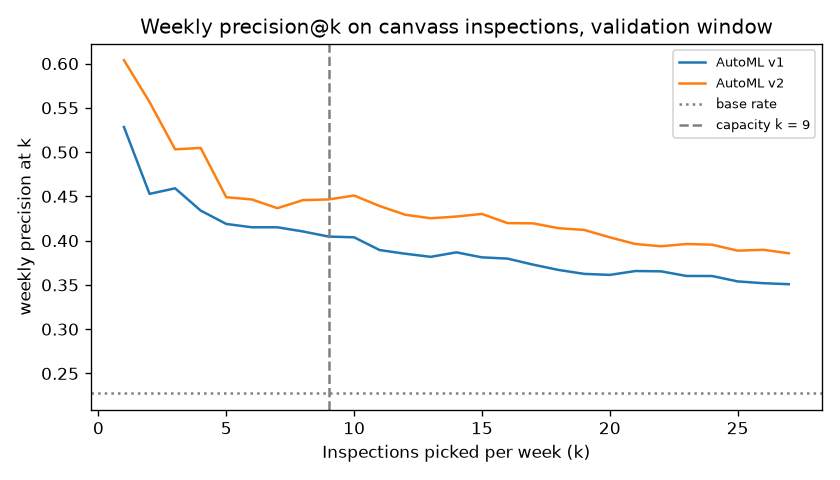

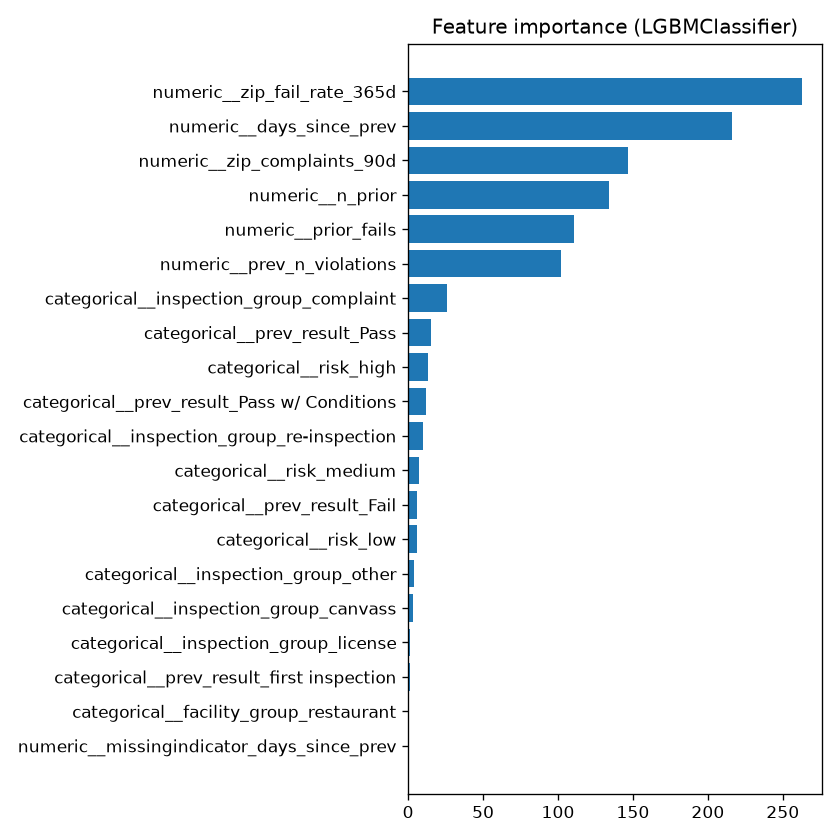

In [37]:
# This cell shows two figures the training run saved: weekly precision for each feature version's best
# model across different numbers of weekly visits (k), and the feature importances of the v2 AutoML
# winner (LightGBM), which show the features the search relied on most.
from IPython.display import Image

display(Image(filename=str(config.TRAINING_RESULTS_DIR / "precision_by_k.png")))
display(Image(filename=str(config.TRAINING_RESULTS_DIR / "feature_importance_v2.png")))

In [38]:
# This cell runs the team's registry tests from tests/test_registry.py: the gate, the promotion
# decision, the semantic version rules and reloading a saved model.
!cd .. && {sys.executable} -m pytest tests/test_registry.py -v --no-header --disable-warnings

============================= test session starts =============================
collecting ... collected 9 items

tests/test_registry.py::test_first_version_is_1_0_0 PASSED               [ 11%]
tests/test_registry.py::test_signature_change_bumps_major PASSED         [ 22%]
tests/test_registry.py::test_new_data_or_algorithm_bumps_minor PASSED    [ 33%]
tests/test_registry.py::test_same_inputs_bump_patch PASSED               [ 44%]
tests/test_registry.py::test_signature_hash_differs_between_feature_versions PASSED [ 55%]
tests/test_registry.py::test_gate_requires_beating_every_bar_by_one_se PASSED [ 66%]
tests/test_registry.py::test_trusted_types_lets_skops_reload_the_model PASSED [ 77%]
tests/test_registry.py::test_promotion_action PASSED                     [ 88%]
tests/test_registry.py::test_gate_uses_the_highest_bar PASSED            [100%]

======================== 9 passed, 1 warning in 25.56s ========================


#### The registered model

| Registry entry | Value |
|---|---|
| Model name | `inspection-ranker` |
| Registry version | 1 |
| Semantic version tag | `1.0.0` |
| Alias | `production` (the API loads `models:/inspection-ranker@production`) |
| Model | logistic regression on the v2 features, refit on the training and validation rows |
| Promotion tag | `bootstrap_baseline` (no AutoML challenger cleared the gate) |
| Validation weekly precision@k | 0.449 (standard error 0.023), against 0.197 for random ranking |

For the city, this means the model finds about 22 more failures per 100 routine visits than random selection would, and a broad AutoML search found nothing measurably better on this data. A later challenger has to beat 0.449 by one standard error (0.471) to replace it.

#### Session 4 tools considered and not used

| Course tool | What the project does instead | Reason |
|---|---|---|
| Airflow (Astro CLI) | Prefect | Airflow needs a scheduler, a webserver and a metadata database for a single local flow; Prefect runs the flow locally with no extra setup (from the team's design notes) |
| H2O AutoML | FLAML | H2O runs a Java server and selects by its own leaderboard metrics; FLAML optimizes the project's weekly precision@k directly |
| A `champion` / `challenger` alias pair | one `production` alias plus the gate | the deployment stage reads a single alias; MLflow's older stage labels (Staging, Production) are deprecated in favor of aliases |
| CodeCarbon emissions tracking | not tracked | the fixed 300-second search budget per feature version bounds the compute each run uses |

# C. Containerization & Deployment

### Session 5: Deployment engineering

Session 5 covered how a trained model becomes a running service: packaging the model together with its preprocessing and metadata (the "Transform Bus" idea, which keeps training and serving transformations identical), serving it behind an API such as FastAPI, choosing between batch and online prediction, and packaging the service in a Docker image whose layers are ordered so that code changes rebuild quickly. Kubernetes, Ray and Spark were covered for scaling out.

The project's deployment is three steps, with the files copied below into `Session 5 - Deployment engineering/`:

```
models:/inspection-ranker@production   (MLflow Model Registry, Session 4)
        |
        v
export_model.py  ->  serving/model/: model.skops, MLmodel, requirements.txt, version.json
        |
        v
docker build     ->  image inspection-ranker with serving/app.py and serving/model/
        |
        v
docker run       ->  FastAPI on port 8000: GET /health, POST /predict, GET /docs
```

| File | What it does |
|---|---|
| `export_model.py` | copies the model behind the `production` alias out of the registry into `serving/model/`, with a `version.json` summary |
| `app.py` (from `serving/`) | the FastAPI service: request and response schemas, `/health` and `/predict` |
| `requirements.txt` (from `serving/`) | the service's libraries, pinned to the versions that saved the model |
| `Dockerfile` | the image, built in cache-friendly layers |

#### Model export: `export_model.py`

The registry lives in a local SQLite file, so the container never connects to it. This script downloads the version behind `models:/inspection-ranker@production` into `serving/model/` and writes `version.json` with the registry version, semantic version, feature version, input columns, lineage tags and the object types skops must trust to reload the model. Because the model is the full scikit-learn pipeline, the preprocessing ships inside it.

In [39]:
%%writefile "../Session 5 - Deployment engineering/export_model.py"
"""Copy the production model out of the MLflow registry into serving/model/ for the Docker build.

The serving container does not reach the registry, which lives in a local SQLite file. This
script downloads the version behind `models:/inspection-ranker@production` into
serving/model/ and writes serving/model/version.json with its registry version, semantic
version, feature version, input columns, lineage tags, and the object types skops must trust to
load it. The API reports these at /health and loads the model with the trusted types.

Usage:
    python export_model.py
"""

import json
import shutil

import mlflow
import yaml

from src import config, registry, tracking


def main() -> None:
    version = registry.production_version()
    if version is None:
        raise SystemExit(f"No version of {config.MODEL_NAME} has the alias {config.PRODUCTION_ALIAS!r}. "
                         "Run pipeline.py first.")

    target = config.SERVING_MODEL_DIR
    if target.exists():
        shutil.rmtree(target)
    target.parent.mkdir(parents=True, exist_ok=True)

    tracking.client()  # sets the tracking URI
    mlflow.artifacts.download_artifacts(
        artifact_uri=f"models:/{config.MODEL_NAME}@{config.PRODUCTION_ALIAS}", dst_path=str(target))

    # The MLmodel file lists the object types that skops must trust to load this model, which the
    # registry computed when it logged the model. The serving app reads them from version.json.
    mlmodel = yaml.safe_load((target / "MLmodel").read_text())
    trusted = mlmodel["flavors"]["sklearn"].get("skops_trusted_types") or []

    tags = dict(version.tags)
    info = {
        "model_name": config.MODEL_NAME,
        "registry_version": version.version,
        "semver": tags.get("semver"),
        "feature_version": tags.get("feature_version"),
        "features": config.FEATURE_COLUMNS.get(tags.get("feature_version"), []),
        "estimator": tags.get("estimator"),
        "data_tag": tags.get("data_tag"),
        "git_commit": tags.get("git_commit"),
        "valid_headline": tags.get("valid_headline"),
        "k_week": tags.get("k_week"),
        "skops_trusted_types": trusted,
    }
    (target / "version.json").write_text(json.dumps(info, indent=2) + "\n")
    print(f"Exported {config.MODEL_NAME} version {version.version} ({info['semver']}) to serving/model/")


if __name__ == "__main__":
    main()

Overwriting ../Session 5 - Deployment engineering/export_model.py


#### Prediction service: `app.py`

The service loads the model once at startup and exposes:

| Endpoint | Returns |
|---|---|
| `GET /health` | `status` and the contents of `version.json` (registry version, semantic version, features, data tag, git commit, validation score, k) |
| `POST /predict` | a fail probability and a rank for every facility in the request, highest risk first, with the model's semantic version |
| `GET /docs` | FastAPI's interactive Swagger page |

Requests are checked against a pydantic schema: the ten v2 feature columns plus a client `facility_id`, and any extra field is rejected with a 422 error.

In [40]:
%%writefile "../Session 5 - Deployment engineering/app.py"
import json                                   # read version.json
from pathlib import Path                      # build paths relative to this file
from contextlib import asynccontextmanager    # only if you use FastAPI's lifespan hook

import pandas as pd                           # request -> DataFrame for the model
import skops.io as sio                        # load model.skops

from fastapi import FastAPI, HTTPException    # app + clean error responses
from pydantic import BaseModel, ConfigDict, Field
      


MODEL_DIR = Path(__file__).parent / "model"

state = {}   # holds loaded objects for the endpoints

@asynccontextmanager
async def lifespan(app: FastAPI):
    # --- runs once at startup ---
    state["version"] = json.loads((MODEL_DIR / "version.json").read_text())
    state["features"] = state["version"]["features"]
    # skops loads only the object types it is told to trust. The registry records the types each
    # model needs when it is logged, and export_model.py copies that list into version.json, so
    # a new production model (for example LightGBM) loads without editing this file.
    if "skops_trusted_types" not in state["version"]:
        raise RuntimeError("version.json has no skops_trusted_types. Rerun export_model.py and rebuild the image.")
    state["model"] = sio.load(MODEL_DIR / "model.skops", trusted=state["version"]["skops_trusted_types"])
    yield
    # --- runs once at shutdown (nothing to clean up here) ---
    state.clear()

app = FastAPI(lifespan=lifespan)

# ---------- Request ----------

class Facility(BaseModel):
    model_config = ConfigDict(extra="forbid")

    facility_id: str                          # client's ID, not a model feature

    # categorical
    inspection_group: str                     # e.g. "canvass"
    facility_group: str                       # e.g. "restaurant"
    risk: str                                 # e.g. "high"
    # Training encodes an establishment with no earlier inspection as "first inspection"
    # (src/features.py), so an omitted value gets the same category.
    prev_result: str = "first inspection"     # "Pass", "Pass w/ Conditions", "Fail", or "first inspection"

    # numeric
    prior_fails: float
    n_prior: float
    days_since_prev: float | None = None
    prev_n_violations: float | None = None
    zip_fail_rate_365d: float
    zip_complaints_90d: float


class RankRequest(BaseModel):
    facilities: list[Facility] = Field(min_length=1)   # batch: at least one facility


# ---------- Response ----------

class ScoredFacility(BaseModel):
    facility_id: str
    score: float      # predicted probability of failing the inspection
    rank: int         # 1 = highest risk


class RankResponse(BaseModel):
    model_version: str          # from version.json (e.g. semver), so every response is traceable
    results: list[ScoredFacility]

@app.get("/health")
def health():
    return {"status": "ok", **state["version"]}

NUMERIC = ["prior_fails", "n_prior", "days_since_prev", "prev_n_violations",
           "zip_fail_rate_365d", "zip_complaints_90d"]
           
@app.post("/predict", response_model=RankResponse)
def predict(req: RankRequest):
    try:
        # request -> DataFrame, columns in training order, facility_id dropped
        df = pd.DataFrame([f.model_dump() for f in req.facilities])[state["features"]]
        # force numeric dtype so an all-None column becomes NaN floats, not object
        df[NUMERIC] = df[NUMERIC].astype(float)

        scores = state["model"].predict_proba(df)[:, 1]   # P(fail) for each facility
    except Exception as e:
        raise HTTPException(status_code=400, detail=f"Model could not score input: {e}")

    # pair each score with its facility_id, sort highest risk first
    ranked = sorted(
        zip([f.facility_id for f in req.facilities], scores),
        key=lambda pair: pair[1],
        reverse=True,
    )

    return RankResponse(
        model_version=state["version"]["semver"],
        results=[
            ScoredFacility(facility_id=fid, score=float(s), rank=i + 1)
            for i, (fid, s) in enumerate(ranked)
        ],
    )

Overwriting ../Session 5 - Deployment engineering/app.py


In [41]:
%%writefile "../Session 5 - Deployment engineering/requirements.txt"
fastapi
uvicorn[standard]
pandas==3.1.1
numpy==2.5.5
scikit-learn==1.9.1
scipy==1.18.1
skops==0.16.0

Overwriting ../Session 5 - Deployment engineering/requirements.txt


#### Container image: `Dockerfile`

The layers follow the Session 5 anatomy: a pinned slim base image, environment settings, system packages, the Python dependencies (copied and installed before the code, so a code change reuses the cached dependency layer), the application code and model, a non-root user, the exposed port with a health check that calls `/health` every 30 seconds, and the start command.

In [42]:
%%writefile "../Session 5 - Deployment engineering/Dockerfile"
# ---- 1. Base image -------------------------------------------------------
# Pin a specific version, not "latest". "slim" drops compilers/docs (~5x smaller).
FROM python:3.13-slim

# ---- 2. Environment settings ---------------------------------------------
# Don't write .pyc files; send print/log output straight to `docker logs`.
ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1

# All following paths are relative to this directory inside the image.
WORKDIR /serving

# ---- 3. System packages (only if needed) ---------------------------------
# Example: curl for the HEALTHCHECK below. Clean the apt cache in the same
# RUN so it doesn't bloat the layer.
RUN apt-get update \
    && apt-get install -y --no-install-recommends curl \
    && rm -rf /var/lib/apt/lists/*

# ---- 4. Python dependencies (before code, for caching) --------------------
# Docker caches each step. Copying ONLY requirements.txt first means editing
# your code later won't re-run the slow pip install.
COPY serving/requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# ---- 5. Application code -------------------------------------------------
# Option A: copy the whole serving folder (app.py + model/ + requirements.txt)
COPY serving/ .

# ---- 6. Run as a non-root user -------------------------------------------
RUN useradd --create-home appuser
USER appuser

# ---- 7. Document the port and add a health check -------------------------
# EXPOSE is documentation; you still publish the port with `docker run -p`.
EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=3s --start-period=10s \
  CMD curl -f http://localhost:8000/health || exit 1

# ---- 8. Start command ----------------------------------------------------
# Exec form (JSON array) so the server receives stop signals properly.
# Bind 0.0.0.0, or nothing outside the container can reach it.
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

Overwriting ../Session 5 - Deployment engineering/Dockerfile


In [43]:
# This cell loads the FastAPI app from serving/app.py (without starting it) and lists its endpoints
# and the fields a request must carry. FastAPI builds this description, the OpenAPI schema, from the
# code itself; the same schema drives the interactive /docs page.
import importlib.util

spec = importlib.util.spec_from_file_location("serving_app", "../serving/app.py")
serving_app = importlib.util.module_from_spec(spec)
spec.loader.exec_module(serving_app)

openapi = serving_app.app.openapi()
routes = [(method.upper(), path, info.get("summary", "")) for path, methods in openapi["paths"].items()
          for method, info in methods.items()]
display(pd.DataFrame(routes, columns=["method", "path", "summary"]))
facility_fields = openapi["components"]["schemas"]["Facility"]
pd.DataFrame([{"field": name, "type": spec_.get("type", " or ".join(t.get("type", "") for t in spec_.get("anyOf", []))),
               "required": name in facility_fields["required"]}
              for name, spec_ in facility_fields["properties"].items()])

,method,path,summary
0,GET,/health,Health
1,POST,/predict,Predict


,field,type,required
0,facility_id,string,True
1,inspection_group,string,True
2,facility_group,string,True
3,risk,string,True
4,prev_result,string,False
5,prior_fails,number,True
6,n_prior,number,True
7,days_since_prev,number or null,False
8,prev_n_violations,number or null,False
9,zip_fail_rate_365d,number,True


#### Building and running the container

The team built and ran the image with the commands below, from the repository root after exporting the model (Docker Desktop must be running). The responses shown are the ones the team recorded for model version 1.0.0, shortened and with the scores rounded.

```console
$ python export_model.py
Exported inspection-ranker version 1 (1.0.0) to serving/model/
$ docker build -t inspection-ranker .
$ docker run --rm -p 8000:8000 inspection-ranker
INFO:     Uvicorn running on http://0.0.0.0:8000
```

```console
$ curl http://localhost:8000/health
{"status": "ok", "model_name": "inspection-ranker", "registry_version": "1", "semver": "1.0.0", "feature_version": "v2", ..., "k_week": "9", ...}

$ curl -X POST http://localhost:8000/predict -H "Content-Type: application/json" -d '{"facilities": [
    {"facility_id": "A", "inspection_group": "canvass", "facility_group": "restaurant", "risk": "high", "prev_result": "Fail",
     "prior_fails": 3, "n_prior": 8, "days_since_prev": 120, "prev_n_violations": 6, "zip_fail_rate_365d": 0.28, "zip_complaints_90d": 15},
    {"facility_id": "B", "inspection_group": "canvass", "facility_group": "restaurant", "risk": "low", "prev_result": "first inspection",
     "prior_fails": 0, "n_prior": 0, "days_since_prev": null, "prev_n_violations": null, "zip_fail_rate_365d": 0.18, "zip_complaints_90d": 2}]}'
{"model_version": "1.0.0", "results": [{"facility_id": "A", "score": 0.429, "rank": 1}, {"facility_id": "B", "score": 0.249, "rank": 2}]}
```

#### Batch and online prediction

Session 5 contrasted batch prediction (scoring many rows on a schedule, "compute once, use many") with online prediction (scoring a request as it arrives). `/predict` serves both uses: a batch of one week's canvass inspections returns the order in which the city would visit them, and the top k (9, reported by `/health`) are that week's visits, while a request with a single facility returns its score for an ad hoc check. Since the city plans inspections ahead, the weekly batch is the main use.

#### Session 5 tools considered and not used

| Course tool | What the project does instead | Reason |
|---|---|---|
| A separate `/rank?k=` endpoint | `/predict` ranks the facilities in each request, and `/health` reports k | one endpoint covers both the weekly list and a single check |
| Loading the model from the registry at startup (`models:/...@production`) | `export_model.py` copies the production model into the image | the container needs no access to the registry, which is a local file on the training machine |
| `mlflow models build-docker` | a hand-written Dockerfile and FastAPI app | more control over the API's request validation and logging (from the team's design notes) |
| Kubernetes, Ray, PySpark | one container on one machine | about 190 restaurant inspections a week is a small load for a single container |

#### The production model on this machine

The sections that follow (explainability, fairness, testing and monitoring) need the exported production model in `serving/model/`. That folder is not committed: it is produced from the MLflow registry on the machine that ran the training pipeline. The next cell uses an existing export when there is one; otherwise it re-runs the Session 4 training pipeline into a scratch folder, `rebuild/` (results, reference data and a local MLflow registry, all excluded from git), and exports the registered model from there. The pipeline is deterministic where it matters: the gate registers the logistic regression baseline as version `1.0.0`, the same model the team registered, so the rebuild reproduces it. The AutoML search takes about 10 minutes.

In [44]:
# This cell makes sure the production model is available in serving/model/. If an export from the
# team's registry is already there, it is used as is. If not, the training pipeline (Session 4) is
# re-run with its results and MLflow registry redirected to rebuild/, and export_model.py copies the
# registered model into serving/model/, the folder the API's Docker image is built from.
import shutil
import subprocess

REBUILD_DIR = (Path("..") / "rebuild").resolve()

if (config.SERVING_MODEL_DIR / "version.json").exists():
    print("Using the exported model already in serving/model/")
else:
    print("No exported model found: rebuilding it into rebuild/ (about 10 minutes)")
    REBUILD_DIR.mkdir(exist_ok=True)
    shutil.copy(config.RESULTS_DIR / "baselines.csv", REBUILD_DIR)
    shutil.copy(config.RESULTS_DIR / "capacity.json", REBUILD_DIR)
    rebuild_env = {**os.environ, "INSPECTIONS_RESULTS_DIR": str(REBUILD_DIR),
                   "MLFLOW_TRACKING_URI": f"sqlite:///{(REBUILD_DIR / 'mlflow.db').as_posix()}"}
    with open(REBUILD_DIR / "pipeline_log.txt", "w") as log:
        subprocess.run([sys.executable, "pipeline.py", "--skip-dvc"], cwd="..", env=rebuild_env,
                       stdout=log, stderr=subprocess.STDOUT, check=True)
        subprocess.run([sys.executable, "export_model.py"], cwd="..", env=rebuild_env,
                       stdout=log, stderr=subprocess.STDOUT, check=True)

version_info = json.loads((config.SERVING_MODEL_DIR / "version.json").read_text())
{key: version_info[key] for key in ["model_name", "registry_version", "semver", "feature_version",
                                    "estimator", "data_tag", "valid_headline", "k_week"]}

Using the exported model already in serving/model/


{'model_name': 'inspection-ranker',
 'registry_version': 1,
 'semver': '1.0.0',
 'feature_version': 'v2',
 'estimator': 'logistic_regression',
 'data_tag': 'data-v2',
 'valid_headline': '0.4486',
 'k_week': '9'}

In [45]:
# This cell loads the exported model the same way the API does (skops, with the object types listed
# in version.json) and scores the two example facilities from the team's README. Matching the scores
# the team recorded (0.429 and 0.249) confirms this is the same model.
import skops.io as sio

from src import train as train_module

production_model = sio.load(config.SERVING_MODEL_DIR / "model.skops", trusted=version_info["skops_trusted_types"])
feature_version = version_info["feature_version"]
examples = pd.DataFrame([
    {"inspection_group": "canvass", "facility_group": "restaurant", "risk": "high", "prev_result": "Fail",
     "prior_fails": 3, "n_prior": 8, "days_since_prev": 120, "prev_n_violations": 6,
     "zip_fail_rate_365d": 0.28, "zip_complaints_90d": 15},
    {"inspection_group": "canvass", "facility_group": "restaurant", "risk": "low", "prev_result": "first inspection",
     "prior_fails": 0, "n_prior": 0, "days_since_prev": None, "prev_n_violations": None,
     "zip_fail_rate_365d": 0.18, "zip_complaints_90d": 2},
], index=["A", "B"])
production_model.predict_proba(train_module.feature_frame(examples, feature_version))[:, 1].round(3)

array([0.429, 0.249])

### Session 6: Explainability, fairness, faster inference

Session 6 (the MLO6 lecture and the Fairlearn labs) covered explaining a model's predictions with SHAP, documenting a model with a model card (Mitchell et al.), checking whether a model treats groups differently with Fairlearn, and making inference faster through quantization, distillation or pruning. For a ranking that decides which restaurants an inspector visits, the first three matter most: an inspector should see why a restaurant is on the list, the city should know whether the list favors or burdens some parts of Chicago, and anyone using the model should know what it is for and where it falls short.

The analyses below use the validation canvass inspections (2024-10-30 to 2025-10-29) from `results/reference.parquet`, which the training pipeline saved with the registered model's out-of-sample predictions. The test year stays untouched for Part D. The model card is saved to `Session 6 - Explainability, fairness, faster inference/model_card.md`.

#### Why a restaurant ranks high: SHAP

SHAP splits each prediction into one contribution per feature, measured against a typical routine inspection from the training period: positive values push a restaurant up the list, negative values push it down. For a logistic regression the contributions are exact and add up, on the log-odds scale, to the gap between the restaurant's score and the typical score.

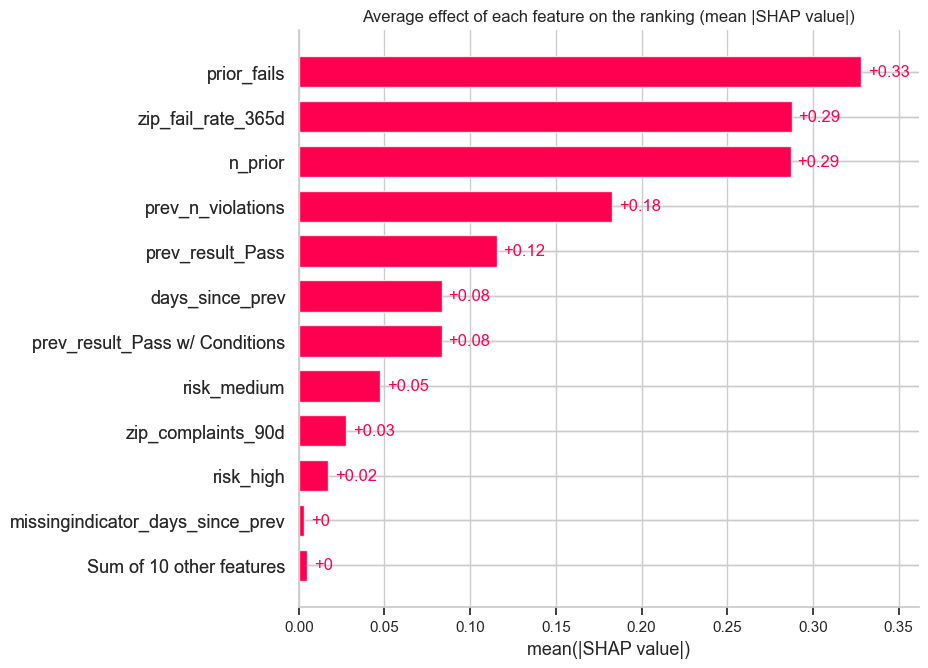

In [46]:
# This cell computes SHAP values for every validation canvass inspection. The model's own
# preprocessing turns each row into the 21 columns the logistic regression sees (one-hot categories,
# scaled numbers, missing-value flags), and SHAP compares each row with 1,000 routine (canvass)
# inspections from the training period. The bar chart ranks the features by their average effect.
import shap

reference = pd.read_parquet(config.REFERENCE_PARQUET)
preprocess = production_model.named_steps["preprocess"]
estimator = production_model.named_steps["model"]
shap_feature_names = [name.split("__", 1)[1] for name in preprocess.get_feature_names_out()]

train_canvass = train_rows[train_rows["is_canvass"]]
background = preprocess.transform(train_module.feature_frame(train_canvass.sample(1000, random_state=config.SEED),
                                                             feature_version))
X_reference = preprocess.transform(train_module.feature_frame(reference, feature_version))
shap_values = shap.Explainer(estimator, background, feature_names=shap_feature_names)(X_reference)

shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("Average effect of each feature on the ranking (mean |SHAP value|)")
plt.show()

In [47]:
# This cell builds the list an inspector would receive for one week: the 9 highest-scoring canvass
# inspections of the last full week in the validation window, with the two features that pushed each
# one up the most. The fail column shows what the inspection actually found.
from src.metrics import weeks

reference["score"] = production_model.predict_proba(train_module.feature_frame(reference, feature_version))[:, 1]
reference["week"] = weeks(reference["inspection_date"])
example_week = sorted(reference["week"].unique())[-2]
week_picks = reference[reference["week"] == example_week].nlargest(int(version_info["k_week"]), "score")


def top_reasons(row_index, n=2):
    """Names of the n features with the largest positive SHAP values for one row."""
    contributions = pd.Series(shap_values.values[row_index], index=shap_feature_names)
    return ", ".join(contributions.sort_values(ascending=False).index[:n])


week_picks = week_picks.assign(top_reasons=[top_reasons(i) for i in week_picks.index])
print("week:", example_week, "| canvass inspections that week:", (reference["week"] == example_week).sum())
print("failures found among the 9 picks:", week_picks["fail"].sum())
week_picks[["inspection_date", "score", "fail", "prev_result", "prior_fails", "days_since_prev",
            "prev_n_violations", "zip_fail_rate_365d", "top_reasons"]].round(3).reset_index(drop=True)

week: 2025-10-20/2025-10-26 | canvass inspections that week: 120
failures found among the 9 picks: 4


,inspection_date,score,fail,prev_result,prior_fails,days_since_prev,prev_n_violations,zip_fail_rate_365d,top_reasons
0,2025-10-23,0.596,1,Pass w/ Conditions,1,527.0,14.0,0.314,"prev_n_violations, zip_fail_rate_365d"
1,2025-10-21,0.467,0,Pass,0,3743.0,0.0,0.140,"days_since_prev, n_prior"
2,2025-10-21,0.464,1,Pass w/ Conditions,3,526.0,9.0,0.319,"prev_n_violations, zip_fail_rate_365d"
3,2025-10-20,0.455,0,Pass,8,466.0,7.0,0.242,"prior_fails, prev_n_violations"
4,2025-10-23,0.433,0,Pass w/ Conditions,2,315.0,7.0,0.313,"zip_fail_rate_365d, prev_n_violations"
5,2025-10-23,0.417,0,Pass w/ Conditions,5,520.0,5.0,0.314,"prior_fails, zip_fail_rate_365d"
6,2025-10-24,0.417,0,Pass w/ Conditions,0,1519.0,4.0,0.281,"days_since_prev, n_prior"
7,2025-10-22,0.404,1,Pass,6,519.0,8.0,0.246,"prior_fails, prev_n_violations"
8,2025-10-20,0.390,1,Pass,10,593.0,2.0,0.273,"prior_fails, zip_fail_rate_365d"


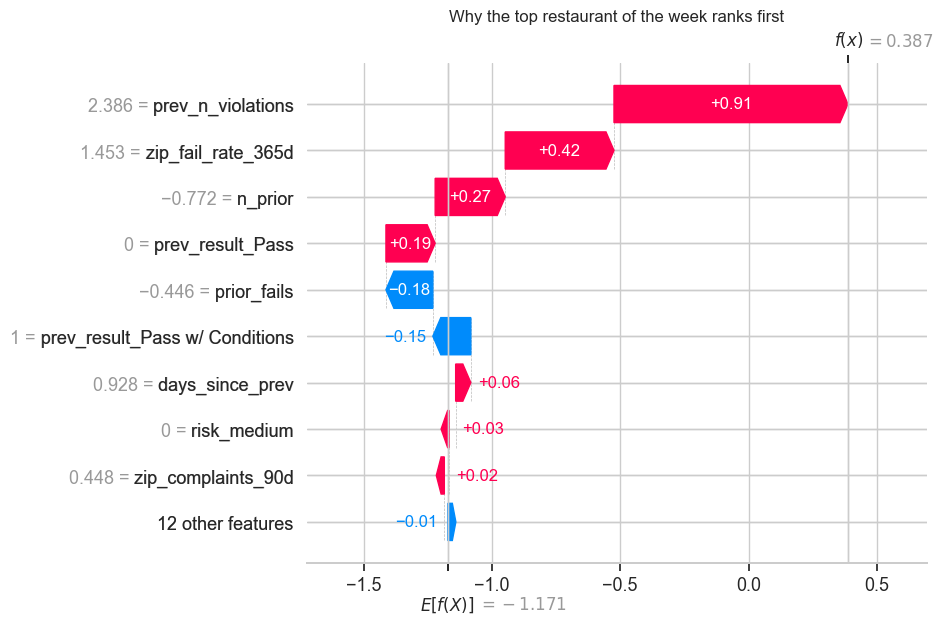

In [48]:
# This cell explains the first restaurant on that week's list in detail. The waterfall starts from
# the typical score (E[f(x)], on the log-odds scale) and adds each feature's contribution in turn,
# ending at this restaurant's score (f(x)). The numbers left of each feature name are the values the
# model sees after its preprocessing: numeric features are scaled (2.4 means about 2.4 standard
# deviations above the training average) and categories are 1 (yes) or 0 (no).
shap.plots.waterfall(shap_values[week_picks.index[0]], max_display=10, show=False)
plt.title("Why the top restaurant of the week ranks first")
plt.show()

#### Fairness across Chicago: Fairlearn

Chicago's North and South Sides, divided at Roosevelt Road, differ in income and racial make-up, so a ranking that sends inspectors to one side more often deserves a close look. The team's evaluation slices already split inspections this way (`slice_region` in `src/metrics.py`). For each side, Fairlearn's `MetricFrame` reports:

- **selection rate:** the share of canvass inspections the model puts in its weekly top 9
- **fail rate:** the share of inspections that actually failed
- **precision of picks:** the share of the model's picks that failed (precision@k within the group)
- **share of failures found:** the share of the group's failures that were among the picks (the true positive rate)

Demographic parity difference is the gap in selection rate between the two sides.

In [49]:
# This cell marks the model's weekly top-9 picks among the validation canvass inspections, then uses
# Fairlearn's MetricFrame to compare the North and South Sides (split at Roosevelt Road, as in the
# team's evaluation slices). Six inspections without coordinates are left out.
from fairlearn.metrics import MetricFrame, count, demographic_parity_difference, selection_rate
from sklearn.metrics import precision_score, recall_score

from src.metrics import add_slice_columns

k_week = int(version_info["k_week"])
fairness = reference.drop(columns="score").merge(load_split("valid")[["inspection_id", "latitude"]],
                                                 on="inspection_id", how="left")
fairness = add_slice_columns(fairness)
fairness = fairness[fairness["slice_region"] != "unknown"]
fairness["picked"] = (fairness.groupby("week")["prediction"].rank(method="first", ascending=False)
                      <= k_week).astype(int)

region_frame = MetricFrame(
    metrics={"inspections": count, "fail rate": lambda y_true, y_pred: y_true.mean(),
             "selection rate": selection_rate, "precision of picks": precision_score,
             "share of failures found": recall_score},
    y_true=fairness["fail"], y_pred=fairness["picked"], sensitive_features=fairness["slice_region"])
parity_gap = demographic_parity_difference(fairness["fail"], fairness["picked"],
                                           sensitive_features=fairness["slice_region"])
print("demographic parity difference (selection rate gap):", round(parity_gap, 3))
region_frame.by_group.round(3)

demographic parity difference (selection rate gap): 0.029


,inspections,fail rate,selection rate,precision of picks,share of failures found
slice_region,,,,,
north,4337.0,0.242,0.070,0.455,0.131
south,1756.0,0.192,0.099,0.437,0.225


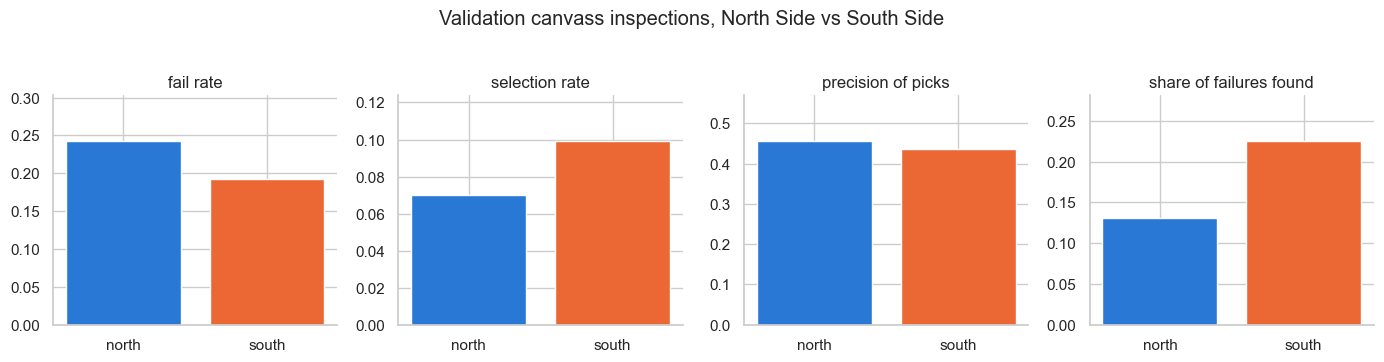

In [50]:
# This cell draws the four rates side by side for the two sides of the city.
rates = region_frame.by_group.drop(columns="inspections")
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=False)
for ax, metric in zip(axes, rates.columns):
    ax.bar(rates.index, rates[metric], color=["#2a78d6", "#eb6834"])
    ax.set_title(metric)
    ax.set_ylim(0, max(rates[metric].max() * 1.25, 0.1))
sns.despine()
plt.suptitle("Validation canvass inspections, North Side vs South Side", y=1.03)
plt.tight_layout()
plt.show()

**Reading the fairness results.** The model's picks seem about equally accurate on both sides of the city: roughly 45% of the North Side picks and 44% of the South Side picks failed their inspection. But South Side restaurants are picked more often (9.9% of their canvass inspections against 7.0% on the North Side), even though they failed less often in this period (19.2% against 24.2%), so the model finds a larger share of the South Side's failures (22.5% against 13.1%). A likely reason is the two ZIP code features, which carry each neighborhood's recent history of fails and complaints into every restaurant's score. Whether a 2.9-point gap in selection rate is acceptable is a policy question for the city rather than a modeling one; the model card below records it, and Part D repeats the check so it can act as a gate on retraining.

#### Model card

In [51]:
%%writefile "../Session 6 - Explainability, fairness, faster inference/model_card.md"
# Model card: inspection-ranker 1.0.0

Following the model card structure of Mitchell et al. (2019), covered in Session 6.

## Model details

- **Name and version:** `inspection-ranker`, MLflow registry version 1, semantic version `1.0.0`, alias `production`
- **Type:** logistic regression (scikit-learn, `max_iter=1000`) inside one scikit-learn pipeline with its preprocessing: one-hot encoding of 4 categorical features, median imputation with missing-value flags and scaling of 6 numeric features (21 model inputs in total)
- **Features (version v2):** inspection group, facility group, risk category, previous result, earlier fails, earlier inspections, days since the previous inspection, violations at the previous inspection, the ZIP code's fail rate over the last 365 days and its complaint inspections over the last 90 days, all computed from earlier days only
- **Data version:** `data-v2` (restaurants only), City of Chicago Food Inspections (dataset `4ijn-s7e5`), snapshot ending 2026-10-29
- **How it was chosen:** a FLAML AutoML search over six algorithms did not beat this baseline by one standard error, so the training pipeline registered the baseline (promotion tag `bootstrap_baseline`)

## Intended use

- **Primary use:** ranking each week's routine (canvass) restaurant inspections in Chicago by their predicted probability of failing, so that inspectors visit the highest-risk restaurants first. It supports the scheduling decision; inspectors still carry out every inspection and decide its result.
- **Out of scope:** complaint, license and re-inspection visits (triggered by events, not scheduled), facility types other than restaurants, and any use that penalizes a restaurant based on its score.

## Factors

The evaluation looks at results by region (North vs South Side, split at Roosevelt Road), by the city's risk category and by inspection history (first inspection vs repeat), the slices in `src/metrics.py`.

## Metrics

- **Headline:** weekly precision@k: each week the model ranks that week's canvass inspections, the top k = 9 (10% of the median 93 canvass inspections per week) count as visits, and the metric is the share of those visits that find a failing restaurant
- **Also reported:** standard error of the headline, lift per 100 visits over random selection, precision at 5%, 10% and 20% of the window, ROC-AUC, PR-AUC

## Training and evaluation data

- **Training:** 62,070 restaurant inspections from 2018-07-01 to 2024-10-29; the registered model was refit on the training and validation rows
- **Validation:** 6,099 canvass inspections from 2024-10-30 to 2025-10-29 (base fail rate 0.228)
- **Test:** inspections from 2025-10-30 to 2026-10-29, held out for production validation through the API (Part D)

## Quantitative analysis (validation window)

| | Weekly precision@k | Notes |
|---|---|---|
| This model | 0.449 (standard error 0.023) | about 22 more failures per 100 routine visits than random selection |
| Random ranking | 0.197 | |
| City risk category alone | 0.237 | |

| Region | Canvass inspections | Fail rate | Selection rate | Precision of picks | Share of failures found |
|---|---|---|---|---|---|
| North Side | 4,337 | 0.242 | 0.070 | 0.455 | 0.131 |
| South Side | 1,756 | 0.192 | 0.099 | 0.437 | 0.225 |

Demographic parity difference (selection rate gap): 0.029.

## Ethical considerations

- **Uneven attention across the city:** South Side restaurants are selected more often than North Side restaurants while failing less often in the validation period, likely through the ZIP code features. The city should decide whether this gap is acceptable; the monitoring stage re-checks it.
- **Feedback loop:** if the city follows the ranking, the restaurants it rates as risky are inspected more often, so future training data over-represents them. Retraining should keep a share of randomly chosen inspections to counter this.
- **Privacy:** business names and addresses are not model inputs, and the API's requests carry only a client ID and the ten features.

## Caveats and recommendations

- The July 2018 food code change renumbered the violation codes; the model trains only on inspections from that date on, and the monitoring stage watches for similar changes in the source data.
- Scores are probabilities from one city and one period; they should be read as a ranking within a week, not as a fixed risk level.
- The model should be re-checked (performance, region gap and drift) whenever new inspection data is added.

Overwriting ../Session 6 - Explainability, fairness, faster inference/model_card.md


In [52]:
# This cell displays the model card saved by the cell above as formatted text.
display(Markdown(Path("../Session 6 - Explainability, fairness, faster inference/model_card.md").read_text(encoding="utf-8")))

# Model card: inspection-ranker 1.0.0

Following the model card structure of Mitchell et al. (2019), covered in Session 6.

## Model details

- **Name and version:** `inspection-ranker`, MLflow registry version 1, semantic version `1.0.0`, alias `production`
- **Type:** logistic regression (scikit-learn, `max_iter=1000`) inside one scikit-learn pipeline with its preprocessing: one-hot encoding of 4 categorical features, median imputation with missing-value flags and scaling of 6 numeric features (21 model inputs in total)
- **Features (version v2):** inspection group, facility group, risk category, previous result, earlier fails, earlier inspections, days since the previous inspection, violations at the previous inspection, the ZIP code's fail rate over the last 365 days and its complaint inspections over the last 90 days, all computed from earlier days only
- **Data version:** `data-v2` (restaurants only), City of Chicago Food Inspections (dataset `4ijn-s7e5`), snapshot ending 2026-10-29
- **How it was chosen:** a FLAML AutoML search over six algorithms did not beat this baseline by one standard error, so the training pipeline registered the baseline (promotion tag `bootstrap_baseline`)

## Intended use

- **Primary use:** ranking each week's routine (canvass) restaurant inspections in Chicago by their predicted probability of failing, so that inspectors visit the highest-risk restaurants first. It supports the scheduling decision; inspectors still carry out every inspection and decide its result.
- **Out of scope:** complaint, license and re-inspection visits (triggered by events, not scheduled), facility types other than restaurants, and any use that penalizes a restaurant based on its score.

## Factors

The evaluation looks at results by region (North vs South Side, split at Roosevelt Road), by the city's risk category and by inspection history (first inspection vs repeat), the slices in `src/metrics.py`.

## Metrics

- **Headline:** weekly precision@k: each week the model ranks that week's canvass inspections, the top k = 9 (10% of the median 93 canvass inspections per week) count as visits, and the metric is the share of those visits that find a failing restaurant
- **Also reported:** standard error of the headline, lift per 100 visits over random selection, precision at 5%, 10% and 20% of the window, ROC-AUC, PR-AUC

## Training and evaluation data

- **Training:** 62,070 restaurant inspections from 2018-07-01 to 2024-10-29; the registered model was refit on the training and validation rows
- **Validation:** 6,099 canvass inspections from 2024-10-30 to 2025-10-29 (base fail rate 0.228)
- **Test:** inspections from 2025-10-30 to 2026-10-29, held out for production validation through the API (Part D)

## Quantitative analysis (validation window)

| | Weekly precision@k | Notes |
|---|---|---|
| This model | 0.449 (standard error 0.023) | about 22 more failures per 100 routine visits than random selection |
| Random ranking | 0.197 | |
| City risk category alone | 0.237 | |

| Region | Canvass inspections | Fail rate | Selection rate | Precision of picks | Share of failures found |
|---|---|---|---|---|---|
| North Side | 4,337 | 0.242 | 0.070 | 0.455 | 0.131 |
| South Side | 1,756 | 0.192 | 0.099 | 0.437 | 0.225 |

Demographic parity difference (selection rate gap): 0.029.

## Ethical considerations

- **Uneven attention across the city:** South Side restaurants are selected more often than North Side restaurants while failing less often in the validation period, likely through the ZIP code features. The city should decide whether this gap is acceptable; the monitoring stage re-checks it.
- **Feedback loop:** if the city follows the ranking, the restaurants it rates as risky are inspected more often, so future training data over-represents them. Retraining should keep a share of randomly chosen inspections to counter this.
- **Privacy:** business names and addresses are not model inputs, and the API's requests carry only a client ID and the ten features.

## Caveats and recommendations

- The July 2018 food code change renumbered the violation codes; the model trains only on inspections from that date on, and the monitoring stage watches for similar changes in the source data.
- Scores are probabilities from one city and one period; they should be read as a ranking within a week, not as a fixed risk level.
- The model should be re-checked (performance, region gap and drift) whenever new inspection data is added.


#### Session 6 tools considered and not used

| Course topic | What the project does | Reason |
|---|---|---|
| Quantization, distillation, pruning, ONNX | the model is served as is | the model is a logistic regression with 21 inputs, so scoring a week's inspections is already fast; compression helps large models such as neural networks |
| Fairlearn mitigation (`ThresholdOptimizer`, `ExponentiatedGradient`) | the gap is measured and documented, not corrected | choosing a correction (for example equal selection rates across regions) is a policy decision for the city; the measurement comes first |
| Causal analysis (DoWhy, EconML) | not used | the model ranks inspections by risk; it does not estimate the effect of an intervention |

### Session 7a: Testing and deployment testing

Lecture 7 separated ML **evaluation** (how good is the model?) from ML **testing** (does the system behave as it should?). It covered unit, integration and end-to-end tests; pre-training tests (data checks, label leakage) and post-training tests such as **invariance** tests (inputs that should not matter do not change the prediction), **directional expectation** tests (a change that should raise the risk does raise it) and **regression tests against a golden dataset**; and deployment tests such as shadow mode, canary releases and A/B tests.

The team's unit tests in `tests/` already cover the pre-training side: feature leakage (run in Session 3), splits and the test-set guard, validation rules, metrics, the AutoML metric and the registry gate (run in Session 4). This section adds tests of the deployed API and the model's behaviour, a golden dataset, and continuous integration that runs the tests on every push. New files are written to their place in the repository (`tests/`, `.github/workflows/`) and copied into `Session 7a - Testing and deployment testing/`.

#### Golden dataset

A golden dataset is a fixed set of inputs with the outputs a trusted model gave them. It is created once from the production model; afterwards a test checks that the same inputs still receive the same scores, so an unintended change in the model, its preprocessing or a library version is caught. The rows are 25 validation canvass inspections (no test-year rows).

In [53]:
# This cell creates the golden dataset: 25 validation canvass inspections, in the API's request format,
# with the scores the production model gives them. It is saved to tests/data/golden_predictions.json
# together with the model's semantic version. It is created once; after a deliberate model change it
# would be re-created and the new file reviewed.
golden_rows = reference.sample(25, random_state=config.SEED)
golden_records = json.loads(golden_rows[version_info["features"]].to_json(orient="records"))
golden_facilities = [{"facility_id": str(inspection_id), **record}
                     for inspection_id, record in zip(golden_rows["inspection_id"], golden_records)]
golden_scores = production_model.predict_proba(train_module.feature_frame(golden_rows, feature_version))[:, 1]
golden = {"semver": version_info["semver"], "facilities": golden_facilities,
          "expected_scores": dict(zip(golden_rows["inspection_id"].astype(str), golden_scores.round(8).tolist()))}

golden_path = Path("../tests/data/golden_predictions.json")
golden_path.parent.mkdir(exist_ok=True)
golden_path.write_text(json.dumps(golden, indent=1))
print("saved", len(golden_facilities), "golden rows for model", golden["semver"])

saved 25 golden rows for model 1.0.0


#### API, behavioural and golden-dataset tests: `tests/test_api.py`

The tests run the API in-process with FastAPI's `TestClient`, so they test the same `serving/app.py` and exported model the Docker image packages, without starting a container. They are skipped where no exported model is present (for example in continuous integration).

In [54]:
%%writefile ../tests/test_api.py
"""Tests for the prediction API in serving/app.py: request schema, behaviour, and a golden dataset.

The API runs in-process through FastAPI's TestClient, which starts the app (and loads the model)
without a server. The tests need the exported model in serving/model/ (see export_model.py), so
they are skipped where it is missing, for example in continuous integration.

- Schema tests: valid requests score, malformed requests are rejected with HTTP 422.
- Behavioural tests (Lecture 7): invariance (inputs the model should ignore do not change a score)
  and directional expectations (more risk signals raise a score).
- Golden dataset: fixed validation rows whose scores were recorded from the production model;
  any change in those scores means the model or its preprocessing changed.
"""

import importlib.util
import json

import pytest

from src import config

pytest.importorskip("fastapi.testclient")
from fastapi.testclient import TestClient  # noqa: E402

GOLDEN = config.PROJECT_ROOT / "tests" / "data" / "golden_predictions.json"

pytestmark = pytest.mark.skipif(not (config.SERVING_MODEL_DIR / "version.json").exists(),
                                reason="no exported model in serving/model/")

FACILITY = {
    "facility_id": "A", "inspection_group": "canvass", "facility_group": "restaurant", "risk": "high",
    "prev_result": "Pass", "prior_fails": 2, "n_prior": 6, "days_since_prev": 365, "prev_n_violations": 4,
    "zip_fail_rate_365d": 0.22, "zip_complaints_90d": 10,
}


@pytest.fixture(scope="module")
def client():
    """A test client for serving/app.py; the with-block runs the app's startup, which loads the model."""
    spec = importlib.util.spec_from_file_location("serving_app", config.PROJECT_ROOT / "serving" / "app.py")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    with TestClient(module.app) as test_client:
        yield test_client


def predict(client, *facilities):
    """POST the facilities to /predict and return the response."""
    return client.post("/predict", json={"facilities": list(facilities)})


def score(client, **changes) -> float:
    """Score of the base facility with `changes` applied."""
    return predict(client, {**FACILITY, **changes}).json()["results"][0]["score"]


# ---- schema ------------------------------------------------------------------------------------

def test_health_reports_the_model_version(client):
    body = client.get("/health").json()
    assert body["status"] == "ok"
    assert body["semver"] and body["features"]


def test_predict_ranks_every_facility_highest_risk_first(client):
    low = {**FACILITY, "facility_id": "B", "prior_fails": 0, "prev_n_violations": 0, "zip_fail_rate_365d": 0.10}
    body = predict(client, low, FACILITY).json()
    assert [r["facility_id"] for r in body["results"]] == ["A", "B"]
    assert [r["rank"] for r in body["results"]] == [1, 2]
    assert all(0 < r["score"] < 1 for r in body["results"])
    assert body["model_version"] == client.get("/health").json()["semver"]


def test_first_inspection_without_history_is_scored(client):
    first = {**FACILITY, "prev_result": "first inspection", "prior_fails": 0, "n_prior": 0,
             "days_since_prev": None, "prev_n_violations": None}
    assert predict(client, first).status_code == 200


@pytest.mark.parametrize("bad_facility", [
    {**FACILITY, "dba_name": "TEST KITCHEN"},                              # field the model does not use
    {k: v for k, v in FACILITY.items() if k != "prior_fails"},             # required field missing
    {**FACILITY, "prior_fails": "three"},                                  # wrong type
])
def test_malformed_facilities_are_rejected(client, bad_facility):
    assert predict(client, bad_facility).status_code == 422


def test_empty_batch_is_rejected(client):
    assert client.post("/predict", json={"facilities": []}).status_code == 422


# ---- behaviour ---------------------------------------------------------------------------------

def test_score_ignores_the_client_id(client):
    """Invariance: the facility ID is a label for the client, not a model input."""
    assert score(client, facility_id="A") == score(client, facility_id="SOME-OTHER-ID")


def test_score_does_not_depend_on_the_rest_of_the_batch(client):
    """Invariance: a facility's score is the same alone and in a batch; only its rank is relative."""
    others = [{**FACILITY, "facility_id": f"X{i}", "prior_fails": i} for i in range(5)]
    alone = predict(client, FACILITY).json()["results"][0]["score"]
    batch = {r["facility_id"]: r["score"] for r in predict(client, FACILITY, *others).json()["results"]}
    assert batch["A"] == pytest.approx(alone)


@pytest.mark.parametrize("feature, low, high", [
    ("prior_fails", 0, 6),
    ("prev_n_violations", 0, 12),
    ("zip_fail_rate_365d", 0.10, 0.35),
])
def test_more_risk_signals_raise_the_score(client, feature, low, high):
    """Directional expectation: more earlier fails, violations, or ZIP code fails mean a higher score."""
    assert score(client, **{feature: high}) > score(client, **{feature: low})


# ---- golden dataset ----------------------------------------------------------------------------

def test_golden_dataset_scores_are_unchanged(client):
    """Regression test: the recorded validation rows still receive the recorded scores."""
    golden = json.loads(GOLDEN.read_text())
    assert golden["semver"] == client.get("/health").json()["semver"]
    results = {r["facility_id"]: r["score"] for r in predict(client, *golden["facilities"]).json()["results"]}
    for facility_id, expected in golden["expected_scores"].items():
        assert results[facility_id] == pytest.approx(expected, abs=1e-6)

Overwriting ../tests/test_api.py


In [55]:
# This cell runs the new API tests: schema checks, the invariance and directional tests, and the
# golden-dataset regression test.
!cd .. && {sys.executable} -m pytest tests/test_api.py -v --no-header --disable-warnings

============================= test session starts =============================
collecting ... collected 13 items

tests/test_api.py::test_health_reports_the_model_version PASSED          [  7%]
tests/test_api.py::test_predict_ranks_every_facility_highest_risk_first PASSED [ 15%]
tests/test_api.py::test_first_inspection_without_history_is_scored PASSED [ 23%]
tests/test_api.py::test_malformed_facilities_are_rejected[bad_facility0] PASSED [ 30%]
tests/test_api.py::test_malformed_facilities_are_rejected[bad_facility1] PASSED [ 38%]
tests/test_api.py::test_malformed_facilities_are_rejected[bad_facility2] PASSED [ 46%]
tests/test_api.py::test_empty_batch_is_rejected PASSED                   [ 53%]
tests/test_api.py::test_score_ignores_the_client_id PASSED               [ 61%]
tests/test_api.py::test_score_does_not_depend_on_the_rest_of_the_batch PASSED [ 69%]
tests/test_api.py::test_more_risk_signals_raise_the_score[prior_fails-0-6] PASSED [ 76%]
tests/test_api.py::test_more_risk_signals_r

In [56]:
# This cell runs the team's whole test suite together with the new tests, as continuous integration
# does on every push (where the API tests are skipped because no model is exported there).
!cd .. && {sys.executable} -m pytest -q --no-header --disable-warnings

....................................................................     [100%]
68 passed, 11 warnings in 34.42s


#### Continuous integration: `.github/workflows/tests.yml`

Lecture 1 described continuous integration as building and testing every change automatically, shown there as a Jenkins pipeline (checkout, build, test). GitHub Actions does the same here: on every push and pull request it installs `requirements.txt` on a fresh Linux machine and runs `pytest`. A change that breaks a test is then visible on GitHub before it is merged.

In [57]:
%%writefile ../.github/workflows/tests.yml
# Continuous integration: run the unit tests on every push and pull request.
#
# The tests build small example tables themselves, so they need no data. The API tests in
# tests/test_api.py need an exported model, which is not in the repository, so they are skipped here
# and run on a machine where serving/model/ exists.
name: tests

on:
  push:
  pull_request:

jobs:
  pytest:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.12"
          cache: pip
      - name: Install dependencies
        run: pip install -r requirements.txt
      - name: Run the tests
        run: python -m pytest -v

Overwriting ../.github/workflows/tests.yml


In [58]:
# This cell copies the new test file, the golden dataset and the workflow into the Session 7a folder,
# next to the other session folders, so the session's files can be read in one place.
for new_file in ["tests/test_api.py", "tests/data/golden_predictions.json", ".github/workflows/tests.yml"]:
    shutil.copy(Path("..") / new_file, Path("../Session 7a - Testing and deployment testing") / Path(new_file).name)
sorted(path.name for path in Path("../Session 7a - Testing and deployment testing").iterdir())

['golden_predictions.json', 'test_api.py', 'tests.yml']

#### Deployment testing: shadow mode, canary and A/B tests

Lecture 7 described three ways to test a new model with real traffic before it replaces the current one:

| Strategy | How it works | In this project |
|---|---|---|
| Shadow mode | the challenger scores the same requests as the production model, but only the production model's answer is returned; the two are compared offline | the API logs every request (Part D), so the AutoML challenger can score the logged requests afterwards and its picks can be compared with the production model's, with no risk to the city's schedule |
| Canary release | a small share of traffic (for example 1%, then 10%, then 50%) goes to the new model while its errors are watched | not used: the city sends one weekly batch, so there is no stream of traffic to split |
| A/B test | traffic is split between two models and their outcomes are compared statistically | not used: comparing two rankings fairly would need the city to inspect both lists' picks, which changes real inspections |

The promotion gate in Session 4 plays the role of the offline comparison: a challenger replaces the production model only if it beats it by one standard error on the validation window.

# D. Production Monitoring & Drift Simulation

### Session 7b: Monitoring and drift simulation

Lecture 7 described what can go wrong after deployment: **data drift** (the inputs change, for example a new data format or a different population), **concept drift** (the link between the inputs and the outcome changes) and **prediction drift** (the model's outputs move). True outcomes often arrive late (label lag), so a monitor watches the inputs and outputs it sees immediately, and checks performance once the outcomes are in. The Session 7 lab used **Evidently** for this: a reference dataset, a current dataset, a drift report per column, and a self-hosted workspace and UI where every report is logged.

This section builds that monitor around the deployed API from Session 5. The steps follow the brief:

| Brief step | Where it is done below |
|---|---|
| Monitoring framework or dashboard | `src/monitoring.py` (request log, checks, alerts) and an Evidently workspace with a dashboard |
| Baseline validation | the clean test year is sent through the API in weekly batches and checked against the monitoring baseline |
| Stress test / drift simulation | one real drift batch (the year before the 2018 food code change) and five artificial ones |
| Anomaly verification | an alert matrix, the alert log and the Evidently dashboard show which checks caught each scenario |

The monitor has three layers, from the fastest signal to the slowest:

| Layer | When it runs | Checks |
|---|---|---|
| Request checks | on every batch | share of requests the API rejects (HTTP 422); `validate.validate_features` rules for values outside plausible ranges and unknown categories |
| Drift checks | on a monitoring window | Evidently drift of each input column and of the returned scores against the reference |
| Performance checks | once inspection results arrive | weekly precision@k of the served scores |

New files are written to their place in the repository (`src/`, `tests/`) and copied into `Session 7b - Monitoring and drift simulation/`. The request log, the alert log, the Evidently workspace and the HTML reports are written to `monitoring/` (not in git); the summary table and figures are saved to `results/monitoring/`.

#### Monitoring module: `src/monitoring.py`

| Part | Functions |
|---|---|
| Request log | `send_weekly` posts each week's rows to the API as one batch and writes the request, the HTTP status and the response to a JSON lines log; `read_log` turns the log back into one row per facility |
| Drift | `drift_report` runs Evidently's `DataDriftPreset` with a pass/fail test per column; `drift_scores` reads the scores; `calibrate` sets each column's threshold from clean data |
| Alerts | `check` runs the three layers on one scenario's logged traffic; `raise_alerts` writes the checks that fire to the alert log and to Python's logging |
| Dashboard | `create_dashboard` creates the Evidently workspace and project with three dashboard panels |
| Scenarios | `out_of_bounds`, `swap_columns`, `rename_field`, `raw_risk_labels`, `shuffle_outcomes` corrupt a clean batch |

In [59]:
%%writefile ../src/monitoring.py
"""Production monitoring for the prediction API: request logging, drift reports, alerts, drift scenarios.

The monitor checks served traffic in three layers, from the fastest signal to the slowest:

1. Request checks, on every batch: the share of requests the API rejected (HTTP 422), and the
   rules in `validate.validate_features` that flag values outside plausible ranges or unknown
   categories in the requests it accepted.
2. Drift checks, on a monitoring window: Evidently compares the served inputs and the returned
   scores with the reference data (the validation canvass inspections), column by column.
3. Performance checks, once inspection results arrive: weekly precision@k of the served scores.
   Results arrive only after the visits, so this layer lags the other two.

Every batch sent to the API is written to a JSON lines log (one line per batch, rejected batches
included), and the checks read the log, which is what the API actually received and returned.

The functions at the end corrupt a clean batch in the ways the drift simulation tests: impossible
values, swapped columns, a renamed field, a changed category format and shuffled outcomes.
"""

import json
import logging
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from evidently import DataDefinition, Dataset, Report
from evidently.presets import DataDriftPreset
from evidently.sdk.models import PanelMetric
from evidently.sdk.panels import bar_plot_panel
from evidently.ui.workspace import Workspace

from src import config, metrics, validate

MONITORING_DIR = config.PROJECT_ROOT / "monitoring"   # request log, alert log, Evidently workspace, reports
DEFAULT_THRESHOLD = 0.1     # Evidently's default for its distance measures (Wasserstein, Jensen-Shannon)
THRESHOLD_MARGIN = 1.5      # a column alerts when its drift exceeds 1.5 times the drift seen on clean data
DRIFT_SHARE_LIMIT = 0.2     # dataset alert when more than 20% of the monitored columns drift
PRECISION_SE_LIMIT = 2      # performance alert when precision@k falls 2 standard errors below validation

logger = logging.getLogger("inspectrank.monitoring")


def monitored_columns(version: str) -> list[str]:
    """The model's input columns for feature `version`, plus the score the API returned."""
    return list(config.FEATURE_COLUMNS[version]) + ["score"]


def data_definition(version: str) -> DataDefinition:
    """The column types Evidently needs: numeric features and the score, and categorical features."""
    return DataDefinition(numerical_columns=list(config.NUMERIC_FEATURES[version]) + ["score"],
                          categorical_columns=list(config.CATEGORICAL_FEATURES))


# ---- request log -------------------------------------------------------------------------------

def to_requests(rows: pd.DataFrame, columns: list[str]) -> list[dict]:
    """Rows as API facility records, with the inspection ID as facility_id and missing values as null."""
    records = json.loads(rows[columns].to_json(orient="records"))
    return [{"facility_id": str(inspection_id), **record} for inspection_id, record in zip(rows["inspection_id"], records)]


def send_weekly(rows: pd.DataFrame, url: str, scenario: str, log_path: Path, columns: list[str]) -> pd.DataFrame:
    """POST each week's rows to the API as one batch, log every batch, and return the rows with their scores.

    Each log line holds the time, the scenario, the week, the request, the HTTP status and the
    response. A rejected batch is logged with its error, and its rows get no score.
    """
    scored = []
    with open(log_path, "a") as log:
        for week, batch in rows.groupby(metrics.weeks(rows["inspection_date"]), sort=True):
            facilities = to_requests(batch, columns)
            response = requests.post(f"{url}/predict", json={"facilities": facilities}, timeout=60)
            log.write(json.dumps({"time": datetime.now(timezone.utc).isoformat(), "scenario": scenario,
                                  "week": str(week), "status": response.status_code,
                                  "request": facilities, "response": response.json()}) + "\n")
            scores = {r["facility_id"]: r["score"] for r in response.json().get("results", [])}
            scored.append(batch.assign(status=response.status_code,
                                       score=batch["inspection_id"].astype(str).map(scores)))
    return pd.concat(scored)


def read_log(log_path: Path) -> pd.DataFrame:
    """One row per logged facility: scenario, week, HTTP status, the request's fields and the returned score."""
    rows = []
    for line in Path(log_path).read_text().splitlines():
        batch = json.loads(line)
        scores = {r["facility_id"]: r["score"] for r in batch["response"].get("results", [])}
        rows += [{"scenario": batch["scenario"], "week": batch["week"], "status": batch["status"], **facility,
                  "score": scores.get(facility["facility_id"])} for facility in batch["request"]]
    return pd.DataFrame(rows)


# ---- drift -------------------------------------------------------------------------------------

def drift_report(current: pd.DataFrame, reference: pd.DataFrame, version: str, thresholds: dict | None = None,
                 name: str | None = None, timestamp: datetime | None = None):
    """Evidently drift report of the current rows against the reference, with a pass/fail test per column.

    Numeric columns use the normed Wasserstein distance and categorical columns the Jensen-Shannon
    distance (Evidently's defaults for samples over 1,000 rows). `thresholds` sets each column's
    limit; without it every column uses Evidently's default of 0.1.
    """
    columns = monitored_columns(version)
    preset = DataDriftPreset(columns=columns, drift_share=DRIFT_SHARE_LIMIT, per_column_threshold=thresholds)
    definition = data_definition(version)
    return Report([preset], include_tests=True).run(
        Dataset.from_pandas(current[columns], data_definition=definition),
        Dataset.from_pandas(reference[columns], data_definition=definition),
        name=name, timestamp=timestamp)


def drift_scores(snapshot) -> pd.Series:
    """Each monitored column's drift score, and the share of drifted columns, from an Evidently report."""
    values = {}
    for metric in snapshot.dict()["metrics"]:
        value = metric["value"]
        values[metric["config"].get("column", "drifted_share")] = value["share"] if isinstance(value, dict) else value
    return pd.Series(values)


def calibrate(clean_scores: pd.Series) -> dict:
    """Per-column drift thresholds: the drift measured on clean data times the margin, at least the default."""
    return {column: round(max(DEFAULT_THRESHOLD, THRESHOLD_MARGIN * score), 3)
            for column, score in clean_scores.drop("drifted_share").items()}


def create_dashboard(workspace_path: Path, version: str, name: str = "InspectRank monitoring"):
    """A local Evidently workspace with one project, whose dashboard plots the drift checks of every run.

    The panels show, per monitoring run, the share of drifted columns (the dataset alert), the
    drift of the returned scores, and the drift of each numeric feature. `evidently ui` serves it.
    """
    workspace = Workspace.create(str(workspace_path))
    project = workspace.create_project(name)
    project.description = "Served requests and scores of the inspection-ranker API against the validation reference"
    project.save()
    project.dashboard.add_panel(bar_plot_panel(
        "Share of drifted columns", size="half", description=f"dataset alert above {DRIFT_SHARE_LIMIT}",
        values=[PanelMetric(legend="share", metric="DriftedColumnsCount", metric_labels={"value_type": "share"})]))
    project.dashboard.add_panel(bar_plot_panel(
        "Drift of the returned scores", size="half", description="distance from the reference scores",
        values=[PanelMetric(legend="score", metric="ValueDrift", metric_labels={"column": "score"})]))
    project.dashboard.add_panel(bar_plot_panel(
        "Drift of each numeric feature", description="distance from the reference distribution",
        values=[PanelMetric(legend=column, metric="ValueDrift", metric_labels={"column": column})
                for column in config.NUMERIC_FEATURES[version]]))
    return workspace, project


# ---- alerts ------------------------------------------------------------------------------------

def check(scenario_log: pd.DataFrame, reference: pd.DataFrame, version: str, thresholds: dict,
          labels: pd.DataFrame, k: int, valid_precision: float, valid_se: float, name: str,
          timestamp: datetime):
    """Run the three layers of checks on one scenario's logged traffic.

    Returns a table with one row per check (value, limit, whether it alerts, detail) and the
    Evidently report, which is None when the API rejected every request. `labels` holds the
    inspection results (inspection_id, inspection_date, fail) that arrive after the visits.
    """
    accepted = scenario_log[scenario_log["status"] == 200]
    rules = validate.validate_features(accepted.drop(columns=["scenario", "week", "status", "facility_id", "score"]),
                                       version)
    warnings = validate.warnings_of(rules)
    rejected = 1 - len(accepted) / len(scenario_log)
    rows = [
        {"check": "rejected requests (share)", "value": rejected, "limit": 0.0, "alert": rejected > 0,
         "detail": f"{len(scenario_log) - len(accepted)} of {len(scenario_log)} rejected"},
        {"check": "out-of-range or unknown values (rules)", "value": float(len(warnings)), "limit": 0.0,
         "alert": len(warnings) > 0,
         "detail": "; ".join(f"{r.rule}: {r.detail}" for r in warnings.itertuples()) or "none"},
    ]
    snapshot = None
    if len(accepted):
        snapshot = drift_report(accepted, reference, version, thresholds, name=name, timestamp=timestamp)
        scores = drift_scores(snapshot)
        drifted = [column for column in thresholds if scores[column] >= thresholds[column]]
        served = accepted.astype({"facility_id": str}).merge(
            labels.astype({"inspection_id": str}), left_on="facility_id", right_on="inspection_id")
        precision, _ = metrics.weekly_precision_at_k(served["fail"], served["score"], served["inspection_date"], k)
        precision_floor = valid_precision - PRECISION_SE_LIMIT * valid_se
        rows += [
            {"check": "drifted columns (share)", "value": scores["drifted_share"], "limit": DRIFT_SHARE_LIMIT,
             "alert": scores["drifted_share"] > DRIFT_SHARE_LIMIT, "detail": ", ".join(drifted) or "none"},
            {"check": "score drift (distance)", "value": scores["score"], "limit": thresholds["score"],
             "alert": scores["score"] >= thresholds["score"],
             "detail": f"mean score {accepted['score'].mean():.3f} (reference {reference['score'].mean():.3f})"},
            {"check": "weekly precision@k (after results arrive)", "value": precision, "limit": precision_floor,
             "alert": precision < precision_floor,
             "detail": f"validation {valid_precision:.3f}; limit is {PRECISION_SE_LIMIT} standard errors below it"},
        ]
    table = pd.DataFrame(rows)
    return table.assign(scenario=name), snapshot


def raise_alerts(table: pd.DataFrame, alert_log: Path) -> pd.DataFrame:
    """Write every check that alerts to the alert log and to the logging system, and return those rows."""
    alerts = table[table["alert"]]
    with open(alert_log, "a") as log:
        for row in alerts.itertuples():
            message = f"ALERT [{row.scenario}] {row.check}: {row.value:.3f} (limit {row.limit:.3f}); {row.detail}"
            log.write(f"{datetime.now(timezone.utc).isoformat()} {message}\n")
            logger.warning(message)
    return alerts


# ---- drift scenarios ---------------------------------------------------------------------------

def as_float(rows: pd.DataFrame, version: str) -> pd.DataFrame:
    """A copy of the rows with every numeric feature as float, so corrupted values fit in the column."""
    return rows.astype({column: float for column in config.NUMERIC_FEATURES[version]})


def out_of_bounds(rows: pd.DataFrame, version: str, share: float = 0.2, seed: int = config.SEED) -> pd.DataFrame:
    """Impossible random values in a share of rows: 250 to 1,000 earlier fails, ZIP fail rates of 1.5 to 5."""
    rng = np.random.default_rng(seed)
    rows = as_float(rows, version)
    hit = rng.random(len(rows)) < share
    rows.loc[hit, "prior_fails"] = rng.integers(250, 1000, hit.sum()).astype(float)
    rows.loc[hit, "zip_fail_rate_365d"] = rng.uniform(1.5, 5, hit.sum())
    return rows


def swap_columns(rows: pd.DataFrame, version: str, first: str = "prior_fails",
                 second: str = "n_prior") -> pd.DataFrame:
    """Two numeric columns swapped, as a client that maps fields by position would send them."""
    rows = as_float(rows, version)
    rows[[first, second]] = rows[[second, first]].to_numpy()
    return rows


def rename_field(rows: pd.DataFrame, old: str = "prior_fails", new: str = "prior_failures") -> pd.DataFrame:
    """A field renamed by the upstream system, so requests no longer match the API's schema."""
    return rows.rename(columns={old: new})


def raw_risk_labels(rows: pd.DataFrame) -> pd.DataFrame:
    """Risk levels in the city portal's raw format ("Risk 1 (High)") instead of the cleaned values."""
    raw = {"high": "Risk 1 (High)", "medium": "Risk 2 (Medium)", "low": "Risk 3 (Low)", "missing": "All"}
    return rows.assign(risk=rows["risk"].map(raw))


def shuffle_outcomes(rows: pd.DataFrame, seed: int = config.SEED) -> pd.DataFrame:
    """Outcomes shuffled within each week: the inputs are unchanged, but they no longer predict the outcome."""
    rng = np.random.default_rng(seed)
    week = metrics.weeks(rows["inspection_date"])
    return rows.assign(fail=rows.groupby(week)["fail"].transform(lambda fails: rng.permutation(fails.to_numpy())))

Overwriting ../src/monitoring.py


#### Tests: `tests/test_monitoring.py`

The tests check that each scenario corrupts a batch the way its name says and that the team's input rules in `src/validate.py` flag the corruptions they are meant to catch (and miss the swapped columns, which pass every rule). Continuous integration (Session 7a) runs them on every push.

In [60]:
%%writefile ../tests/test_monitoring.py
"""Tests for src/monitoring.py: the request format, the drift scenarios and the alert thresholds.

The scenarios must corrupt a batch in the way their names say, and the input rules in
src/validate.py must flag the corruptions they are meant to catch.
"""

import numpy as np
import pandas as pd
import pytest

from src import metrics, monitoring, validate

VERSION = "v2"


@pytest.fixture
def batch() -> pd.DataFrame:
    """Two weeks of clean canvass inspections in the format of the processed splits."""
    rng = np.random.default_rng(0)
    n = 40
    return pd.DataFrame({
        "inspection_id": [str(1000 + i) for i in range(n)],
        "inspection_date": pd.to_datetime("2026-01-05") + pd.to_timedelta(rng.integers(0, 14, n), unit="D"),
        "fail": rng.integers(0, 2, n).astype("int8"),
        "inspection_group": "canvass", "facility_group": "restaurant",
        "risk": rng.choice(["high", "medium", "low"], n), "prev_result": rng.choice(["Pass", "Fail"], n),
        "prior_fails": rng.integers(0, 5, n).astype("int8"), "n_prior": rng.integers(5, 20, n),
        "days_since_prev": rng.uniform(100, 500, n), "prev_n_violations": rng.integers(0, 8, n).astype(float),
        "zip_fail_rate_365d": rng.uniform(0.1, 0.3, n), "zip_complaints_90d": rng.integers(0, 20, n).astype(float),
    })


def failed_rules(rows: pd.DataFrame) -> set[str]:
    report = validate.validate_features(rows, VERSION)
    return set(report.loc[~report["passed"], "rule"])


def test_clean_batch_passes_the_input_rules(batch):
    assert failed_rules(batch) == set()


def test_requests_carry_the_inspection_id_and_null_for_missing_values(batch):
    batch.loc[0, "days_since_prev"] = np.nan
    first = monitoring.to_requests(batch, ["days_since_prev", "risk"])[0]
    assert first == {"facility_id": "1000", "days_since_prev": None, "risk": batch.loc[0, "risk"]}


def test_out_of_bounds_values_break_the_range_rules(batch):
    corrupted = monitoring.out_of_bounds(batch, VERSION, share=0.5)
    assert failed_rules(corrupted) == {"range_prior_fails", "range_zip_fail_rate_365d"}


def test_swapped_columns_pass_the_input_rules_unnoticed(batch):
    swapped = monitoring.swap_columns(batch, VERSION)
    assert (swapped["prior_fails"] == batch["n_prior"]).all() and (swapped["n_prior"] == batch["prior_fails"]).all()
    assert failed_rules(swapped) == set()


def test_renamed_field_breaks_the_schema(batch):
    assert failed_rules(monitoring.rename_field(batch)) == {"required_feature_columns"}


def test_raw_risk_labels_are_unknown_categories(batch):
    assert failed_rules(monitoring.raw_risk_labels(batch)) == {"allowed_values_risk"}


def test_shuffled_outcomes_keep_each_weeks_fail_count(batch):
    shuffled = monitoring.shuffle_outcomes(batch)
    week = metrics.weeks(batch["inspection_date"])
    pd.testing.assert_series_equal(shuffled.groupby(week)["fail"].sum(), batch.groupby(week)["fail"].sum())
    assert not (shuffled["fail"] == batch["fail"]).all()


def test_thresholds_add_a_margin_to_clean_drift_and_keep_the_default_floor():
    clean = pd.Series({"drifted_share": 0.3, "zip_fail_rate_365d": 0.38, "risk": 0.01})
    assert monitoring.calibrate(clean) == {"zip_fail_rate_365d": 0.57, "risk": monitoring.DEFAULT_THRESHOLD}

Overwriting ../tests/test_monitoring.py


In [61]:
# This cell runs the monitoring tests with pytest.
!cd .. && {sys.executable} -m pytest tests/test_monitoring.py -v --no-header --disable-warnings

============================= test session starts =============================
collecting ... collected 8 items

tests/test_monitoring.py::test_clean_batch_passes_the_input_rules PASSED [ 12%]
tests/test_monitoring.py::test_requests_carry_the_inspection_id_and_null_for_missing_values PASSED [ 25%]
tests/test_monitoring.py::test_out_of_bounds_values_break_the_range_rules PASSED [ 37%]
tests/test_monitoring.py::test_swapped_columns_pass_the_input_rules_unnoticed PASSED [ 50%]
tests/test_monitoring.py::test_renamed_field_breaks_the_schema PASSED    [ 62%]
tests/test_monitoring.py::test_raw_risk_labels_are_unknown_categories PASSED [ 75%]
tests/test_monitoring.py::test_shuffled_outcomes_keep_each_weeks_fail_count PASSED [ 87%]
tests/test_monitoring.py::test_thresholds_add_a_margin_to_clean_drift_and_keep_the_default_floor PASSED [100%]

======================= 8 passed, 11 warnings in 14.69s =======================


#### The deployed API

The monitor talks to the API the way the city's scheduling system would: over HTTP, to the Docker container built from the team's `Dockerfile` (Session 5) with the production model exported to `serving/model/`. Docker Desktop must be running.

In [62]:
# This cell builds the API's Docker image, starts it in the background on port 8000 (removing a
# container left over from an earlier run first) and waits until /health answers. Every request in
# this section goes to this container.
import time

import requests

from src import metrics, monitoring

API_URL = "http://localhost:8000"

!cd .. && docker build -q -t inspection-ranker .
!docker rm -f inspection-ranker > {os.devnull} 2>&1
!docker run -d --rm --name inspection-ranker -p 8000:8000 inspection-ranker

for _ in range(60):
    try:
        health = requests.get(f"{API_URL}/health", timeout=2).json()
        break
    except requests.ConnectionError:
        time.sleep(1)
{key: health[key] for key in ["status", "model_name", "semver", "feature_version", "estimator"]}

sha256:2f694c3ce8c297a20385bc503ecbde56ddd7090336392bb1b80f9f954663597f


003d7aac25ea87a9756693536da1eff55d5f2c786db404c863214051941a31ce


{'status': 'ok',
 'model_name': 'inspection-ranker',
 'semver': '1.0.0',
 'feature_version': 'v2',
 'estimator': 'logistic_regression'}

#### Monitoring baseline

The **reference** is the validation year's canvass inspections (`results/reference.parquet`, written by the training pipeline), with the production model's scores. Every monitoring window is compared with it.

Evidently measures drift per column with a distance between the reference and the current distribution: the normed Wasserstein distance for numeric columns (how far values moved, in reference standard deviations) and the Jensen-Shannon distance for categorical columns. Its default alert threshold is 0.1 for every column. But some features change from one year to the next even in clean data: the ZIP code fail rate follows the city's recent results, and days since the previous visit depends on the inspection schedule. So the thresholds are calibrated on clean data that is neither the reference nor the test year: the last training year (November 2023 to October 2024). Each column's threshold is 1.5 times the drift measured there, and never below Evidently's 0.1. A window raises the dataset alert when more than 20% of the monitored columns drift.

In [63]:
# This cell sets the monitoring baseline. The reference rows already carry the production model's
# scores (Session 6). The last training year's canvass inspections are scored the same way and
# compared with the reference; 1.5 times each column's drift there becomes its alert threshold.
calibration_rows = train_rows[train_rows["is_canvass"] & (train_rows["inspection_date"] >= config.INNER_VALID_START)].copy()
calibration_rows["score"] = production_model.predict_proba(train_module.feature_frame(calibration_rows, feature_version))[:, 1]
calibration_drift = monitoring.drift_scores(monitoring.drift_report(calibration_rows, reference, feature_version))
thresholds = monitoring.calibrate(calibration_drift)

print("reference rows:", len(reference), "| calibration rows:", len(calibration_rows))
print("columns over Evidently's default 0.1 on clean data:", (calibration_drift.drop("drifted_share") >= 0.1).sum())
pd.DataFrame({"drift on clean data": calibration_drift.drop("drifted_share"),
              "alert threshold": pd.Series(thresholds)}).sort_values("drift on clean data", ascending=False).round(3)

reference rows: 6099 | calibration rows: 5910
columns over Evidently's default 0.1 on clean data: 4


,drift on clean data,alert threshold
zip_fail_rate_365d,0.380,0.570
score,0.197,0.295
zip_complaints_90d,0.176,0.264
days_since_prev,0.106,0.160
n_prior,0.078,0.117
prior_fails,0.060,0.100
prev_n_violations,0.023,0.100
prev_result,0.018,0.100
risk,0.014,0.100
facility_group,0.000,0.100


#### Baseline validation: the clean test year through the API

The test year (October 30, 2025 to October 29, 2026) has been held out since Session 2; this is the first time it is used. Its canvass inspections are sent to the container in weekly batches, the way the city would request each week's ranking, and every batch is logged. Two things are validated against the baseline: that the deployed API returns the same scores as the model scored directly in Python (no training-serving skew, Session 3), and that the monitor's checks stay quiet on clean data.

In [64]:
# This cell sends the clean test year's canvass inspections to the API, one batch per week, logging
# every request and response to monitoring/requests.jsonl. It then compares the API's scores with
# the same model scored in this notebook: any difference would mean training-serving skew.
monitoring.MONITORING_DIR.mkdir(exist_ok=True)
REQUEST_LOG = monitoring.MONITORING_DIR / "requests.jsonl"
ALERT_LOG = monitoring.MONITORING_DIR / "alerts.log"
REQUEST_LOG.unlink(missing_ok=True)
ALERT_LOG.unlink(missing_ok=True)

test_rows = load_split("test", allow_test=True)
test_canvass = test_rows[test_rows["is_canvass"]]
served = monitoring.send_weekly(test_canvass, API_URL, "clean test year", REQUEST_LOG, version_info["features"])

offline_scores = production_model.predict_proba(train_module.feature_frame(served, feature_version))[:, 1]
print("weekly batches sent:", served["inspection_date"].pipe(metrics.weeks).nunique(),
      "| inspections:", len(served), "| HTTP status:", served["status"].value_counts().to_dict())
print("largest difference between API and offline scores:", f"{abs(served['score'] - offline_scores).max():.1e}")

weekly batches sent: 53 | inspections: 4504 | HTTP status: {200: 4504}
largest difference between API and offline scores: 6.1e-11


In [65]:
# This cell runs the monitor's three layers of checks on the logged clean traffic. The performance
# check uses the inspection results, which in production arrive only after the visits. Its limit is
# the production model's validation precision (0.449) minus two standard errors. Checks that fire
# are written to monitoring/alerts.log and printed as warnings.
from datetime import timedelta

valid_precision = float(version_info["valid_headline"])
valid_se = pd.read_csv(config.RESULTS_DIR / "baselines.csv").set_index("baseline").loc["logistic_regression_v2", "se_headline"]
run_day = config.SNAPSHOT_END.to_pydatetime() + timedelta(days=1)
request_log = monitoring.read_log(REQUEST_LOG)

clean_checks, clean_report = monitoring.check(
    request_log[request_log["scenario"] == "clean test year"], reference, feature_version, thresholds,
    test_canvass[["inspection_id", "inspection_date", "fail"]], k_week, valid_precision, valid_se,
    name="clean test year", timestamp=run_day)
monitoring.raise_alerts(clean_checks, ALERT_LOG)
clean_checks[["check", "value", "limit", "alert", "detail"]].round(3)

ALERT [clean test year] weekly precision@k (after results arrive): 0.365 (limit 0.403); validation 0.449; limit is 2 standard errors below it


,check,value,limit,alert,detail
0,rejected requests (share),0.000,0.000,False,0 of 4504 rejected
1,out-of-range or unknown values (rules),0.000,0.000,False,none
2,drifted columns (share),0.000,0.200,False,none
3,score drift (distance),0.111,0.295,False,mean score 0.215 (reference 0.221)
4,weekly precision@k (after results arrive),0.365,0.403,True,validation 0.449; limit is 2 standard errors b...


In [66]:
# This cell puts the test year's precision in context: the same weekly top-9 rule applied to simple
# orderings of the same inspections, and the model's precision in each quarter of the year.
rng = np.random.default_rng(config.SEED)
orderings = {"production model": served["score"],
             "most earlier fails first": served["prior_fails"],
             "highest risk level first": served["risk"].map({"high": 3, "medium": 2, "low": 1, "missing": 0}),
             "random order": rng.random(len(served))}
context = pd.DataFrame([{"ordering": name, "weekly precision@k": metrics.weekly_precision_at_k(
    served["fail"], scores, served["inspection_date"], k_week)[0]} for name, scores in orderings.items()])
display(context.round(3))

quarters = served.groupby(served["inspection_date"].dt.to_period("Q"))
pd.DataFrame({"inspections": quarters.size(), "fail rate": quarters["fail"].mean(),
              "weekly precision@k": quarters.apply(lambda q: metrics.weekly_precision_at_k(
                  q["fail"], q["score"], q["inspection_date"], k_week)[0])}).round(3)

,ordering,weekly precision@k
0,production model,0.365
1,most earlier fails first,0.302
2,highest risk level first,0.212
3,random order,0.226


,inspections,fail rate,weekly precision@k
inspection_date,,,
2025Q4,916,0.210,0.289
2026Q1,1411,0.218,0.339
2026Q2,1399,0.216,0.397
2026Q3,653,0.250,0.365
2026Q4,125,0.296,0.419


**Baseline validation result.** The deployed API reproduces the offline scores to within rounding (differences below one in a billion), so the container, the exported model and the request schema introduce no training-serving skew. No request was rejected, no input rule failed, no column crossed its drift threshold and the score distribution stayed close to the reference: the data side of the monitor is quiet on clean traffic, as a baseline should be.

The performance check does fire. On the test year the model's weekly precision@k is 0.365, against 0.449 on the validation year and an alert limit of 0.403. It still finds more failures than any simple ordering (0.302 for most earlier fails first, 0.21 to 0.23 for risk level or random order), so the ranking still works, but it is weaker than validation suggested. The drop is spread over the year rather than growing (0.29 to 0.42 by quarter), which points to the validation estimate being optimistic (the validation year was also used to choose the model) more than to a trend; the test-year AUC is also lower (0.65 against 0.68). The alert limit was set from validation before the test year was opened and is kept as it is; this alert is a real finding of the baseline validation, and it is the kind of result that would send the model back to the Session 4 pipeline for a retrain with the newest year included.

#### Drift simulation

Each scenario is sent through the same API in weekly batches and logged, and the monitor checks it against the same reference and thresholds:

| Scenario | What changes | Which layer should catch it |
|---|---|---|
| old food code 2017-18 | real drift: canvass inspections from the year before Chicago's July 2018 food code change, scored by the same API | drift checks |
| out-of-bounds values | in 20% of rows, 250 to 1,000 earlier fails and a ZIP code fail rate of 1.5 to 5 | input rules, drift and score checks |
| swapped columns | `prior_fails` and `n_prior` swapped, as a client that maps fields by position would send them; both stay plausible numbers | drift and score checks only |
| renamed field | an upstream change sends `prior_fails` as `prior_failures` | the API's schema (HTTP 422) |
| raw risk labels | risk sent in the portal's raw format ("Risk 1 (High)") instead of the cleaned "high" | input rules (unknown categories) |
| shuffled outcomes | concept drift: the inputs are unchanged, but the outcomes are shuffled within each week, so the inputs no longer predict them | performance check only, after the results arrive |

In [67]:
# This cell builds the six drift scenarios. Each holds the rows sent to the API, the inspection
# results the performance check later compares with, and the request fields (the renamed-field
# scenario sends prior_failures in place of prior_fails).
features = version_info["features"]
drift_rows = load_split("drift_pre2018")
old_code_year = drift_rows[drift_rows["is_canvass"] & (drift_rows["inspection_date"] >= "2017-07-01")]
renamed_features = ["prior_failures" if column == "prior_fails" else column for column in features]

scenarios = {
    "old food code 2017-18": (old_code_year, old_code_year, features),
    "out-of-bounds values": (monitoring.out_of_bounds(test_canvass, feature_version), test_canvass, features),
    "swapped columns": (monitoring.swap_columns(test_canvass, feature_version), test_canvass, features),
    "renamed field": (monitoring.rename_field(test_canvass), test_canvass, renamed_features),
    "raw risk labels": (monitoring.raw_risk_labels(test_canvass), test_canvass, features),
    "shuffled outcomes": (test_canvass, monitoring.shuffle_outcomes(test_canvass), features),
}
pd.DataFrame([{"scenario": name, "inspections": len(rows), "first week": rows["inspection_date"].min().date(),
               "last week": rows["inspection_date"].max().date()} for name, (rows, _, _) in scenarios.items()])

,scenario,inspections,first week,last week
0,old food code 2017-18,5592,2017-07-03,2018-06-29
1,out-of-bounds values,4504,2025-10-30,2026-10-29
2,swapped columns,4504,2025-10-30,2026-10-29
3,renamed field,4504,2025-10-30,2026-10-29
4,raw risk labels,4504,2025-10-30,2026-10-29
5,shuffled outcomes,4504,2025-10-30,2026-10-29


In [68]:
# This cell sends every scenario to the API in weekly batches and logs each batch, rejected ones
# included. The table counts the logged inspections by scenario and HTTP status.
for name, (rows, _, request_fields) in scenarios.items():
    monitoring.send_weekly(rows, API_URL, name, REQUEST_LOG, request_fields)

request_log = monitoring.read_log(REQUEST_LOG)
request_log.groupby(["scenario", "status"], sort=False).size().unstack(fill_value=0)

status,200,422
scenario,,
clean test year,4504,0
old food code 2017-18,5592,0
out-of-bounds values,4504,0
swapped columns,4504,0
renamed field,0,4504
raw risk labels,4504,0
shuffled outcomes,4504,0


#### Anomaly verification

The monitor now reads each scenario's traffic back from the log and runs its checks. Every report is logged to an Evidently workspace (one run per scenario, dated one day apart after the test year) and saved as an HTML report in `monitoring/reports/`; every check that fires goes to the alert log.

In [69]:
# This cell creates the Evidently workspace and project with its dashboard, then runs the checks on
# every scenario: alerts go to monitoring/alerts.log and appear below as warnings, each Evidently
# report is added to the workspace and saved as HTML, and the checks are collected in one table.
# The renamed-field scenario has no report, because the API rejected all of its requests.
WORKSPACE_DIR = monitoring.MONITORING_DIR / "workspace"
REPORTS_DIR = monitoring.MONITORING_DIR / "reports"
shutil.rmtree(WORKSPACE_DIR, ignore_errors=True)
REPORTS_DIR.mkdir(exist_ok=True)
workspace, project = monitoring.create_dashboard(WORKSPACE_DIR, feature_version)

all_checks, reports = [clean_checks], {"clean test year": clean_report}
for day, (name, (_, labels, _)) in enumerate(scenarios.items(), start=2):
    checks, reports[name] = monitoring.check(
        request_log[request_log["scenario"] == name], reference, feature_version, thresholds,
        labels[["inspection_id", "inspection_date", "fail"]], k_week, valid_precision, valid_se,
        name=name, timestamp=run_day + timedelta(days=day - 1))
    monitoring.raise_alerts(checks, ALERT_LOG)
    all_checks.append(checks)

for name, report in reports.items():
    if report is not None:
        workspace.add_run(project.id, report, include_data=False)
        report.save_html(str(REPORTS_DIR / f"{name.replace(' ', '_')}.html"))

all_checks = pd.concat(all_checks, ignore_index=True)
(config.RESULTS_DIR / "monitoring").mkdir(exist_ok=True)
all_checks.to_csv(config.RESULTS_DIR / "monitoring" / "checks.csv", index=False)
print("Evidently runs logged:", len([report for report in reports.values() if report is not None]))

ALERT [old food code 2017-18] drifted columns (share): 0.455 (limit 0.200); prior_fails, n_prior, days_since_prev, prev_n_violations, zip_complaints_90d


ALERT [out-of-bounds values] out-of-range or unknown values (rules): 2.000 (limit 0.000); range_prior_fails: 933 outside 0 to 200; range_zip_fail_rate_365d: 933 outside 0 to 1


ALERT [out-of-bounds values] drifted columns (share): 0.273 (limit 0.200); prior_fails, zip_fail_rate_365d, score


ALERT [out-of-bounds values] score drift (distance): 1.503 (limit 0.295); mean score 0.378 (reference 0.221)


ALERT [out-of-bounds values] weekly precision@k (after results arrive): 0.222 (limit 0.403); validation 0.449; limit is 2 standard errors below it


ALERT [swapped columns] drifted columns (share): 0.273 (limit 0.200); prior_fails, n_prior, score


... (3 outputs left out)

ALERT [raw risk labels] out-of-range or unknown values (rules): 1.000 (limit 0.000); allowed_values_risk: unknown: ['Risk 1 (High)', 'Risk 2 (Medium)', 'Risk 3 (Low)']


ALERT [raw risk labels] weekly precision@k (after results arrive): 0.363 (limit 0.403); validation 0.449; limit is 2 standard errors below it


ALERT [shuffled outcomes] weekly precision@k (after results arrive): 0.243 (limit 0.403); validation 0.449; limit is 2 standard errors below it


Evidently runs logged: 6


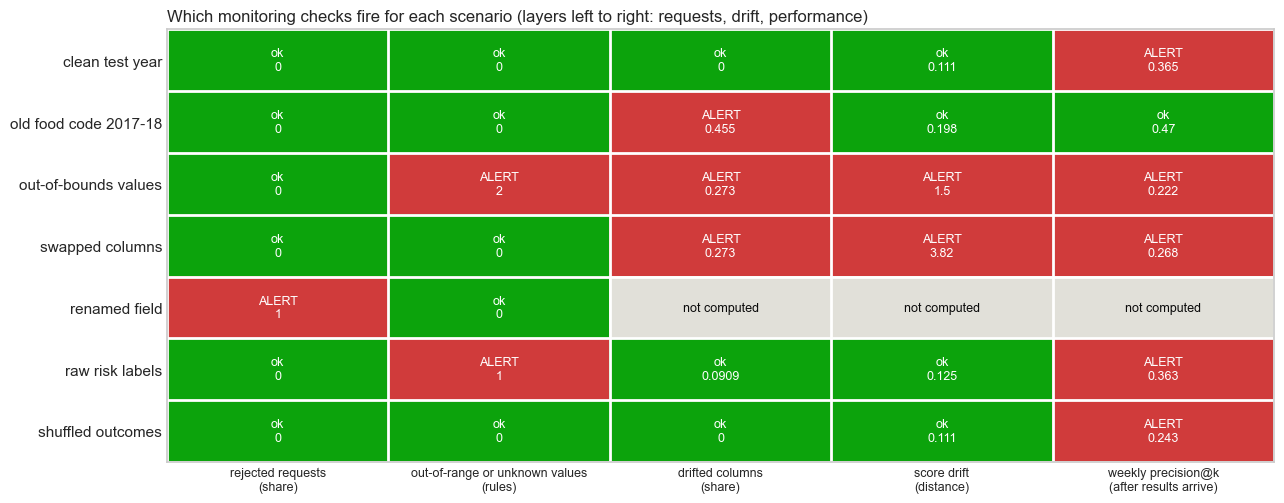

In [70]:
# This cell draws the alert matrix: one row per scenario, one column per check, red where the check
# fires and green where it stays quiet, with the measured value in each cell. Grey cells could not
# be computed, because the API rejected every request of that scenario. The figure is also saved to
# results/monitoring/alert_matrix.png.
from matplotlib.colors import ListedColormap

check_order = list(clean_checks["check"])
scenario_order = list(reports)
values = all_checks.pivot(index="scenario", columns="check", values="value").loc[scenario_order, check_order]
fired = all_checks.pivot(index="scenario", columns="check", values="alert").loc[scenario_order, check_order]
state = fired.astype(float).fillna(0.5)   # 0 quiet, 1 alert, 0.5 not computed

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.imshow(state.to_numpy(), cmap=ListedColormap(["#0ca30c", "#e1e0d9", "#d03b3b"]), vmin=0, vmax=1, aspect="auto")
for i, scenario in enumerate(scenario_order):
    for j, check_name in enumerate(check_order):
        value = values.loc[scenario, check_name]
        label = "not computed" if pd.isna(value) else ("ALERT" if fired.loc[scenario, check_name] else "ok") + f"\n{value:.3g}"
        ax.text(j, i, label, ha="center", va="center", fontsize=9, color="#0b0b0b" if pd.isna(value) else "white")
ax.set_xticks(range(len(check_order)), [name.replace(" (", "\n(") for name in check_order], fontsize=9)
ax.set_yticks(range(len(scenario_order)), scenario_order)
ax.set_xticks(np.arange(-0.5, len(check_order)), minor=True)
ax.set_yticks(np.arange(-0.5, len(scenario_order)), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
ax.set_title("Which monitoring checks fire for each scenario (layers left to right: requests, drift, performance)", loc="left")
fig.tight_layout()
fig.savefig(config.RESULTS_DIR / "monitoring" / "alert_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

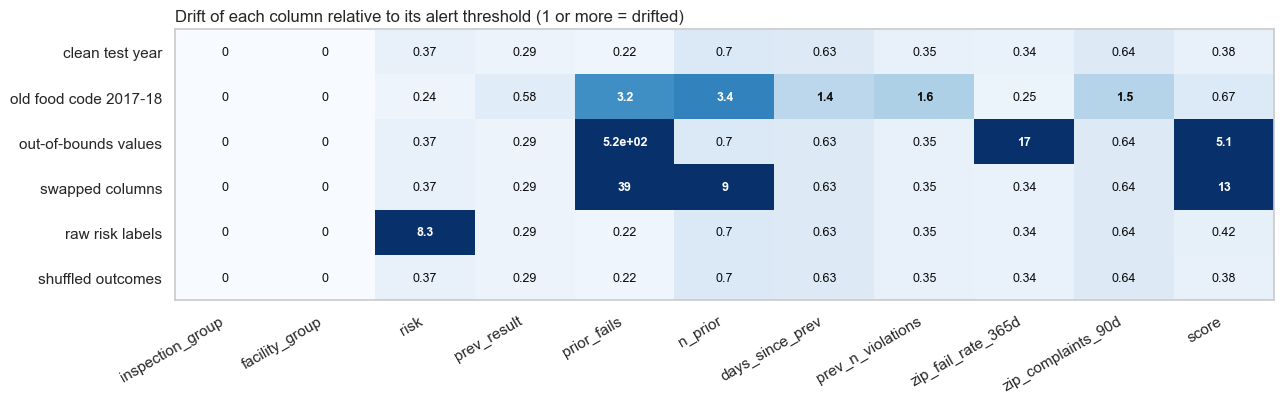

In [71]:
# This cell shows which columns Evidently flagged in each scenario: each column's drift score divided
# by its calibrated threshold, so 1 or more means the column drifted (marked in bold). Darker cells
# drifted more; ratios above 5 share the darkest color. The figure is also saved to
# results/monitoring/column_drift.png.
column_ratio = pd.DataFrame({name: monitoring.drift_scores(report).drop("drifted_share") / pd.Series(thresholds)
                             for name, report in reports.items() if report is not None}).T
column_ratio = column_ratio[[*config.FEATURE_COLUMNS[feature_version], "score"]]

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.imshow(column_ratio.clip(upper=5).to_numpy(), cmap="Blues", vmin=0, vmax=5, aspect="auto")
for i in range(column_ratio.shape[0]):
    for j in range(column_ratio.shape[1]):
        ratio = column_ratio.iloc[i, j]
        ax.text(j, i, f"{ratio:.2g}", ha="center", va="center", fontsize=9,
                fontweight="bold" if ratio >= 1 else "normal", color="white" if ratio >= 2.5 else "#0b0b0b")
ax.set_xticks(range(column_ratio.shape[1]), column_ratio.columns, rotation=30, ha="right")
ax.set_yticks(range(column_ratio.shape[0]), column_ratio.index)
ax.grid(False)
ax.set_title("Drift of each column relative to its alert threshold (1 or more = drifted)", loc="left")
fig.tight_layout()
fig.savefig(config.RESULTS_DIR / "monitoring" / "column_drift.png", dpi=150, bbox_inches="tight")
plt.show()

In [72]:
# This cell prints the alert log: every check that fired, in the order the monitor raised it, with
# its value, its limit and the detail an engineer would start from.
print(ALERT_LOG.read_text())

2026-11-25T18:56:01.945427+00:00 ALERT [clean test year] weekly precision@k (after results arrive): 0.365 (limit 0.403); validation 0.449; limit is 2 standard errors below it
2026-11-25T18:56:24.973868+00:00 ALERT [old food code 2017-18] drifted columns (share): 0.455 (limit 0.200); prior_fails, n_prior, days_since_prev, prev_n_violations, zip_complaints_90d
2026-11-25T18:56:28.025632+00:00 ALERT [out-of-bounds values] out-of-range or unknown values (rules): 2.000 (limit 0.000); range_prior_fails: 933 outside 0 to 200; range_zip_fail_rate_365d: 933 outside 0 to 1
2026-11-25T18:56:28.028636+00:00 ALERT [out-of-bounds values] drifted columns (share): 0.273 (limit 0.200); prior_fails, zip_fail_rate_365d, score
2026-11-25T18:56:28.035631+00:00 ALERT [out-of-bounds values] score drift (distance): 1.503 (limit 0.295); mean score 0.378 (reference 0.221)
2026-11-25T18:56:28.038628+00:00 ALERT [out-of-bounds values] weekly precision@k (after results arrive): 0.222 (limit 0.403); validation 0.44

**How the monitor caught each anomaly**

| Scenario | What fired | Reading |
|---|---|---|
| clean test year | performance only | the baseline: quiet data checks; precision below the validation-based limit, discussed above |
| old food code 2017-18 | drifted columns (5 of 11) | real data drift: before 2018 the inspection histories were shorter (the records start in 2010), so the history features were lower, and complaint inspections per ZIP code were more frequent. The ranking still worked (precision 0.470) and the score distribution stayed within its threshold: drift in the inputs does not always mean a worse model, which is why the monitor also checks performance before anyone retrains |
| out-of-bounds values | every layer | 933 rows broke the `prior_fails` and `zip_fail_rate_365d` range rules; both columns and the scores drifted (mean score 0.378 against 0.221) and precision fell to 0.222. The API accepted the requests, because the schema only checks types |
| swapped columns | drift, score drift, performance | the input rules pass (both columns hold plausible numbers), so only the distribution checks see it: `prior_fails` and `n_prior` drift, the mean score jumps to 0.620 and precision falls to 0.268. This is the case that needs the drift layer |
| renamed field | rejected requests | the API's schema rejects every batch with HTTP 422 (extra field `prior_failures`, missing `prior_fails`); the log keeps the rejected requests, so the cause can be read from it |
| raw risk labels | unknown categories (and performance) | the input rule lists the unknown values; Evidently flags the `risk` column on its own, which is under the 20% dataset limit. The API accepts the labels, and the model's encoder ignores unknown categories, so the risk feature silently stops counting; precision (0.363) is about the clean year's, so the performance alert here is the same one as in the baseline |
| shuffled outcomes | performance only | concept drift is invisible to every input and score check, because the inputs did not change; only the results, weeks later, show it (precision 0.243, close to random) |

Each layer catches something the others miss: the schema catches renamed fields, the input rules catch impossible and unknown values, the drift checks catch plausible-looking but wrong inputs (swapped columns) and real population change, and only the performance check catches concept drift.

#### Monitoring dashboard: the Evidently UI

Every report above is stored in the Evidently workspace in `monitoring/workspace/`. The self-hosted UI from the Session 7 lab serves it: the **Dashboard** tab plots the share of drifted columns, the drift of the returned scores and the drift of each numeric feature for every run, and the **Reports** tab opens any run's full report, with its failed tests marked. The cell below starts the UI in the background (on port 8001, since the API uses 8000); it keeps running until the notebook's kernel is shut down. From a terminal in the repository folder, the same UI starts with `evidently ui --workspace monitoring/workspace --port 8001`.

In [73]:
# This cell starts the Evidently UI on the workspace, at http://localhost:8001.
evidently_ui = subprocess.Popen([sys.executable, "-c", "from evidently.cli import app; app()", "ui",
                                 "--workspace", str(WORKSPACE_DIR), "--port", "8001"],
                                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
print("Evidently UI: http://localhost:8001 (project: InspectRank monitoring)")

Evidently UI: http://localhost:8001 (project: InspectRank monitoring)


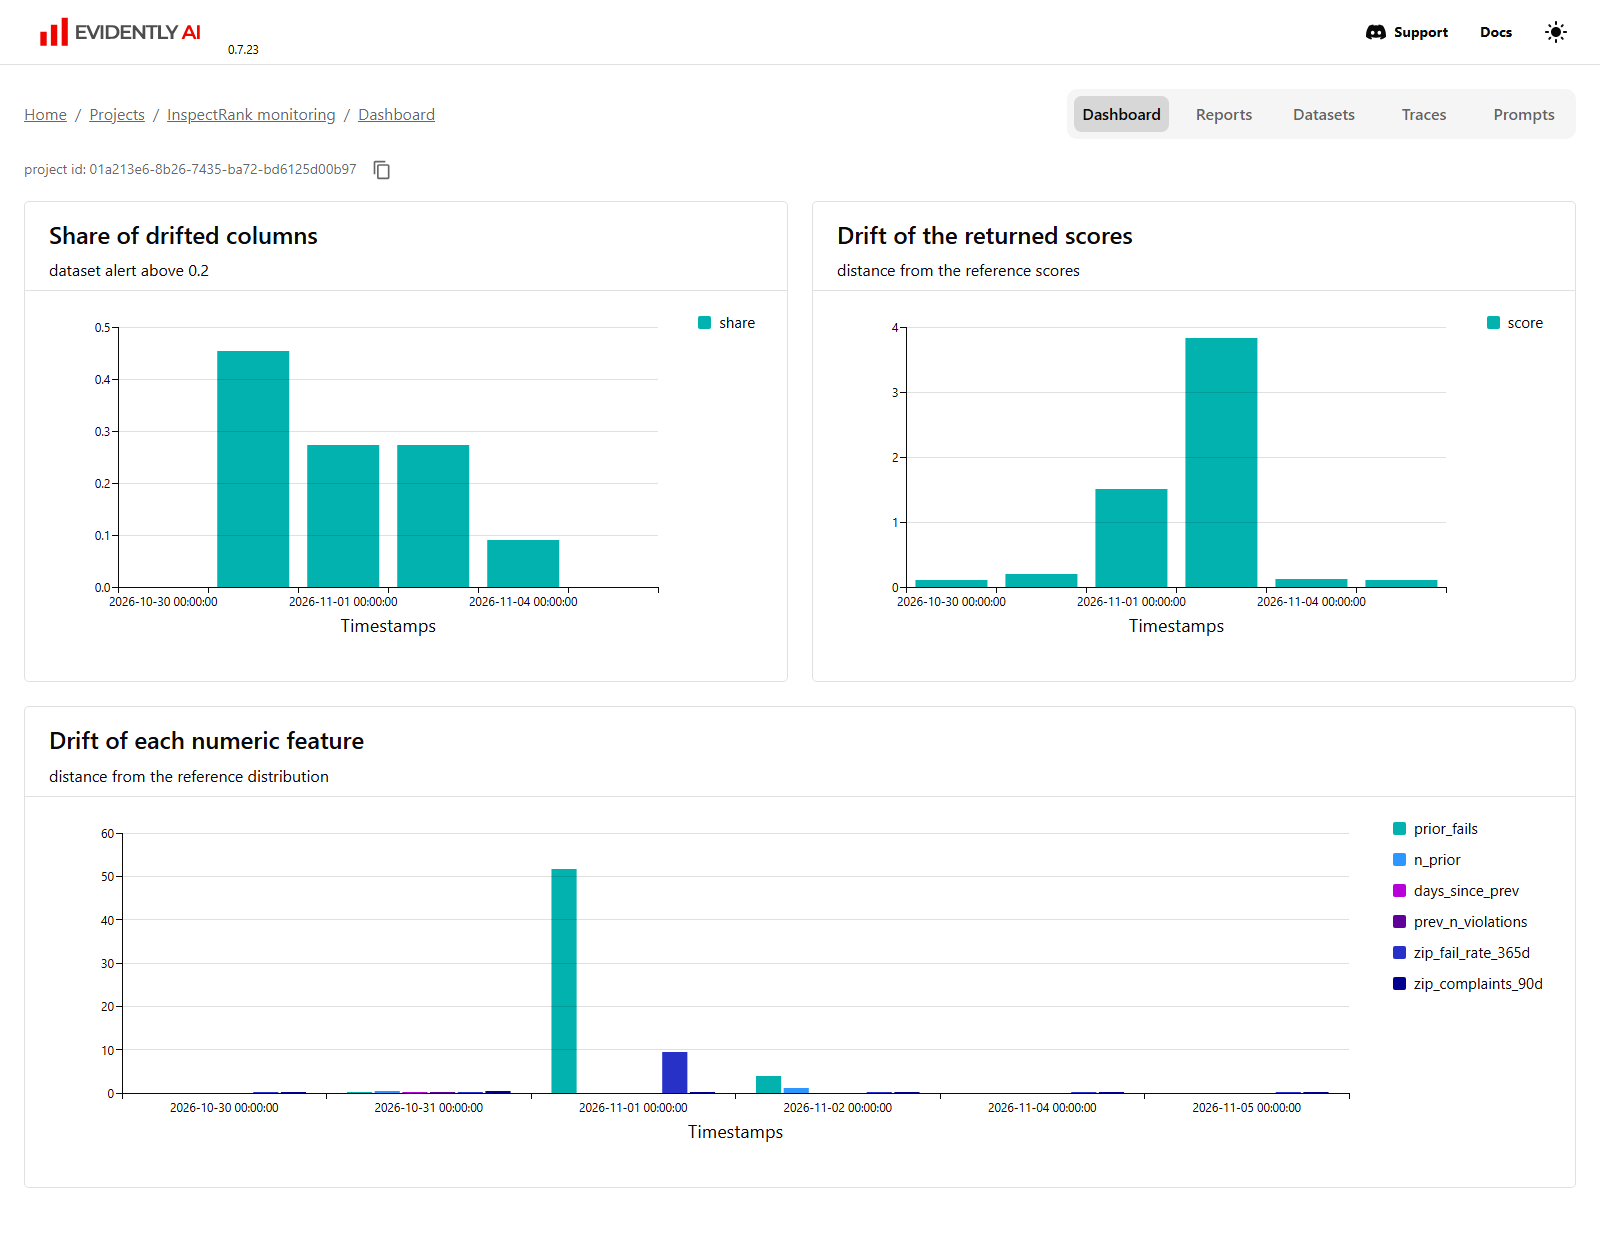

In [74]:
# This cell shows a screenshot of the Evidently dashboard for the runs above, saved to
# results/monitoring/evidently_dashboard.png. Runs are dated one day apart from October 30, 2026,
# in the order of the alert matrix (clean test year first); the renamed-field day has no run.
display(Image(filename=str(config.RESULTS_DIR / "monitoring" / "evidently_dashboard.png")))

#### Session 7b tools considered and not used

| Course tool or idea | What the project does instead | Reason |
|---|---|---|
| Prometheus and Grafana | an Evidently workspace and dashboard | the API answers one batch a week, so request rates and latency are not where problems would show; Evidently computes data and score drift, which Prometheus does not |
| Logging inside `serving/app.py` | the monitoring client logs every batch it sends and receives | keeps the API as deployed in Session 5; a server-side logger would write the same log |
| Weekly or monthly drift windows | one window per scenario (a year of weekly batches) | a week holds about 90 canvass inspections, too few for stable drift scores, and several features are seasonal: monthly windows of clean training data drift by up to 0.9 on `days_since_prev` |
| Email or Slack notifications | the alert log and Python logging warnings | a webhook would send the same lines as the alert log |
| Automatic retraining on an alert | not triggered | retraining is the Session 4 pipeline, whose gate decides on promotion; the old-food-code scenario shows drift without a performance loss, so retraining on every drift alert would be premature |

In [75]:
# This cell copies the new monitoring module and its tests into the Session 7b folder, so the
# session's files can be read in one place, and stops the API container.
Path("../Session 7b - Monitoring and drift simulation").mkdir(exist_ok=True)
for new_file in ["src/monitoring.py", "tests/test_monitoring.py"]:
    shutil.copy(Path("..") / new_file, Path("../Session 7b - Monitoring and drift simulation") / Path(new_file).name)
!docker stop inspection-ranker
sorted(path.name for path in Path("../Session 7b - Monitoring and drift simulation").iterdir())

inspection-ranker


['monitoring.py', 'test_monitoring.py']

### Session 8: Ethics and governance gates

Lecture 8 treated fairness and privacy as checks that belong in the pipeline rather than one-off analyses: a fairness check that runs as a gate whenever a model is retrained (alongside the accuracy gate in CI/CD and continuous training), privacy rules from laws such as GDPR and CCPA (collect and keep only the data the system needs), and logs that record metadata rather than personal data. It also introduced LLMOps. This section adds a fairness gate and a privacy check of the request log; the new module is copied into `Session 8 - Ethics and governance gates/`.

#### Fairness gate: `src/governance.py`

Session 6 compared the North and South Sides on the model's weekly picks with Fairlearn. The gate turns that comparison into a rule: it passes when the selection rate and the precision of the picks differ between the groups by at most 10 percentage points. The limit is a policy choice the city would set; the module states it in one constant.

In [76]:
%%writefile ../src/governance.py
"""Governance gates: a fairness gate on the weekly picks, and the privacy rule for logged requests.

The fairness gate turns the Session 6 Fairlearn check into a pass/fail rule. It ranks each week's
inspections, takes the top k as that week's visits, and compares two groups (for example the
North and South Sides) on two measures:

- selection rate: the share of each group's inspections that are picked (demographic parity)
- precision of the picks: the fail rate among each group's picked inspections

The gate passes when both gaps are at most `MAX_GAP`. The limit is a policy choice, set here at
10 percentage points; the production model's gaps on the validation year are about 3 and 2 points.

The privacy rule lists the only fields a request log may hold: the request ID and the model's
features, none of which names or locates a business.
"""

import pandas as pd

from src import config, metrics

MAX_GAP = 0.10   # largest allowed gap between groups, in selection rate and in precision of the picks

# Fields a logged request may contain: the client's ID for the inspection and the model's features.
LOGGABLE_FIELDS = {"facility_id", *config.FEATURE_COLUMNS["v1"], *config.FEATURE_COLUMNS["v2"]}


def weekly_picks(frame: pd.DataFrame, score_col: str, k: int) -> pd.Series:
    """True for the k highest-scoring inspections of each week, the visits the city would make."""
    week = metrics.weeks(frame["inspection_date"])
    return frame.groupby(week)[score_col].rank(method="first", ascending=False) <= k


def fairness_gate(frame: pd.DataFrame, group_col: str, k: int, score_col: str = "prediction",
                  max_gap: float = MAX_GAP) -> tuple[bool, pd.DataFrame, dict]:
    """Compare the groups in `group_col` on the weekly top-k picks.

    Returns whether the gate passed, a table per group (inspections, fail rate, selection rate,
    precision of the picks), and the gap between the groups for each measure.
    """
    picked = frame.assign(picked=weekly_picks(frame, score_col, k))
    table = picked.groupby(group_col).apply(lambda group: pd.Series({
        "inspections": len(group),
        "fail rate": group[config.TARGET].mean(),
        "selection rate": group["picked"].mean(),
        "precision of picks": group.loc[group["picked"], config.TARGET].mean(),
    }), include_groups=False)
    gaps = {measure: float(table[measure].max() - table[measure].min())
            for measure in ["selection rate", "precision of picks"]}
    return all(gap <= max_gap for gap in gaps.values()), table, gaps


def unloggable_fields(logged_fields) -> set[str]:
    """Fields in a request log that the privacy rule does not allow, such as names or addresses."""
    return set(logged_fields) - LOGGABLE_FIELDS

Overwriting ../src/governance.py

In [77]:
%%writefile ../tests/test_governance.py
"""Tests for src/governance.py: the fairness gate on the weekly picks and the privacy rule for logs."""

import numpy as np
import pandas as pd
import pytest

from src import governance


@pytest.fixture
def weekly() -> pd.DataFrame:
    """Four weeks of 20 inspections, half North and half South, with random scores and outcomes."""
    rng = np.random.default_rng(0)
    n = 80
    return pd.DataFrame({
        "inspection_date": pd.to_datetime("2026-01-05") + pd.to_timedelta(np.repeat(range(4), 20) * 7, unit="D"),
        "region": np.tile(["North", "South"], n // 2),
        "fail": rng.integers(0, 2, n),
        "prediction": rng.random(n),
    })


def test_weekly_picks_take_k_per_week(weekly):
    picked = governance.weekly_picks(weekly, "prediction", k=3)
    assert picked.groupby(weekly["inspection_date"]).sum().tolist() == [3, 3, 3, 3]


def test_gate_fails_a_ranking_that_picks_only_one_group(weekly):
    biased = weekly.assign(prediction=weekly["prediction"] + (weekly["region"] == "South"))
    passed, table, gaps = governance.fairness_gate(biased, "region", k=5)
    assert not passed
    assert table.loc["North", "selection rate"] == 0
    assert gaps["selection rate"] == pytest.approx(0.5)


def test_gate_passes_when_the_gaps_are_within_the_limit(weekly):
    passed, _, gaps = governance.fairness_gate(weekly, "region", k=5, max_gap=1.0)
    assert passed and set(gaps) == {"selection rate", "precision of picks"}


def test_privacy_rule_flags_names_and_addresses():
    assert governance.unloggable_fields({"facility_id", "risk", "dba_name", "address"}) == {"dba_name", "address"}

Overwriting ../tests/test_governance.py


In [78]:
# This cell runs the governance tests: the weekly picks, a biased ranking that fails the gate, a fair
# one that passes it, and the privacy rule.
!cd .. && {sys.executable} -m pytest tests/test_governance.py -v --no-header --disable-warnings

============================= test session starts =============================
collecting ... collected 4 items

tests/test_governance.py::test_weekly_picks_take_k_per_week PASSED       [ 25%]
tests/test_governance.py::test_gate_fails_a_ranking_that_picks_only_one_group PASSED [ 50%]
tests/test_governance.py::test_gate_passes_when_the_gaps_are_within_the_limit PASSED [ 75%]
tests/test_governance.py::test_privacy_rule_flags_names_and_addresses PASSED [100%]

======================== 4 passed, 1 warning in 5.86s =========================


In [79]:
# This cell applies the fairness gate three times: to the validation picks a retrain produces (the
# out-of-sample predictions in results/reference.parquet, by region as in Session 6), to the test
# year as the deployed API scored it (Session 7b), and to a deliberately biased ranking that adds
# 0.15 to every South Side score, which the gate should stop.
from src import governance

served_regions = add_slice_columns(served.copy())
served_regions = served_regions[served_regions["slice_region"] != "unknown"]
biased = fairness.assign(prediction=fairness["prediction"] + 0.15 * (fairness["slice_region"] == "south"))
gate_runs = {"validation year (retrain check)": (fairness, "prediction"),
             "test year, served by the API": (served_regions, "score"),
             "biased ranking (South + 0.15)": (biased, "prediction")}

gate_results = []
for name, (frame, score_col) in gate_runs.items():
    passed, by_region, gaps = governance.fairness_gate(frame, "slice_region", k_week, score_col=score_col)
    gate_results.append({"run": name, **{f"{region} selection rate": rate for region, rate in by_region["selection rate"].items()},
                         **{f"{measure} gap": gap for measure, gap in gaps.items()}, "gate passed": passed})
pd.DataFrame(gate_results).round(3)

,run,north selection rate,south selection rate,selection rate gap,precision of picks gap,gate passed
0,validation year (retrain check),0.070,0.099,0.029,0.019,True
1,"test year, served by the API",0.103,0.113,0.010,0.022,True
2,biased ranking (South + 0.15),0.031,0.195,0.164,0.084,False


The production model passes on both years, with gaps of 1 to 3 points against a limit of 10, and the biased ranking fails because it sends a much larger share of the South Side's inspections to the top of each week's list. In the retraining flow the gate belongs next to the promotion gate of Session 4: a challenger that beats the production model on precision but fails the fairness gate is not registered. `pipeline.py` is left as it is; adding the gate there is one call to `governance.fairness_gate` on the reference rows the flow already writes.

#### Privacy rules for logs

The request log from Session 7b records what the API received and returned, so it must hold no personal or identifying data. The rules:

- a log line holds a request ID, the model's version and the model's features, never a business name, address or license number (the features describe inspection history and the ZIP code's recent results, not who the business is)
- the API's schema already rejects any field it does not define (Session 7a tests this with `dba_name`)
- logs stay out of git (`monitoring/` is ignored) and the audit log in Session 9 keeps only metadata, not feature values

In [80]:
# This cell checks the request log against the privacy rule: it collects every field name that
# appears in a logged request and lists any the rule does not allow, by scenario.
logged_fields = request_log.drop(columns=["scenario", "week", "status", "score"])
{scenario: sorted(governance.unloggable_fields(rows.dropna(axis=1, how="all").columns))
 for scenario, rows in logged_fields.groupby(request_log["scenario"], sort=False)}

{'clean test year': [],
 'old food code 2017-18': [],
 'out-of-bounds values': [],
 'swapped columns': [],
 'renamed field': ['prior_failures'],
 'raw risk labels': [],
 'shuffled outcomes': []}

Only the renamed-field scenario breaks the rule, with `prior_failures`. The field is harmless here, but the finding is real: the monitor logs rejected requests exactly as they arrive, so a client that sent a business name would put it in the log even though the API rejects the request. The fix is to log only the field names of a rejected request, not its values; the check above is what would catch the problem in production.

#### LLMOps

Session 8 also introduced LLMOps: prompt versioning, evaluation of generated text, guardrails and cost tracking for large language models. An LLM could add value here by summarizing the free-text violation comments of a restaurant's earlier inspections for the inspector who visits next. It is out of scope: the comments are only known after an inspection, so they cannot feed the ranking without leaking the outcome, and summaries shown to inspectors would need their own evaluation for accuracy and tone.

In [81]:
# This cell copies the governance module and its tests into the Session 8 folder.
Path("../Session 8 - Ethics and governance gates").mkdir(exist_ok=True)
for new_file in ["src/governance.py", "tests/test_governance.py"]:
    shutil.copy(Path("..") / new_file, Path("../Session 8 - Ethics and governance gates") / Path(new_file).name)
sorted(path.name for path in Path("../Session 8 - Ethics and governance gates").iterdir())

['governance.py', 'test_governance.py']

### Session 9: MLOps in practice

Lecture 9 covered running ML systems in an organization: structured audit logs that show which model answered which request, translating model metrics into the measure the business uses, security, and reproducibility. This section adds an audit log, the precision@k result in inspection terms, a security check and a reproducibility checklist; the new files are in `Session 9 - MLOps in practice/`.

#### Audit log: `src/audit.py`

The audit log has one JSON record per request batch: a request ID (a hash of the request, so a record can be matched to the request log), the time, the HTTP status, the number of facilities, the model version the API returned, and the deployed model's lineage (registry version, data version tag, git commit). It holds no feature values.

In [82]:
%%writefile ../src/audit.py
"""Structured audit log: one JSON record per request batch the prediction API received.

Each record answers "which model, trained on which data and code, answered which request":
the request ID, the time, the HTTP status, the number of facilities, the model version the API
returned, and the lineage of the deployed model (registry version, data version tag, git commit).
The request ID is a hash of the request body, so the same request always has the same ID and a
record can be matched to the request log without copying any feature values into the audit log.
"""

import hashlib
import json
from pathlib import Path


def request_id(request: list[dict]) -> str:
    """A stable ID for a request: the first 16 hex digits of the SHA-256 hash of its JSON body."""
    return hashlib.sha256(json.dumps(request, sort_keys=True).encode()).hexdigest()[:16]


def audit_records(request_log: Path, version_info: dict) -> list[dict]:
    """One audit record per batch in the monitoring request log, with the deployed model's lineage."""
    records = []
    for line in Path(request_log).read_text().splitlines():
        batch = json.loads(line)
        records.append({
            "time": batch["time"],
            "request_id": request_id(batch["request"]),
            "scenario": batch["scenario"],
            "week": batch["week"],
            "status": batch["status"],
            "facilities": len(batch["request"]),
            "model_version": batch["response"].get("model_version"),   # None when the request was rejected
            "model_name": version_info["model_name"],
            "registry_version": version_info["registry_version"],
            "data_version": version_info["data_tag"],
            "git_commit": version_info["git_commit"],
        })
    return records


def write_audit_log(records: list[dict], path: Path) -> None:
    """Write the records as JSON lines, one record per line."""
    Path(path).write_text("".join(json.dumps(record) + "\n" for record in records))

Overwriting ../src/audit.py


In [83]:
%%writefile ../tests/test_audit.py
"""Tests for src/audit.py: audit records carry the request ID and the model lineage, not the data."""

import json

from src import audit

VERSION_INFO = {"model_name": "inspection-ranker", "registry_version": 1, "semver": "1.0.0",
                "data_tag": "data-v2", "git_commit": "abc123"}


def test_audit_records_carry_lineage_but_no_feature_values(tmp_path):
    request = [{"facility_id": "1", "risk": "high", "prior_fails": 2}]
    lines = [{"time": "t1", "scenario": "s", "week": "w", "status": 200, "request": request,
              "response": {"model_version": "1.0.0", "results": []}},
             {"time": "t2", "scenario": "s", "week": "w", "status": 422, "request": request,
              "response": {"detail": []}}]
    log = tmp_path / "requests.jsonl"
    log.write_text("".join(json.dumps(line) + "\n" for line in lines))
    accepted, rejected = audit.audit_records(log, VERSION_INFO)
    assert accepted["request_id"] == rejected["request_id"] == audit.request_id(request)
    assert accepted["model_version"] == "1.0.0" and rejected["model_version"] is None
    assert accepted["data_version"] == "data-v2" and "risk" not in accepted

Overwriting ../tests/test_audit.py


In [84]:
# This cell runs the audit log test.
!cd .. && {sys.executable} -m pytest tests/test_audit.py -v --no-header --disable-warnings

============================= test session starts =============================
collecting ... collected 1 item

tests/test_audit.py::test_audit_records_carry_lineage_but_no_feature_values PASSED [100%]

======================== 1 passed, 1 warning in 0.63s =========================


In [85]:
# This cell writes the audit log for every batch the API received in Session 7b to
# monitoring/audit.jsonl, then shows its first records and the count of batches by scenario and status.
from src import audit

audit_rows = audit.audit_records(REQUEST_LOG, version_info)
audit.write_audit_log(audit_rows, monitoring.MONITORING_DIR / "audit.jsonl")
audit_table = pd.DataFrame(audit_rows)
display(audit_table.head(3))
audit_table.groupby(["scenario", "status"], sort=False).size().rename("batches").to_frame()

,time,request_id,scenario,week,status,facilities,model_version,model_name,registry_version,data_version,git_commit
0,2026-11-25T18:55:55.043871+00:00,bb5bc8d9ecd24564,clean test year,2025-10-27/2025-11-02,200,39,1.0.0,inspection-ranker,1,data-v2,8e48534ef1ab4a8471078f78c4c122effbaa6a3b
1,2026-11-25T18:55:55.113433+00:00,36973aa2bfe95bfc,clean test year,2025-11-03/2025-11-09,200,134,1.0.0,inspection-ranker,1,data-v2,8e48534ef1ab4a8471078f78c4c122effbaa6a3b
2,2026-11-25T18:55:55.176224+00:00,29787097298fd74c,clean test year,2025-11-10/2025-11-16,200,95,1.0.0,inspection-ranker,1,data-v2,8e48534ef1ab4a8471078f78c4c122effbaa6a3b


,,batches
scenario,status,
clean test year,200,53
old food code 2017-18,200,52
out-of-bounds values,200,53
swapped columns,200,53
renamed field,422,53
raw risk labels,200,53
shuffled outcomes,200,53


#### What the metric means for the city

Weekly precision@k is the share of the 9 reorderable visits a week that find a failing restaurant. The cell below turns it into failures found over the test year, from the same visits ordered three ways.

In [86]:
# This cell turns weekly precision@k on the test year into failures found: the 9 visits a week over
# the test year's weeks, ordered by the model, by the simple rule "most earlier fails first", and at
# random, and the extra failures the model finds with the same number of visits.
kpi = []
for name in ["production model", "most earlier fails first", "random order"]:
    precision, visits = metrics.weekly_precision_at_k(served["fail"], orderings[name], served["inspection_date"], k_week)
    kpi.append({"ordering": name, "visits": visits, "weekly precision@k": precision,
                "failures found": round(precision * visits), "failures per week": precision * k_week,
                "failures per 100 visits": 100 * precision})
kpi = pd.DataFrame(kpi).set_index("ordering")
kpi["extra failures vs random"] = kpi["failures found"] - kpi.loc["random order", "failures found"]
kpi.round(2)

,visits,weekly precision@k,failures found,failures per week,failures per 100 visits,extra failures vs random
ordering,,,,,,
production model,477,0.36,174,3.28,36.48,66
most earlier fails first,477,0.30,144,2.72,30.19,36
random order,477,0.23,108,2.04,22.64,0


With the same 477 visits over the test year, the model's ordering finds about 66 more failing restaurants than random selection and about 30 more than the simple rule of visiting the restaurants with the most earlier fails first: roughly one extra failure found per week, or 14 more per 100 visits than random. Each of those is a restaurant with a food safety problem found weeks earlier than a random schedule would find it.

#### Security

| Risk | How the project handles it |
|---|---|
| Malformed or unexpected requests | the API's pydantic schema checks every field's type and rejects unknown fields (HTTP 422, Sessions 7a and 7b) |
| Plausible-looking but impossible values | the schema does not check ranges; the monitor's input rules (`validate.validate_features`) flag values outside plausible ranges and unknown categories (Session 7b) |
| Credentials in the repository | the DVC remote's service-account key and local settings stay out of git (`*service-account*.json`, `.env`, `.dvc/config.local`); no notebook holds a token |
| The running service | the container runs as a non-root user and exposes only port 8000 (`Dockerfile`) |

In [87]:
# This cell checks that no credential files are tracked by git: it lists tracked files whose names
# look like secrets, and asks git whether the usual secret files would be ignored.
import fnmatch

tracked = subprocess.run(["git", "ls-files"], cwd="..", capture_output=True, text=True).stdout.splitlines()
secret_patterns = ["*.env", ".env", "*service-account*", "*client_secret*", "*.pem", "*.key", "*config.local"]
print("tracked files that look like secrets:", [f for f in tracked if any(fnmatch.fnmatch(Path(f).name, p) for p in secret_patterns)])
ignored = subprocess.run(["git", "check-ignore", ".env", "dvc-service-account.json", ".dvc/config.local"],
                         cwd="..", capture_output=True, text=True).stdout.split()
print("ignored by git:", ignored)

tracked files that look like secrets: []
ignored by git: ['.env', 'dvc-service-account.json', '.dvc/config.local']


In [88]:
# This cell copies the audit module and its test into the Session 9 folder.
Path("../Session 9 - MLOps in practice").mkdir(exist_ok=True)
for new_file in ["src/audit.py", "tests/test_audit.py"]:
    shutil.copy(Path("..") / new_file, Path("../Session 9 - MLOps in practice") / Path(new_file).name)
sorted(path.name for path in Path("../Session 9 - MLOps in practice").iterdir())

['audit.py', 'test_audit.py']

#### Reproducibility checklist

The checklist is saved to the Session 9 folder.

In [89]:
%%writefile "../Session 9 - MLOps in practice/reproducibility_checklist.md"
# Reproducibility checklist

| Item | How the project handles it | Where |
|---|---|---|
| Code version | every MLflow run and the exported model record the git commit, and whether the code had uncommitted changes | `src/tracking.py`, `serving/model/version.json` |
| Data version | DVC tags `data-v1` and `data-v2` restore each data version; `dvc.lock` holds the hash of every stage's inputs and outputs | `dvc.yaml`, `dvc.lock` |
| Split integrity | each split's content hash is in the split manifest and is checked every time `load_split` reads it; the test split needs `allow_test=True` | `src/split.py`, `data/processed/split_manifest.json` |
| Random seeds | one seed (`config.SEED = 42`) for the AutoML search, tie-breaking in the metric, sampling and the drift scenarios | `src/config.py` |
| Fixed dates | the snapshot end, the split dates and the food code change date are constants | `src/config.py` |
| Model lineage | the registry version carries a semantic version tag and lineage tags (data tag, DVC fingerprint of the splits, git commit) | `src/registry.py`, MLflow |
| Dependencies | the serving image pins exact versions; the project's `requirements.txt` sets minimum versions, with upper limits where a library breaks (pandas below 3, xgboost below 3, Evidently below 0.8) | `serving/requirements.txt`, `requirements.txt` |
| Environment | the API runs in a Docker image from a pinned base image (`python:3.13-slim`); tests run on Python 3.12 in continuous integration | `Dockerfile`, `.github/workflows/tests.yml` |
| Regression checks | unit tests on every push, and a golden dataset that checks the production model's scores are unchanged | `tests/` |
| End-to-end rebuild | without an exported model, `app/app.ipynb` re-runs the training pipeline into `rebuild/`, which registers the same model (1.0.0, validation weekly precision@k 0.449) | `app/app.ipynb`, Session 5 |

Writing ../Session 9 - MLOps in practice/reproducibility_checklist.md


In [90]:
# This cell shows the reproducibility checklist.
display(Markdown(Path("../Session 9 - MLOps in practice/reproducibility_checklist.md").read_text()))

# Reproducibility checklist

| Item | How the project handles it | Where |
|---|---|---|
| Code version | every MLflow run and the exported model record the git commit, and whether the code had uncommitted changes | `src/tracking.py`, `serving/model/version.json` |
| Data version | DVC tags `data-v1` and `data-v2` restore each data version; `dvc.lock` holds the hash of every stage's inputs and outputs | `dvc.yaml`, `dvc.lock` |
| Split integrity | each split's content hash is in the split manifest and is checked every time `load_split` reads it; the test split needs `allow_test=True` | `src/split.py`, `data/processed/split_manifest.json` |
| Random seeds | one seed (`config.SEED = 42`) for the AutoML search, tie-breaking in the metric, sampling and the drift scenarios | `src/config.py` |
| Fixed dates | the snapshot end, the split dates and the food code change date are constants | `src/config.py` |
| Model lineage | the registry version carries a semantic version tag and lineage tags (data tag, DVC fingerprint of the splits, git commit) | `src/registry.py`, MLflow |
| Dependencies | the serving image pins exact versions; the project's `requirements.txt` sets minimum versions, with upper limits where a library breaks (pandas below 3, xgboost below 3, Evidently below 0.8) | `serving/requirements.txt`, `requirements.txt` |
| Environment | the API runs in a Docker image from a pinned base image (`python:3.13-slim`); tests run on Python 3.12 in continuous integration | `Dockerfile`, `.github/workflows/tests.yml` |
| Regression checks | unit tests on every push, and a golden dataset that checks the production model's scores are unchanged | `tests/` |
| End-to-end rebuild | without an exported model, `app/app.ipynb` re-runs the training pipeline into `rebuild/`, which registers the same model (1.0.0, validation weekly precision@k 0.449) | `app/app.ipynb`, Session 5 |
